# Imports

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patheffects as pe
import pickle
import os
import glob
import seaborn as sns
from project_support.csv_runs import load_notebook_csv_path


In [3]:
import ast
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import Normalize,  TwoSlopeNorm
from matplotlib.cm import ScalarMappable


## df

In [4]:
df = pd.read_parquet(r'bert_trainset_squared_25.gzip')
print(df.shape)
df_uniques = [val for val in df['position_state'].unique()]
df['position_state_id'] = df.groupby('position_state').transform('ngroup')
print(len(df_uniques))
df.head(2)

(13134, 11)
947


,t,pos,distance_travelled,vel,rot_vel,head_direction,position_state,position_state_id,normalized_position_state_id,last_position_state_id,change_of_position_state
0,0.75,"[0.7, 0.89]",0.070249,"[-0.04648240511472945, -0.103916968250235]",-0.721635,"[-0.3147863504974622, -0.949162553802292]",XYCOAOWPMOWWNFTUVQEX,864,1.022175,973.0,1
1,0.80,"[0.699, 0.885]",0.075165,"[-0.02934323295077368, -0.09384195961539277]",2.351097,"[-0.3093471255142001, -0.9509491868318211]",XYCOAOWPMOWWNFTUKDZD,863,1.021119,968.0,1


In [4]:
df[['position_state_id', 'position_state']].nunique()

position_state_id    947
position_state       947
dtype: int64

## apd

In [175]:
ziped_apd = False

In [176]:
# if ziped_apd:
#     apd = pd.read_parquet('legacy/datasets/apd_ziped.gzip')
# else:
#     # apd = pd.read_parquet('legacy/datasets/apd_full.gzip')
#     pass

In [177]:
# print(apd.shape)
# apd_uniques = [val for val in apd['position_state'].unique()]
# print(len(apd_uniques))
# apd.head(2)

## ps_to_psid

In [178]:
# if 'position_state_id' not in apd.columns:
#     with open('ps_to_psid.pkl', 'rb') as file:
#         ps_to_psid = pickle.load(file)

In [179]:
# if 'position_state_id' not in apd.columns:
#     apd['position_state_id'] = [ps_to_psid[k] for k in apd['position_state']]

## cossim

### pre train

In [42]:
coss_pre_train = pd.read_csv(load_notebook_csv_path('gpt_squared', "cosine_similarity_matrix_gpt_pre_train.csv"),)
print(coss_pre_train.shape)
coss_pre_train.head(5)

(948, 948)


,0,1,2,3,4,5,6,7,8,9,...,938,939,940,941,942,943,944,945,946,947
0,1.000000,0.295149,-0.392137,0.402140,0.269813,0.109934,0.424900,-0.565573,-0.112184,0.058589,...,0.327795,0.152695,-0.364567,-0.135803,-0.049202,-0.263013,0.088347,0.154233,-0.000592,0.0
1,0.295149,1.000000,-0.103022,-0.132720,0.271136,0.255487,0.439798,-0.050666,-0.252736,-0.366148,...,0.385497,-0.008867,-0.359942,-0.158567,0.125111,0.057991,0.079074,0.002080,-0.173715,0.0
2,-0.392137,-0.103022,1.000000,-0.499664,-0.187916,-0.409724,-0.127791,-0.073598,0.430466,-0.074657,...,-0.018408,-0.207218,-0.232249,-0.196644,-0.189069,0.154925,-0.144479,-0.517041,0.150882,0.0
3,0.402140,-0.132720,-0.499664,1.000000,-0.205195,0.349728,0.161132,-0.217847,-0.114976,0.286780,...,-0.311664,0.034705,0.312270,-0.065579,0.130465,0.041397,0.008107,0.193886,0.062286,0.0
4,0.269813,0.271136,-0.187916,-0.205195,1.000000,0.089619,-0.182395,-0.149737,-0.573676,0.184883,...,0.121913,0.010048,-0.419257,-0.260526,0.145992,-0.393226,0.175817,0.300255,0.153670,0.0


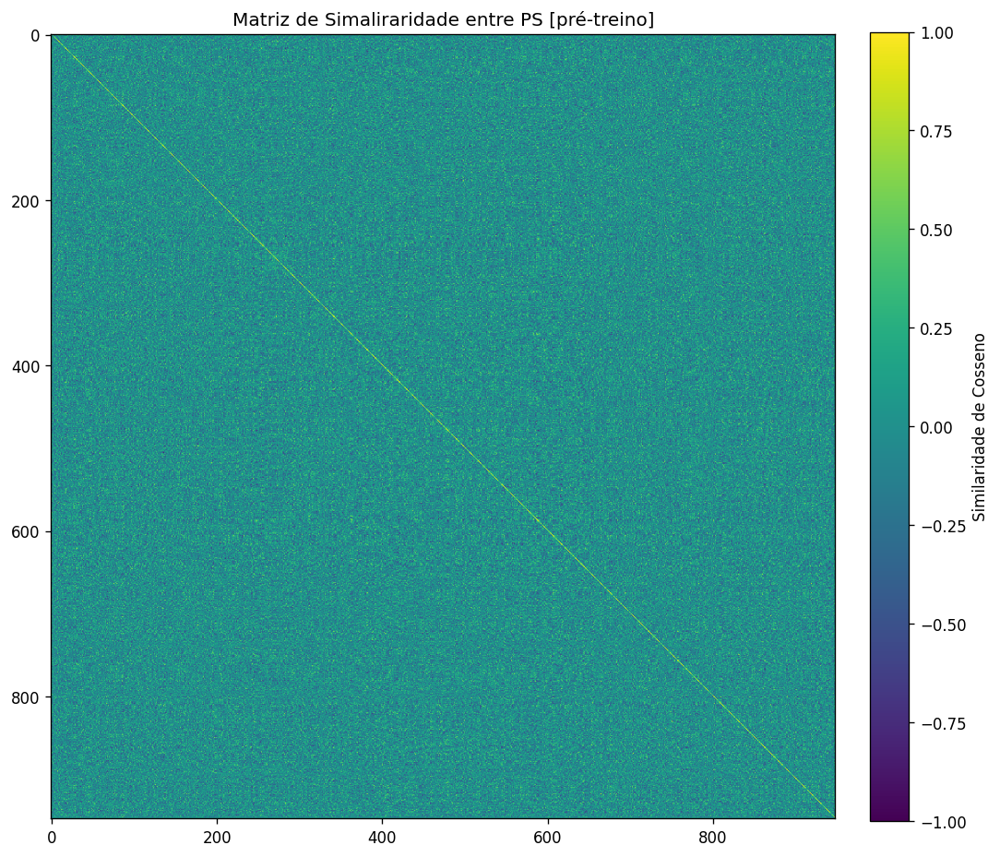

In [47]:
fig, ax = plt.subplots(figsize=(10, 10), dpi=120, )
p = plt.imshow(coss_pre_train,  vmin=-1, vmax=1)
cbar = plt.colorbar(p, fraction=0.046, pad=0.04,)
plt.title('Matriz de Simaliraridade entre PS [pré-treino]')
cbar.set_label("Similaridade de Cosseno")
plt.show()

### mid train

In [48]:
coss_train_250 = pd.read_csv(load_notebook_csv_path('gpt_squared', "cosine_similarity_matrix_gpt_train_epoch_249.csv"),)
print(coss_train_250.shape)
coss_train_250.head(5)

(948, 948)


,0,1,2,3,4,5,6,7,8,9,...,938,939,940,941,942,943,944,945,946,947
0,1.000000,0.325394,-0.205858,0.288539,0.412082,0.224774,0.423351,-0.278256,0.039197,0.254166,...,-0.022887,0.128623,-0.448790,-0.273520,-0.200992,-0.186814,0.279516,0.077785,0.034239,0.0
1,0.325394,1.000000,-0.123127,-0.096716,0.363985,0.139181,0.411374,-0.192168,-0.174353,-0.094841,...,0.090728,0.148012,-0.046478,-0.034052,0.066443,-0.286238,0.095604,0.152298,-0.452730,0.0
2,-0.205858,-0.123127,1.000000,-0.182201,-0.056682,0.028415,-0.310302,-0.268241,-0.087433,-0.005031,...,-0.228213,-0.091324,0.037402,-0.209066,-0.133816,0.118279,-0.267490,-0.188765,0.160147,0.0
3,0.288539,-0.096716,-0.182201,1.000000,0.004147,0.536140,0.196694,-0.163821,-0.085896,0.428387,...,-0.265127,0.233808,0.233651,0.100524,0.023518,0.027428,-0.167195,-0.020777,0.037063,0.0
4,0.412082,0.363985,-0.056682,0.004147,1.000000,0.079788,0.185795,-0.257953,-0.241140,0.268016,...,-0.052627,0.021924,-0.350662,-0.214745,0.222285,-0.642927,0.238077,0.002330,-0.008261,0.0


In [ ]:
fig, ax = plt.subplots(figsize=(10, 10), dpi=120, )
p = plt.imshow(coss_pre_train,  vmin=-1, vmax=1)
cbar = plt.colorbar(p, fraction=0.046, pad=0.04,)
plt.title('Matriz de Simaliraridade entre PS [pré-treino]')
cbar.set_label("Similaridade de Cosseno")
plt.show()

### after train

In [9]:
coss = pd.read_csv(load_notebook_csv_path('gpt_squared', "cosine_similarity_matrix_gpt.csv"),)
print(coss.shape)
coss.head(5)

(948, 948)


,0,1,2,3,4,5,6,7,8,9,...,938,939,940,941,942,943,944,945,946,947
0,1.000000,0.171185,-0.335778,-0.521062,0.027710,-0.329268,0.006377,0.222520,0.091066,0.358686,...,0.581107,0.218922,0.340535,0.377954,0.457848,0.219857,0.022161,0.032298,0.206431,0.0
1,0.171185,1.000000,0.151161,0.118775,0.233446,0.392442,0.531802,0.411110,0.436127,0.318595,...,0.411179,0.147182,-0.073991,-0.115112,0.379853,0.398829,0.034472,-0.086606,0.321548,0.0
2,-0.335778,0.151161,1.000000,0.563939,0.646096,0.570561,0.231787,-0.066813,0.268237,0.018568,...,-0.430946,0.333073,0.316297,0.005124,0.168882,0.136032,0.292182,-0.028954,-0.187132,0.0
3,-0.521062,0.118775,0.563939,1.000000,0.393394,0.558316,0.212102,0.027054,0.067189,-0.257234,...,-0.296524,0.070854,0.112785,-0.258006,-0.023821,0.346232,0.128564,-0.210082,0.000025,0.0
4,0.027710,0.233446,0.646096,0.393394,1.000000,0.483848,0.356893,0.418407,0.566635,0.453237,...,-0.112003,0.298046,0.335691,0.034476,0.497638,0.388311,0.236215,0.111203,0.089574,0.0


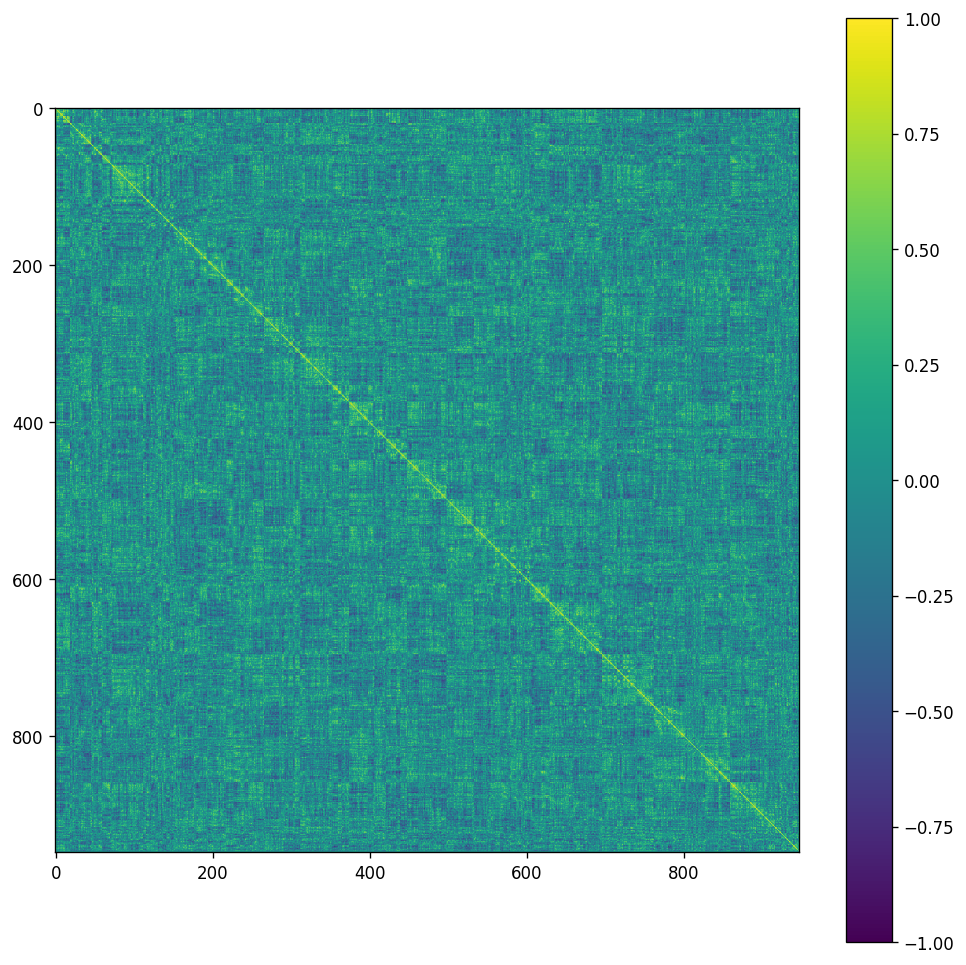

In [10]:
fig, ax = plt.subplots(figsize=(10, 10), dpi=120, )
p = plt.imshow(coss,  vmin=-1, vmax=1)
plt.colorbar(p,)
plt.show()

<Axes: xlabel='287', ylabel='Count'>

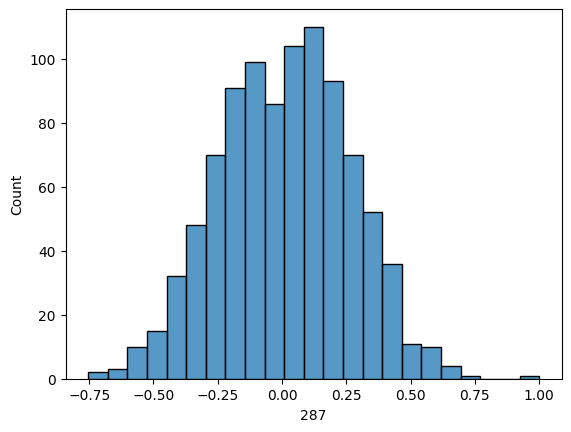

In [11]:
sns.histplot(coss['287'])

In [12]:
coss.sort_values(['287'], ascending=False).index[1:4]

Index([170, 282, 817], dtype='int64')

## heads

In [184]:
head0 = pd.read_csv(load_notebook_csv_path('gpt_squared', "head0_cosine_similarity_gpt.csv"))
print(head0.shape)
# head1 = pd.read_csv(load_notebook_csv_path('gpt_squared', "head1_cosine_similarity_gpt.csv"))
# print(head1.shape)
# head1.head()

(438, 438)


## heat att

In [185]:
head0_att = pd.read_csv(load_notebook_csv_path('gpt_squared', "head0_attention_softmax_gpt_with_vis.csv"),)
# head0_att.drop('947', axis=1, inplace=True)
# head0_att.drop(947, inplace=True)
print(head0_att.shape)

(438, 438)


## head attn w pos softmax

In [186]:
head0_att_pos_softmax = pd.read_csv(load_notebook_csv_path('gpt_squared', f"head0_softmax_pos0_to_pos1_gpt_with_vis.csv"), )
print(head0_att_pos_softmax.shape)



# head1_att_pos_softmax.head()

(438, 438)


## head attn w pos logit

In [187]:
head0_att_pos_logit = pd.read_csv(load_notebook_csv_path('gpt_squared', f"head0_logit_pos0_to_pos1_gpt_with_vis.csv"), )
print(head0_att_pos_logit.shape)

(438, 438)


## head attn w pos cossine

In [188]:
head0_att_pos_coss = pd.read_csv(load_notebook_csv_path('gpt_squared', f"head0_cosine_pos0_to_pos1_gpt_with_vis.csv"), )
print(head0_att_pos_coss.shape)

(438, 438)


## distribs probs

In [5]:
distribs_probs = pd.read_csv(load_notebook_csv_path('gpt_squared', 'gpt_probs_distribs_780.csv'),)
print(distribs_probs.shape)
distribs_probs.head(2)

(948, 10)


,Passo 01,Passo 02,Passo 03,Passo 04,Passo 05,Passo 06,Passo 07,Passo 08,Passo 09,Passo 10
0,2.598972e-17,2.493726e-14,1.383213e-13,3.338092e-11,4.016604e-05,0.000004,6.472213e-09,0.000019,0.000019,0.000019
1,2.681792e-15,2.477439e-12,5.376502e-14,1.601375e-10,9.529092e-14,0.000001,3.285838e-07,0.000002,0.000002,0.000002


In [7]:
distribs_probs360 = pd.read_csv(load_notebook_csv_path('gpt_squared', 'gpt_probs_distribs_780.csv'),)
print(distribs_probs360.shape)
distribs_probs360.head(2)

(948, 10)


,Passo 01,Passo 02,Passo 03,Passo 04,Passo 05,Passo 06,Passo 07,Passo 08,Passo 09,Passo 10
0,2.598972e-17,2.493726e-14,1.383213e-13,3.338092e-11,4.016604e-05,0.000004,6.472213e-09,0.000019,0.000019,0.000019
1,2.681792e-15,2.477439e-12,5.376502e-14,1.601375e-10,9.529092e-14,0.000001,3.285838e-07,0.000002,0.000002,0.000002


## distrib logits

In [8]:
distribs_logits = pd.read_csv(load_notebook_csv_path('gpt_squared', 'gpt_logits_distribs_780.csv'),)
print(distribs_logits.shape)
distribs_logits.head(2)

(948, 10)


,Passo 01,Passo 02,Passo 03,Passo 04,Passo 05,Passo 06,Passo 07,Passo 08,Passo 09,Passo 10
0,-12.450484,-6.531984,-7.382321,0.649678,15.439601,12.665284,5.018986,10.822005,10.822005,10.822005
1,-7.813944,-1.933366,-8.327278,2.217725,-4.419752,11.635358,8.946260,8.603036,8.603036,8.603036


## raw logits

In [21]:
distribs_raw_logits = pd.read_csv(load_notebook_csv_path('gpt_squared', 'gpt_logits_raw_distribs_780.csv'),)
print(distribs_raw_logits.shape)
distribs_raw_logits.head(2)

(948, 10)


,Passo 01,Passo 02,Passo 03,Passo 04,Passo 05,Passo 06,Passo 07,Passo 08,Passo 09,Passo 10
0,-12.450484,-6.531984,-7.382321,0.649678,15.439601,12.665284,5.018986,10.822005,10.822005,10.822005
1,-7.813944,-1.933366,-8.327278,2.217725,-4.419752,11.635358,8.946260,8.603036,8.603036,8.603036


# An

## funcs

In [91]:
def plot_position_states_w_title(
    apd: pd.DataFrame,
    grupos_destacados,
    title: str = None,
    cor_outros: str = "#e0e0e0",   # pontos não destacados
    s_outros: int = 10,
    s_destacados: int = 28,
    annotate: bool = True,
    cmap_name: str = "viridis",
):
    """
    Plota os pontos do DataFrame 'apd' (colunas: X, Y, position_state_id),
    destacando 'grupos_destacados' com cores oriundas do colormap viridis,
    respeitando a ordem de aparecimento na lista:

    - ids ANTERIORES: recebem as primeiras cores do colormap, na ordem.
    - id ÚLTIMO: recebe a cor final do colormap (mais destacada).
    - Anotações (labels) sempre em preto.

    Parâmetros:
    - apd: DataFrame com colunas ['X','Y','position_state_id']
    - grupos_destacados: lista ordenada de ids (ordem define a sequência de cores)
    - title: título opcional
    - cor_outros, s_outros: cor e tamanho dos pontos não-destacados
    - s_destacados: tamanho dos pontos destacados
    - annotate: desenhar anotações das médias por grupo
    - cmap_name: nome do colormap (default 'viridis')
    """

    if not {"X", "Y", "position_state_id"}.issubset(apd.columns):
        raise ValueError("apd deve conter as colunas: 'X', 'Y', 'position_state_id'")

    # Remove duplicados preservando a ordem
    ordem_unica = list(dict.fromkeys(grupos_destacados))
    n = len(ordem_unica)

    plt.figure(figsize=(12, 12))

    # 1) Plota todos os pontos não destacados
    destaque_mask = apd["position_state_id"].isin(ordem_unica)
    outros = apd[~destaque_mask]
    if not outros.empty:
        plt.scatter(outros["X"], outros["Y"], color=cor_outros, s=s_outros, label="Outros", zorder=1)

    if n > 0:
        cmap = plt.get_cmap(cmap_name, max(n, 2))

        # Mapeia cores: anteriores = cmap(0..n-2), último = cmap(n-1)
        anteriores_ids = ordem_unica[:-1]
        ultimo_id = ordem_unica[-1]

        # --- Anteriores (na ordem, cada um com sua cor do viridis) ---
        for i, gid in enumerate(anteriores_ids):
            cor_i = cmap(i / (max(n - 1, 1)))  # normaliza 0..1 mesmo quando n-1 = 1
            grp = apd[apd["position_state_id"] == gid]
            if not grp.empty:
                plt.scatter(
                    grp["X"], grp["Y"],
                    color=cor_i, s=s_destacados,
                    label=None if i else "Destacados (anteriores)",
                    zorder=2
                )

        # --- Último (usa a ponta do colormap) ---
        grp_last = apd[apd["position_state_id"] == ultimo_id]
        if not grp_last.empty:
            cor_last = cmap(1.0)  # última cor do viridis
            plt.scatter(
                grp_last["X"], grp_last["Y"],
                color=cor_last, s=s_destacados,
                label="Destacado (último)",
                zorder=3
            )

        # --- Anotações (sempre em preto) ---
        if annotate:
            medias = apd[apd["position_state_id"].isin(ordem_unica)] \
                        .groupby("position_state_id")[["X", "Y"]].mean().reset_index()
            for _, row in medias.iterrows():
                plt.annotate(
                    str(row["position_state_id"]),
                    (row["X"], row["Y"]),
                    fontsize=8, alpha=0.95,
                    ha="center", va="center",
                    fontweight="bold",
                    color="black",  # sempre preto
                    zorder=4
                )

    # Layout
    plt.xlabel("X")
    plt.ylabel("Y")
    plt.title(title if title else "Grupos destacados por position_state_id (viridis por ordem)")
    plt.xlim(0, 1)
    plt.ylim(0, 1)
    plt.grid(True, alpha=0.3)
    plt.gca().set_aspect("equal", adjustable="box")

    # Legenda enxuta, se houver algo além de "Outros"
    handles, labels = plt.gca().get_legend_handles_labels()
    if handles:
        # remove duplicatas mantendo ordem
        seen = set()
        uniq_handles, uniq_labels = [], []
        for h, l in zip(handles, labels):
            if l not in seen and l != "":
                uniq_handles.append(h)
                uniq_labels.append(l)
                seen.add(l)
        plt.legend(uniq_handles, uniq_labels, loc="upper right")

    # Não chama plt.show(); quem usa decide salvar/mostrar

In [92]:
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patheffects as pe

def plot_position_states_emphasis_w_title(
    apd: pd.DataFrame,
    grupos_destacados,
    title: str = None,
    cor_outros: str = "#e0e0e0",   # fundo (não destacados)
    s_outros: int = 10,
    s_prev: int = 26,              # anteriores (cinza escuro)
    s_penultimo: int = 28,         # penúltimo (preto)
    s_ultimo: int = 30,            # último (vermelho)
    annotate: bool = True,
    cor_prev: str = "#4a4a4a",     # cinza escuro
    cor_penultimo: str = "#000000",# preto
    cor_ultimo: str = "#d32f2f",   # vermelho
):
    """
    Plota conforme regra fixa de cores (sem colormap), **considerando a ÚLTIMA ocorrência
    de cada id** em `grupos_destacados`:

      - último  (id cuja ÚLTIMA ocorrência é a maior)     -> vermelho
      - penúltimo (2ª maior última ocorrência)            -> preto
      - anteriores (demais ids)                           -> cinza escuro
      - demais (não destacados)                           -> cinza claro
    """
    required = {"X", "Y", "position_state_id"}
    if not required.issubset(apd.columns):
        raise ValueError("apd deve conter as colunas: 'X', 'Y', 'position_state_id'")

    # --- pega a ÚLTIMA ocorrência de cada id ---
    last_idx = {}
    for i, gid in enumerate(grupos_destacados):
        last_idx[gid] = i  # sobrescreve, guardando SEMPRE a última posição

    if len(last_idx) == 0:
        # nada a destacar: só fundo
        plt.figure(figsize=(12, 12))
        plt.scatter(apd["X"], apd["Y"], color=cor_outros, s=s_outros, zorder=1)
        _finalize_axes(title)
        return

    # ids ordenados pelo índice da última ocorrência (crescentemente “antigos” → “recentes”)
    ids_by_last = sorted(last_idx.keys(), key=lambda k: last_idx[k])
    n = len(ids_by_last)

    # define grupos por papel (anteriores / penúltimo / último)
    if n == 1:
        anteriores_ids = []
        penultimo_id = None
        ultimo_id = ids_by_last[-1]
    elif n == 2:
        anteriores_ids = []
        penultimo_id = ids_by_last[-2]
        ultimo_id = ids_by_last[-1]
    else:
        anteriores_ids = ids_by_last[:-2]
        penultimo_id = ids_by_last[-2]
        ultimo_id = ids_by_last[-1]

    plt.figure(figsize=(12, 12))

    # 1) fundo (não destacados)
    destaque_mask = apd["position_state_id"].isin(ids_by_last)
    outros = apd[~destaque_mask]
    if not outros.empty:
        plt.scatter(outros["X"], outros["Y"], color=cor_outros, s=s_outros, label="Outros", zorder=1)

    # 2) anteriores (cinza escuro)
    for gid in anteriores_ids:
        grp = apd[apd["position_state_id"] == gid]
        if not grp.empty:
            plt.scatter(grp["X"], grp["Y"], color=cor_prev, s=s_prev, zorder=2)

    # 3) penúltimo (preto)
    if penultimo_id is not None:
        grp_pen = apd[apd["position_state_id"] == penultimo_id]
        if not grp_pen.empty:
            plt.scatter(grp_pen["X"], grp_pen["Y"], color=cor_penultimo, s=s_penultimo, zorder=3)

    # 4) último (vermelho)
    grp_last = apd[apd["position_state_id"] == ultimo_id]
    if not grp_last.empty:
        plt.scatter(grp_last["X"], grp_last["Y"], color=cor_ultimo, s=s_ultimo, zorder=4, label="Último")

    # 5) anotações (opcional) – sobre ids distintos (pela última ocorrência)
    if annotate:
        medias = apd[apd["position_state_id"].isin(ids_by_last)] \
                    .groupby("position_state_id")[["X", "Y"]].mean().reset_index()
        for _, row in medias.iterrows():
            txt = plt.annotate(
                str(row["position_state_id"]),
                (row["X"], row["Y"]),
                fontsize=8, ha="center", va="center",
                color="black", fontweight="bold", zorder=5
            )
            txt.set_path_effects([pe.withStroke(linewidth=2.5, foreground="white")])

    _finalize_axes(title if title else "Grupos destacados (última ocorrência: cinza/preto/vermelho)")


def _finalize_axes(title):
    """Acabamento padrão do gráfico."""
    plt.xlabel("X")
    plt.ylabel("Y")
    plt.title(title)
    plt.xlim(0, 1)
    plt.ylim(0, 1)
    plt.grid(True, alpha=0.3)
    plt.gca().set_aspect("equal", adjustable="box")
    handles, labels = plt.gca().get_legend_handles_labels()
    if handles:
        seen, uniq_h, uniq_l = set(), [], []
        for h, l in zip(handles, labels):
            if l not in seen and l != "":
                uniq_h.append(h); uniq_l.append(l); seen.add(l)
        plt.legend(uniq_h, uniq_l, loc="upper right")


In [93]:
def plot_position_states(apd, grupos_destacados):
    """
    Plota os pontos do DataFrame apd (com colunas X, Y e position_state_id),
    destacando apenas os grupos na lista grupos_destacados, com anotações.

    Parâmetros:
    - apd: DataFrame com colunas 'X', 'Y' e 'position_state_id'
    - grupos_destacados: lista de valores de position_state_id a serem coloridos e anotados
    """
    # Criação da máscara de seleção
    destaque_mask = apd['position_state_id'].isin(grupos_destacados)

    # Define cores: branco ou cinza claro para os pontos não destacados
    cor_base = '#e0e0e0'
    
    plt.figure(figsize=(12, 12))

    # Plota todos os pontos em cinza claro
    plt.scatter(apd['X'], apd['Y'], color=cor_base, s=10,)

    # Plota apenas os pontos destacados com colormap
    destacados = apd[destaque_mask]
    if not destacados.empty:
        scatter = plt.scatter(destacados['X'], destacados['Y'],
                              c=destacados['position_state_id'], cmap='tab10', s=25, label='Destacados')

        # Anotar a média dos grupos destacados
        medias = destacados.groupby('position_state_id')[['X', 'Y']].mean().reset_index()
        for _, row in medias.iterrows():
            plt.annotate(str(row['position_state_id']), (row['X'], row['Y']),
                         fontsize=7, alpha=0.9, ha='center', va='center', fontweight='bold')

        # Adiciona colorbar apenas se houver grupos destacados
        # cbar = plt.colorbar(scatter)
        # cbar.set_label('position_state_id destacado')

    # Layout
    plt.xlabel('X')
    plt.ylabel('Y')
    plt.title('Grupos destacados por position_state_id')
    plt.xlim(0, 1)
    plt.ylim(0, 1)
    plt.grid(True)
    plt.gca().set_aspect('equal', adjustable='box')
    plt.legend(loc='upper right')
    plt.show()

In [94]:
# plot_position_states(apd, [0, 220, 221, 950])

# Embedding

In [13]:
def _parse_xy(v):
    """
    Converte `pos` para (x, y).
    Aceita:
      - [x, y]
      - (x, y)
      - np.array([x, y])
      - string "[x, y]"
    """
    if isinstance(v, str):
        v = ast.literal_eval(v)

    if isinstance(v, (list, tuple, np.ndarray)) and len(v) == 2:
        return float(v[0]), float(v[1])

    raise ValueError(f"Valor inválido em pos: {v}")


def plot_cosine_similarity_map_no_env(
    df_states,
    cossim_df,
    current_id,
    *,
    pos_col="pos",
    id_col="position_state_id",
    xlim=(0.0, 1.0),
    ylim=(0.0, 1.0),
    figsize=(10, 10),
    cmap="coolwarm",
    current_color="lightgray",
    current_alpha=0.95,
    current_size=20,
    show_current_label=True,
    smooth_sigma=0.03,
    grid_size=250,
    min_support=1e-6,
    sim_power=1.0,
    use_abs_for_smoothing=False,
    clip_similarity=None,
    show_colorbar=True,
    env_linewidth=2.0,
    env_color="gray",
    grid=True,
    grid_alpha=0.7,
    interpolation="bilinear",
    similarity_id_offset=1,
    use_column_instead_of_row=False,
):
    """
    Plota um mapa espacial suavizado de similaridade cosseno em relação a `current_id`,
    sem depender de Env.

    Regras:
    - o id atual é pintado em cinza
    - os outros ids são pintados pela similaridade cosseno com o id atual
    - a pintura é suavizada espacialmente com kernel gaussiano
    - o ambiente é desenhado manualmente entre 0 e 1 em x e y

    Parâmetros
    ----------
    df_states : pd.DataFrame
        DataFrame com colunas como [position_state_id, pos]
    cossim_df : pd.DataFrame
        Matriz quadrada de similaridade cosseno.
        Linhas e colunas representam ids deslocados por -1.
    current_id : int | str
        id atual do animal
    similarity_id_offset : int
        deslocamento entre o id do dataframe de estados e o índice/coluna da matriz.
        Ex.: se state_id=1 corresponde a índice 0, use 1.
    use_column_instead_of_row : bool
        se True, pega a coluna do id atual em vez da linha.
        Em matriz simétrica, tanto faz.
    use_abs_for_smoothing : bool
        se True, usa |similaridade| para espalhar intensidade espacial,
        mas mantém o sinal no mapa final.
    clip_similarity : tuple | None
        ex.: (-1, 1) ou (-0.5, 0.8)
    """

    # ----------------------------
    # prepara df_states
    # ----------------------------
    df = df_states.copy()

    xy = df[pos_col].apply(_parse_xy)
    df["_x"] = [p[0] for p in xy]
    df["_y"] = [p[1] for p in xy]

    if len(df[df[id_col] == current_id]) == 0:
        raise ValueError(f"Nenhuma linha encontrada para current_id={current_id}")

    # ----------------------------
    # resolve id atual na matriz de similaridade
    # ----------------------------
    current_sim_idx = int(current_id) - similarity_id_offset

    if current_sim_idx not in cossim_df.index and current_sim_idx not in cossim_df.columns:
        raise ValueError(
            f"O id atual {current_id} mapeia para {current_sim_idx}, "
            f"mas esse valor não existe no índice/colunas de cossim_df."
        )

    # linha ou coluna de similaridade
    if use_column_instead_of_row:
        sim_series = cossim_df[current_sim_idx].copy()
    else:
        sim_series = cossim_df.loc[current_sim_idx].copy()

    # garante índice numérico quando possível
    try:
        sim_series.index = sim_series.index.astype(int)
    except Exception:
        pass

    # ----------------------------
    # mapeia similarity para os ids reais do dataframe
    # id_real -> idx_matriz = id_real - offset
    # ----------------------------
    df["_sim_idx"] = df[id_col].astype(int) - similarity_id_offset
    sim_map = sim_series.to_dict()
    df["_sim"] = df["_sim_idx"].map(sim_map).fillna(0.0)

    if clip_similarity is not None:
        lo, hi = clip_similarity
        df["_sim"] = df["_sim"].clip(lo, hi)

    # separa id atual e outros
    df_current = df[df[id_col] == current_id].copy()
    df_other = df.copy()# df[df[id_col] != current_id].copy()

    # ajuste opcional de contraste
    if sim_power != 1.0:
        sign = np.sign(df_other["_sim"].to_numpy())
        mag = np.abs(df_other["_sim"].to_numpy())
        mag = np.power(mag, sim_power)
        df_other["_sim"] = sign * mag

    # ----------------------------
    # malha do ambiente
    # ----------------------------
    xmin, xmax = xlim
    ymin, ymax = ylim

    gx = np.linspace(xmin, xmax, grid_size)
    gy = np.linspace(ymin, ymax, grid_size)
    XX, YY = np.meshgrid(gx, gy)

    field = np.zeros_like(XX, dtype=float)
    support = np.zeros_like(XX, dtype=float)

    # ----------------------------
    # suavização espacial
    # ----------------------------
    if len(df_other) > 0 and np.any(np.abs(df_other["_sim"].to_numpy()) > 0):
        xs = df_other["_x"].to_numpy(float)
        ys = df_other["_y"].to_numpy(float)
        ws = df_other["_sim"].to_numpy(float)

        for x0, y0, w in zip(xs, ys, ws):
            d2 = (XX - x0) ** 2 + (YY - y0) ** 2
            k = np.exp(-0.5 * d2 / (smooth_sigma ** 2))
            field += w * k

            if use_abs_for_smoothing:
                support += np.abs(w) * k
            else:
                support += k

        smoothed = np.zeros_like(field)
        valid = support > min_support
        smoothed[valid] = field[valid] / support[valid]

        mask = ~valid
        smoothed = np.ma.array(smoothed, mask=mask)
    else:
        smoothed = np.ma.array(np.zeros_like(field), mask=np.ones_like(field, dtype=bool))

    # ----------------------------
    # normalização da escala de cor
    # ----------------------------
    if len(df_other) > 0:
        sim_vals = df_other["_sim"].to_numpy(float)
        vmax_abs = np.nanmax(np.abs(sim_vals)) if len(sim_vals) else 1.0
    else:
        vmax_abs = 1.0

    if not np.isfinite(vmax_abs) or vmax_abs <= 0:
        vmax_abs = 1.0

    norm = TwoSlopeNorm(vmin=-1., vcenter=0.0, vmax=1.)

    # ----------------------------
    # plot
    # ----------------------------
    fig, ax = plt.subplots(figsize=figsize)

    im = ax.imshow(
        smoothed,
        extent=[xmin, xmax, ymin, ymax],
        origin="lower",
        cmap=cmap,
        norm=norm,
        interpolation=interpolation,
        alpha=0.95,
        zorder=1,
    )

    # id atual em cinza
    ax.scatter(
        df_current["_x"],
        df_current["_y"],
        s=current_size,
        color=current_color,
        alpha=current_alpha,
        zorder=3,
        label=f"token={current_id}",
    )

    if show_current_label:
        cx = df_current["_x"].mean()
        cy = df_current["_y"].mean()
        ax.text(
            cx,
            cy,
            str(current_id),
            fontsize=10,
            color="black",
            ha="center",
            va="center",
            zorder=4,
        )

    # moldura manual do ambiente
    ax.plot([xmin, xmax], [ymin, ymin], color=env_color, linewidth=env_linewidth, zorder=5)
    ax.plot([xmin, xmax], [ymax, ymax], color=env_color, linewidth=env_linewidth, zorder=5)
    ax.plot([xmin, xmin], [ymin, ymax], color=env_color, linewidth=env_linewidth, zorder=5)
    ax.plot([xmax, xmax], [ymin, ymax], color=env_color, linewidth=env_linewidth, zorder=5)

    ax.set_xlim(xmin, xmax)
    ax.set_ylim(ymin, ymax)
    ax.set_aspect("equal")
    ax.set_xlabel("X")
    ax.set_ylabel("Y")
    ax.set_title(f"Similaridade cosseno em relação ao id {current_id}")

    if grid:
        ax.grid(True, alpha=grid_alpha)

    ax.legend(loc="upper right", frameon=True)

    if show_colorbar:
        cbar = plt.colorbar(im, ax=ax,  fraction=0.046, pad=0.04,)
        cbar.set_label("Similaridade cosseno")

    plt.tight_layout()
    plt.show()

    return fig, ax

In [208]:
coss.head()

,0,1,2,3,4,5,6,7,8,9,...,428,429,430,431,432,433,434,435,436,437
0,1.000000,0.155473,0.126035,0.090161,-0.145506,0.272846,-0.000738,-0.513448,0.105055,-0.097626,...,0.057906,-0.269753,0.078368,-0.400995,-0.077626,-0.151993,-0.068844,-0.304000,-0.470922,0.0
1,0.155473,1.000000,-0.145478,0.054319,0.008239,0.412677,-0.164239,-0.342376,-0.242293,0.113026,...,0.199321,0.000102,0.230553,-0.444803,-0.082399,-0.332205,-0.029050,-0.464229,-0.051000,0.0
2,0.126035,-0.145478,1.000000,0.017834,0.130405,0.037043,0.361891,0.076625,-0.029789,-0.240390,...,0.205804,0.022126,-0.061155,0.055599,-0.119469,-0.024355,-0.283841,0.132884,-0.037967,0.0
3,0.090161,0.054319,0.017834,1.000000,0.435647,0.453846,0.474890,-0.147782,0.190047,0.003597,...,0.140632,-0.269280,0.482229,0.014090,0.345485,-0.220609,-0.163261,-0.388083,-0.118939,0.0
4,-0.145506,0.008239,0.130405,0.435647,1.000000,0.420834,0.224857,0.136799,-0.091010,0.076859,...,-0.048277,0.452038,0.581575,0.285566,0.378884,0.094068,0.174911,0.040919,0.328050,0.0


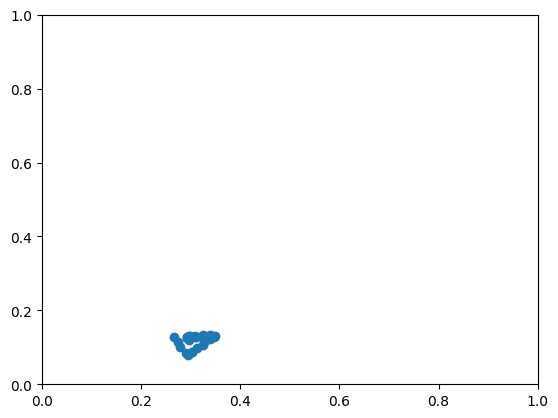

In [14]:
x_values = [val[0] for val in df[df['position_state_id'] == 708]['pos']]
y_values = [val[1] for val in df[df['position_state_id'] == 708]['pos']]

fig, ax = plt.subplots()
plt.scatter(x_values, y_values)
plt.ylim(0, 1)
plt.xlim(0, 1)
plt.show()

### pre train embedd

### mid train embedd

### after train embedd

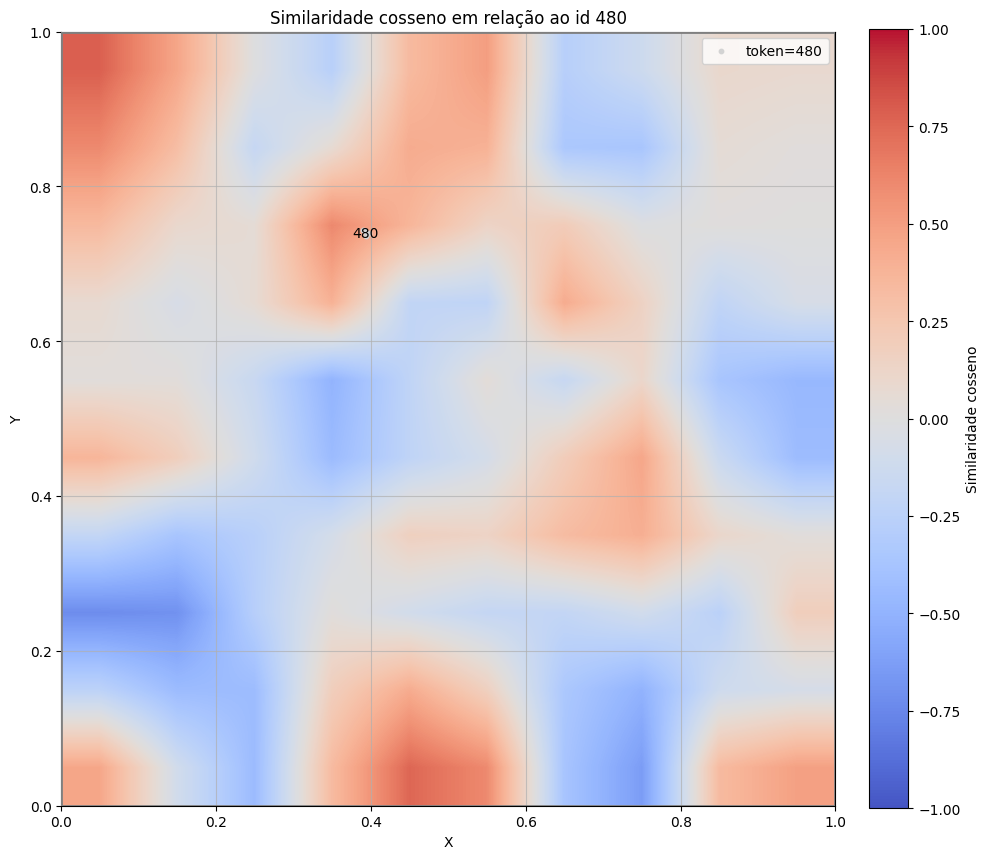

(<Figure size 1000x1000 with 2 Axes>,
 <Axes: title={'center': 'Similaridade cosseno em relação ao id 480'}, xlabel='X', ylabel='Y'>)

In [39]:
plot_cosine_similarity_map_no_env(
    df_states=df,
    cossim_df=coss,
    current_id=480,
    similarity_id_offset=0,
    cmap="coolwarm",
    smooth_sigma=0.05,
    grid_size=10,
    sim_power=0.2,
    current_color="lightgray",
    current_size=10,
    current_alpha=1
)

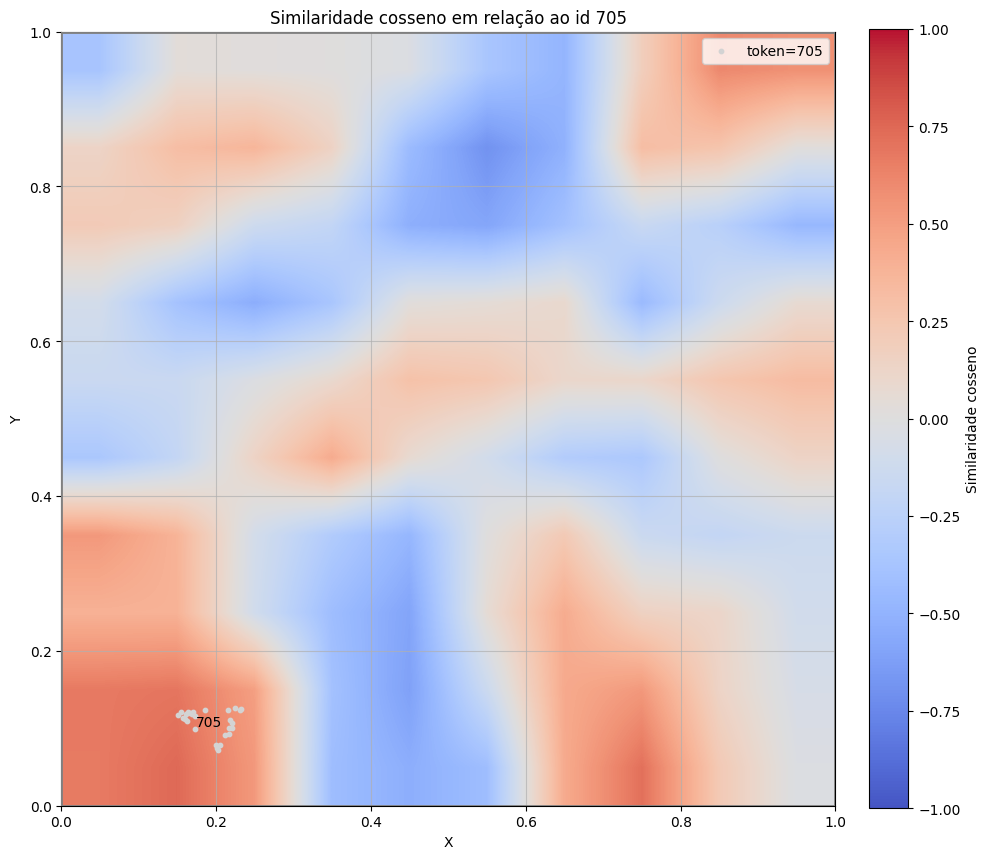

(<Figure size 1000x1000 with 2 Axes>,
 <Axes: title={'center': 'Similaridade cosseno em relação ao id 705'}, xlabel='X', ylabel='Y'>)

In [40]:
plot_cosine_similarity_map_no_env(
    df_states=df,
    cossim_df=coss,
    current_id=705,
    similarity_id_offset=0,
    cmap="coolwarm",
    smooth_sigma=0.05,
    grid_size=10,
    sim_power=0.2,
    current_color="lightgray",
    current_size=10,
    current_alpha=1
)

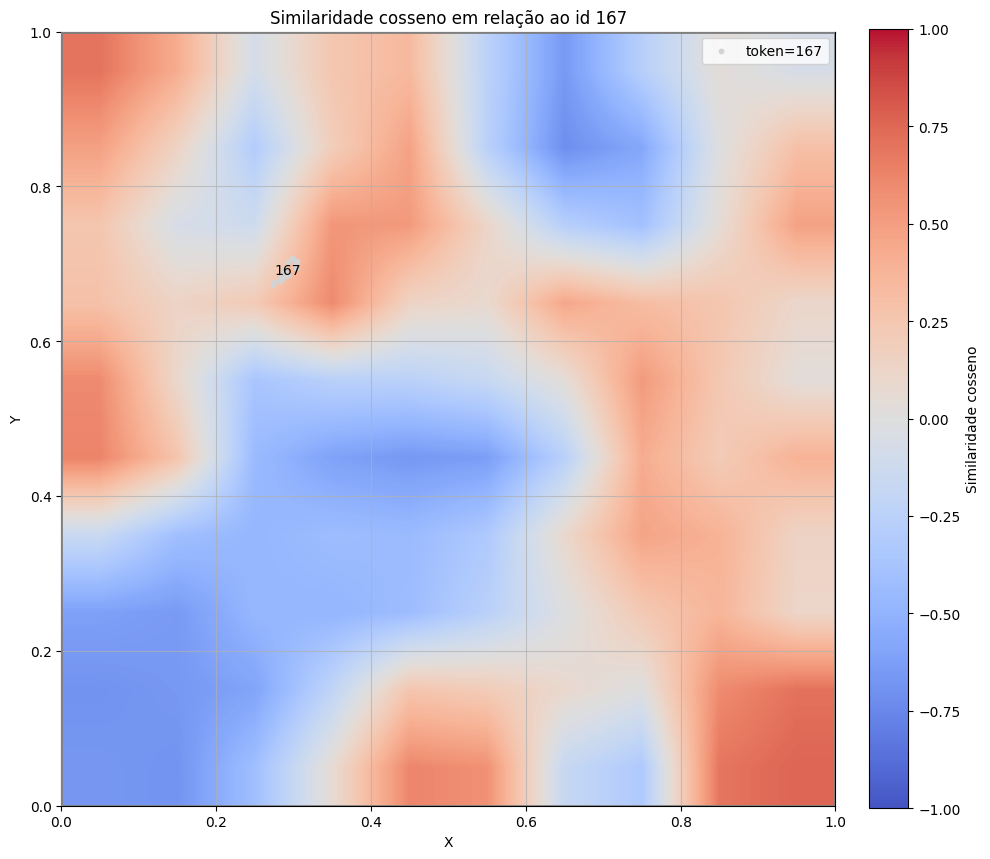

(<Figure size 1000x1000 with 2 Axes>,
 <Axes: title={'center': 'Similaridade cosseno em relação ao id 167'}, xlabel='X', ylabel='Y'>)

In [41]:
plot_cosine_similarity_map_no_env(
    df_states=df,
    cossim_df=coss,
    current_id=167,
    similarity_id_offset=0,
    cmap="coolwarm",
    smooth_sigma=0.05,
    grid_size=10,
    sim_power=0.2,
    current_color="lightgray",
    current_size=10,
    current_alpha=1
)

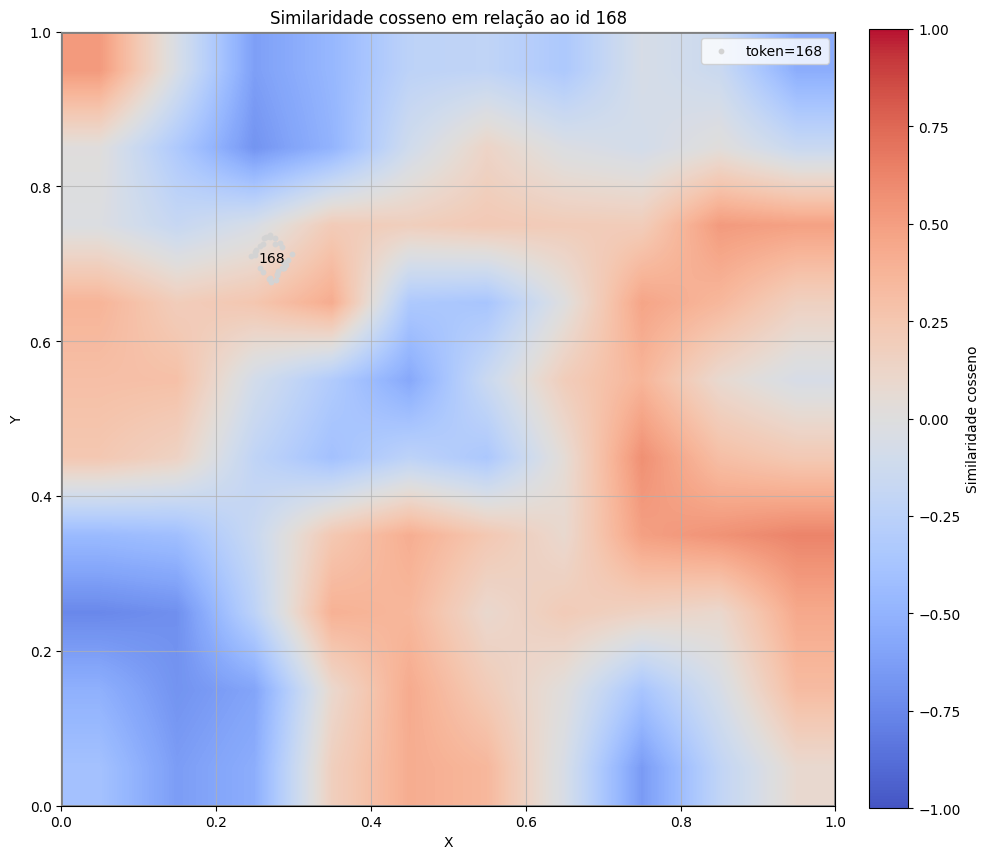

(<Figure size 1000x1000 with 2 Axes>,
 <Axes: title={'center': 'Similaridade cosseno em relação ao id 168'}, xlabel='X', ylabel='Y'>)

In [33]:
plot_cosine_similarity_map_no_env(
    df_states=df,
    cossim_df=coss,
    current_id=168,
    similarity_id_offset=0,
    cmap="coolwarm",
    smooth_sigma=0.05,
    grid_size=10,
    sim_power=0.2,
    current_color="lightgray",
    current_size=10,
    current_alpha=1
)

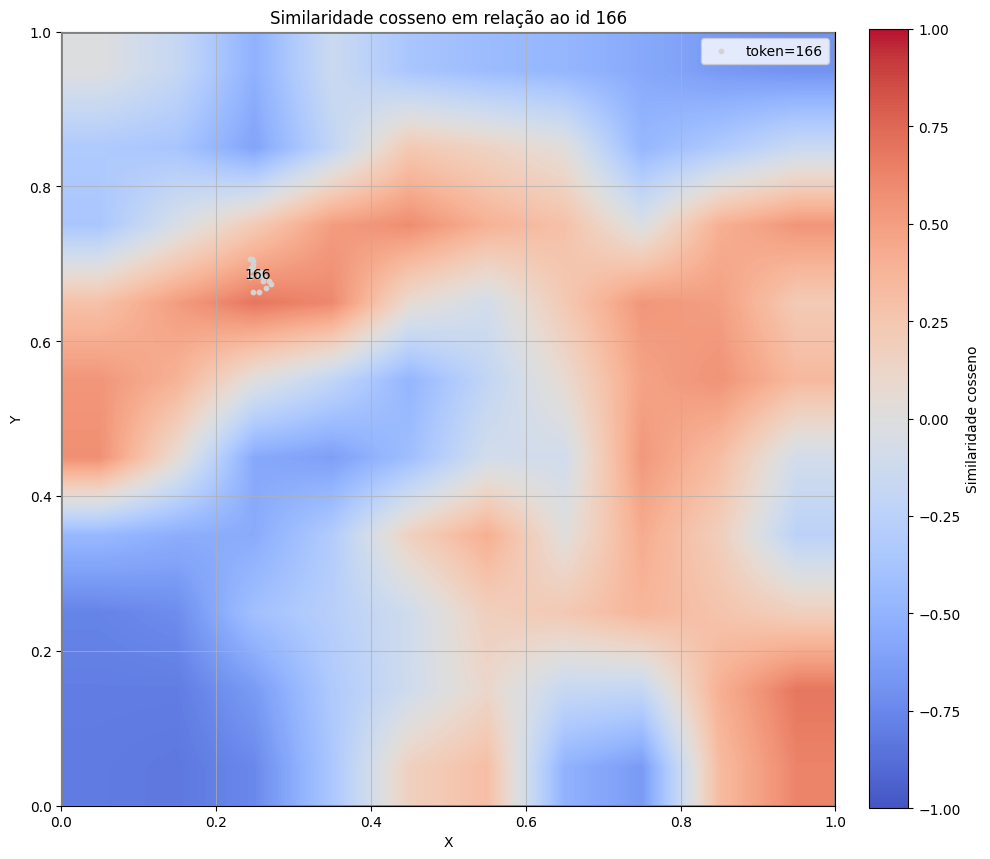

(<Figure size 1000x1000 with 2 Axes>,
 <Axes: title={'center': 'Similaridade cosseno em relação ao id 166'}, xlabel='X', ylabel='Y'>)

In [34]:
plot_cosine_similarity_map_no_env(
    df_states=df,
    cossim_df=coss,
    current_id=166,
    similarity_id_offset=0,
    cmap="coolwarm",
    smooth_sigma=0.05,
    grid_size=10,
    sim_power=0.2,
    current_color="lightgray",
    current_size=10,
    current_alpha=1
)

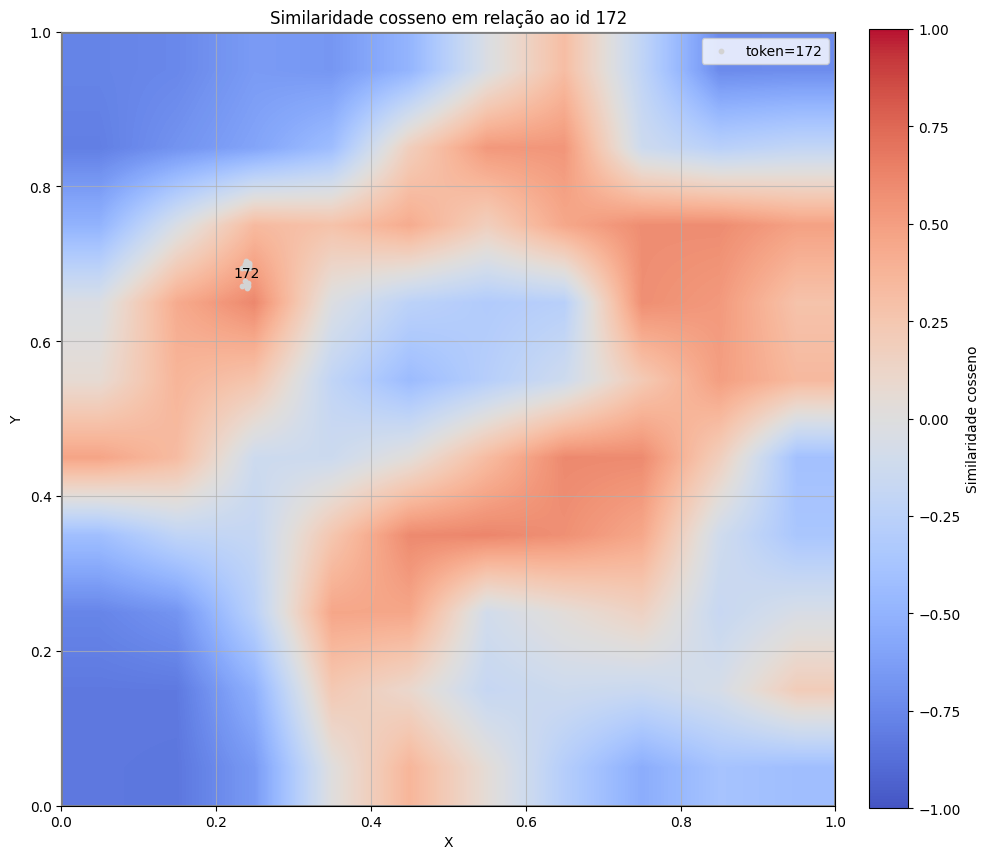

(<Figure size 1000x1000 with 2 Axes>,
 <Axes: title={'center': 'Similaridade cosseno em relação ao id 172'}, xlabel='X', ylabel='Y'>)

In [35]:
plot_cosine_similarity_map_no_env(
    df_states=df,
    cossim_df=coss,
    current_id=172,
    similarity_id_offset=0,
    cmap="coolwarm",
    smooth_sigma=0.05,
    grid_size=10,
    sim_power=0.2,
    current_color="lightgray",
    current_size=10,
    current_alpha=1
)

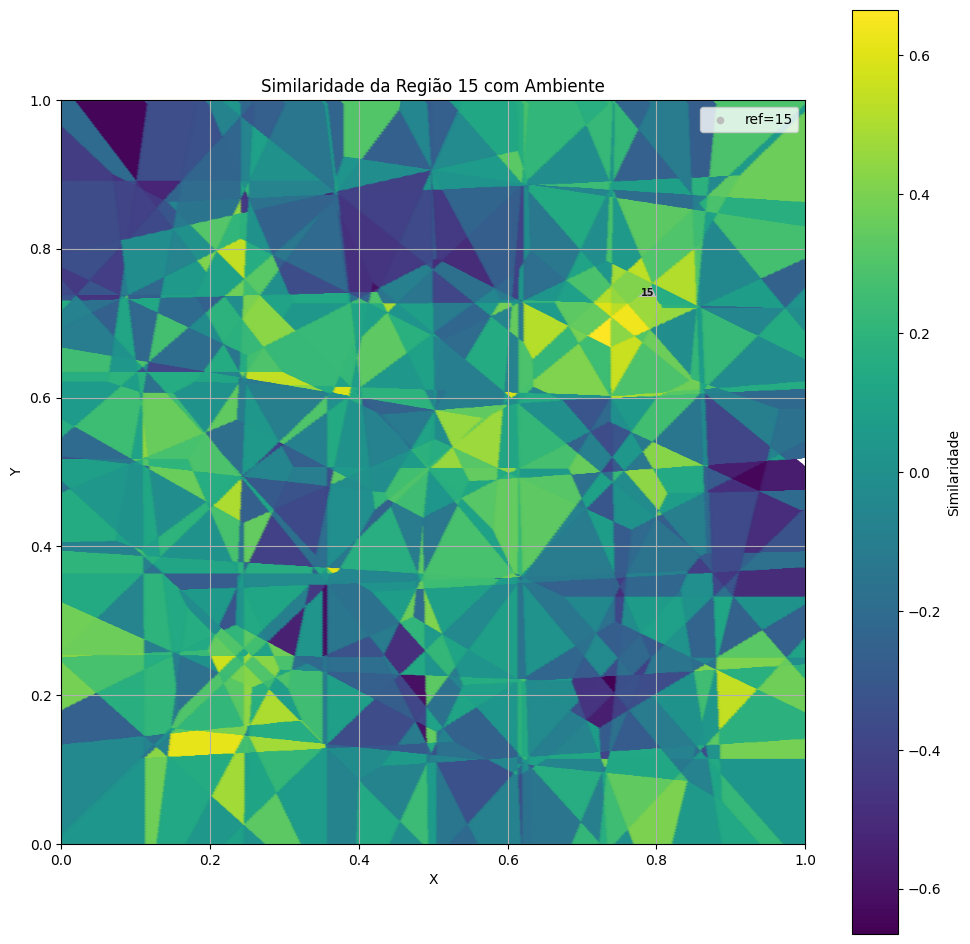

In [25]:
plot_similarity_to_group_from_matrix(apd, coss, grupo_ref=15, cmap="viridis", annotate_means=False)

# Head Projections

In [26]:
def plot_similarity_to_group_from_projec_matrix(
    apd: pd.DataFrame,
    cossim_df: pd.DataFrame,
    grupo_ref: int,
    cmap: str = "viridis",
    annotate_means: bool = True,
    s_outros: int = 20,
    s_ref: int = 20,
    num_head:int = 0,
):
    """
    Colore os pontos de `apd` pela similaridade coseno (vinda de `cossim_df`)
    em relação ao grupo de referência `grupo_ref`. O grupo de referência é
    plotado em cinza.

    - apd: DataFrame com colunas ['X','Y','position_state_id']
    - cossim_df: DataFrame VxV, índice e colunas = ids (int ou str convertíveis p/ int)
    - grupo_ref: id do grupo de referência (deve existir em índice/colunas de cossim_df)
    """

    # --- saneamento: garantir que índice/colunas sejam inteiros compatíveis com position_state_id ---
    def _to_int_index(df: pd.DataFrame) -> pd.DataFrame:
        # tenta converter tanto index quanto columns para int (se forem strings numéricas)
        if not np.issubdtype(df.index.dtype, np.integer):
            df = df.copy()
            df.index = df.index.astype(int)
        if not np.issubdtype(df.columns.dtype, np.integer):
            df = df.copy()
            df.columns = df.columns.astype(int)
        return df

    cossim_df = _to_int_index(cossim_df)

    # checagens
    required_cols = {"X", "Y", "position_state_id"}
    assert required_cols.issubset(apd.columns), f"apd precisa conter {required_cols}"
    if grupo_ref not in cossim_df.index or grupo_ref not in cossim_df.columns:
        raise ValueError(f"grupo_ref {grupo_ref} não encontrado em cossim_df")

    # separa ref e outros
    is_ref = (apd["position_state_id"] == grupo_ref)
    df_ref = apd[is_ref]
    df_outros = apd[~is_ref].copy()

    # série de similaridades do ref com todos (indexada por id)
    sim_series = cossim_df.loc[grupo_ref]  # pandas Series: index = ids, values = cosenos

    # mapeia cada position_state_id -> similaridade; ids ausentes viram NaN
    df_outros["sim"] = df_outros["position_state_id"].map(sim_series)

    # plot
    plt.figure(figsize=(12, 12))

    # 1) referência em cinza
    if not df_ref.empty:
        plt.scatter(df_ref["X"], df_ref["Y"], c="#bdbdbd", s=s_ref, label=f"ref={grupo_ref}")
        plt.annotate(str(grupo_ref),
                         (df_ref["X"].mean(), df_ref["Y"].mean()),
                         fontsize=7, ha="center", va="center", fontweight="bold", alpha=0.9)

    # 2) demais coloridos pela similaridade (linhas com NaN são ignoradas pelo scatter)
    if not df_outros.empty:
        sc = plt.scatter(df_outros["X"], df_outros["Y"], c=df_outros["sim"], cmap=cmap, s=s_outros)
        cbar = plt.colorbar(sc)
        cbar.set_label(f"Similaridade")

    # 3) anotação das médias por grupo (≠ ref)
    if annotate_means and not df_outros.empty:
        medias = df_outros.groupby("position_state_id")[["X", "Y"]].mean().reset_index()
        for _, row in medias.iterrows():
            plt.annotate(str(int(row["position_state_id"])),
                         (row["X"], row["Y"]),
                         fontsize=7, ha="center", va="center", fontweight="bold", alpha=0.9)

    # layout
    plt.xlabel("X")
    plt.ylabel("Y")
    plt.title(f"Similaridade da Região {grupo_ref} com Ambiente [Head {num_head}]")
    plt.xlim(0, 1)
    plt.ylim(0, 1)
    plt.grid(True)
    plt.gca().set_aspect("equal", adjustable="box")
    plt.legend(loc="upper right")
    plt.show()

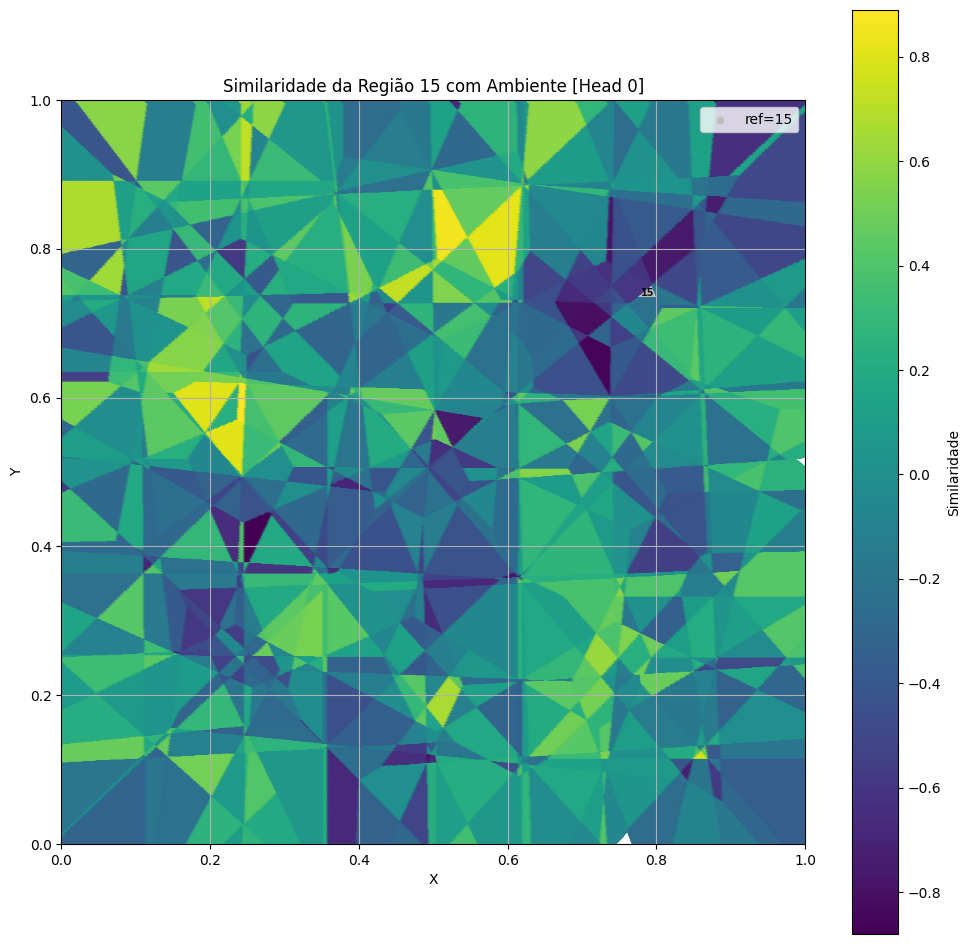

In [27]:
plot_similarity_to_group_from_projec_matrix(apd, head0, grupo_ref=15, cmap="viridis", annotate_means=False, num_head=0)

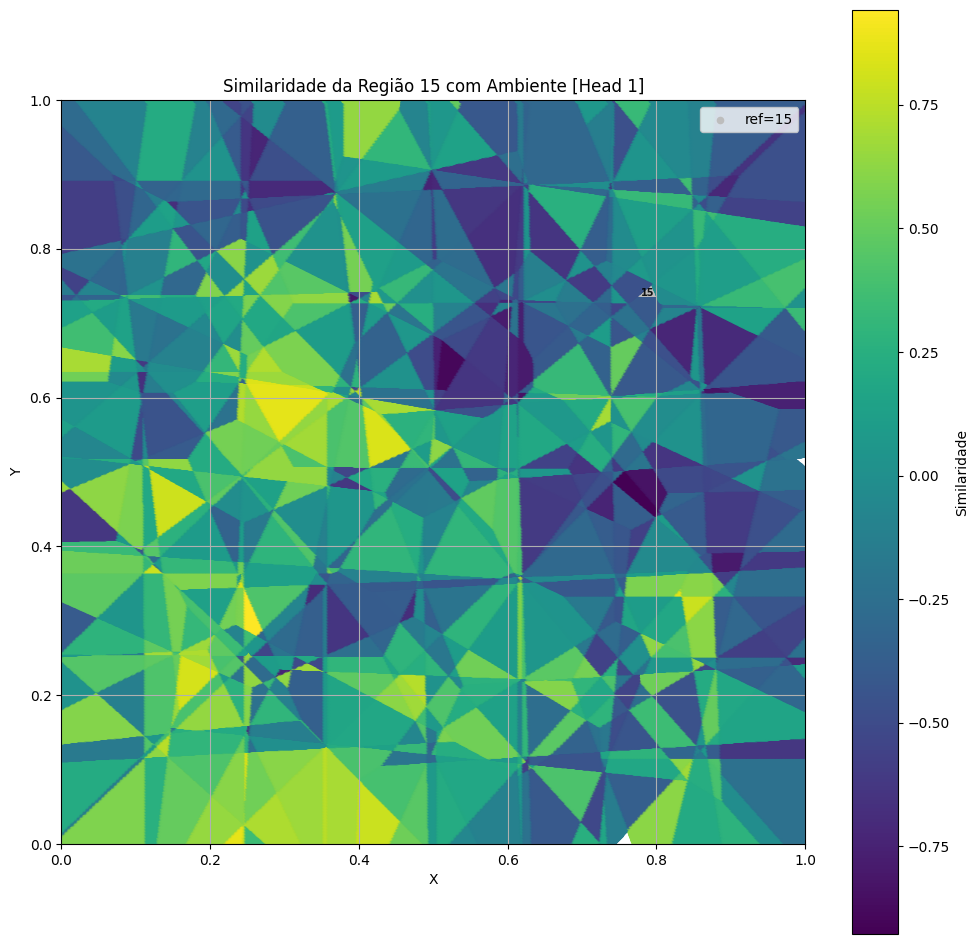

In [28]:
plot_similarity_to_group_from_projec_matrix(apd, head1, grupo_ref=15, cmap="viridis", annotate_means=False, num_head=1)

# Head Attentions

In [10]:
def plot_similarity_to_group_from_attn_matrix(
    apd: pd.DataFrame,
    cossim_df: pd.DataFrame,
    grupo_ref: int,
    cmap: str = "viridis",
    annotate_means: bool = True,
    s_outros: int = 20,
    s_ref: int = 20,
    num_head:int = 0,
):
    """
    Colore os pontos de `apd` pela similaridade coseno (vinda de `cossim_df`)
    em relação ao grupo de referência `grupo_ref`. O grupo de referência é
    plotado em cinza.

    - apd: DataFrame com colunas ['X','Y','position_state_id']
    - cossim_df: DataFrame VxV, índice e colunas = ids (int ou str convertíveis p/ int)
    - grupo_ref: id do grupo de referência (deve existir em índice/colunas de cossim_df)
    """

    # --- saneamento: garantir que índice/colunas sejam inteiros compatíveis com position_state_id ---
    def _to_int_index(df: pd.DataFrame) -> pd.DataFrame:
        # tenta converter tanto index quanto columns para int (se forem strings numéricas)
        if not np.issubdtype(df.index.dtype, np.integer):
            df = df.copy()
            df.index = df.index.astype(int)
        if not np.issubdtype(df.columns.dtype, np.integer):
            df = df.copy()
            df.columns = df.columns.astype(int)
        return df

    cossim_df = _to_int_index(cossim_df)

    # checagens
    required_cols = {"X", "Y", "position_state_id"}
    assert required_cols.issubset(apd.columns), f"apd precisa conter {required_cols}"
    if grupo_ref not in cossim_df.index or grupo_ref not in cossim_df.columns:
        raise ValueError(f"grupo_ref {grupo_ref} não encontrado em cossim_df")

    # separa ref e outros
    is_ref = (apd["position_state_id"] == grupo_ref)
    df_ref = apd[is_ref]
    df_outros = apd[~is_ref].copy()

    # série de similaridades do ref com todos (indexada por id)
    sim_series = cossim_df.loc[grupo_ref]  # pandas Series: index = ids, values = cosenos

    # mapeia cada position_state_id -> similaridade; ids ausentes viram NaN
    df_outros["sim"] = df_outros["position_state_id"].map(sim_series)

    # plot
    plt.figure(figsize=(12, 12))

    # 1) referência em cinza
    if not df_ref.empty:
        plt.scatter(df_ref["X"], df_ref["Y"], c="#bdbdbd", s=s_ref, label=f"ref={grupo_ref}")
        plt.annotate(str(grupo_ref),
                         (df_ref["X"].mean(), df_ref["Y"].mean()),
                         fontsize=7, ha="center", va="center", fontweight="bold", alpha=0.9)

    # 2) demais coloridos pela similaridade (linhas com NaN são ignoradas pelo scatter)
    if not df_outros.empty:
        sc = plt.scatter(df_outros["X"], df_outros["Y"], c=df_outros["sim"], cmap=cmap, s=s_outros)
        cbar = plt.colorbar(sc)
        cbar.set_label(f"Similaridade")

    # 3) anotação das médias por grupo (≠ ref)
    if annotate_means and not df_outros.empty:
        medias = df_outros.groupby("position_state_id")[["X", "Y"]].mean().reset_index()
        for _, row in medias.iterrows():
            plt.annotate(str(int(row["position_state_id"])),
                         (row["X"], row["Y"]),
                         fontsize=7, ha="center", va="center", fontweight="bold", alpha=0.9)

    # layout
    plt.xlabel("X")
    plt.ylabel("Y")
    plt.title(f"Similaridade da Região {grupo_ref} com Ambiente [Head {num_head}]")
    plt.xlim(0, 1)
    plt.ylim(0, 1)
    plt.grid(True)
    plt.gca().set_aspect("equal", adjustable="box")
    plt.legend(loc="upper right")
    plt.show()

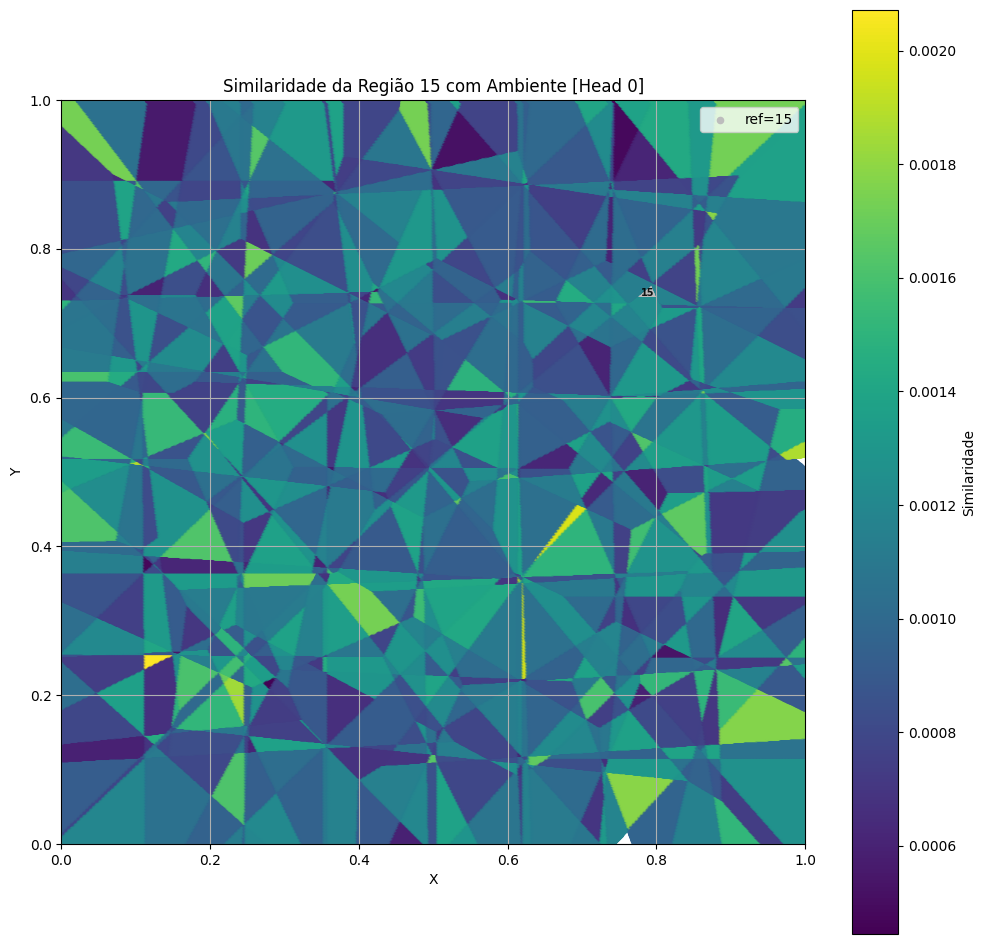

In [11]:
plot_similarity_to_group_from_attn_matrix(apd, head0_att, grupo_ref=15, cmap="viridis", annotate_means=False, num_head=0)

In [14]:
apd['position_state_id'].max()

1056

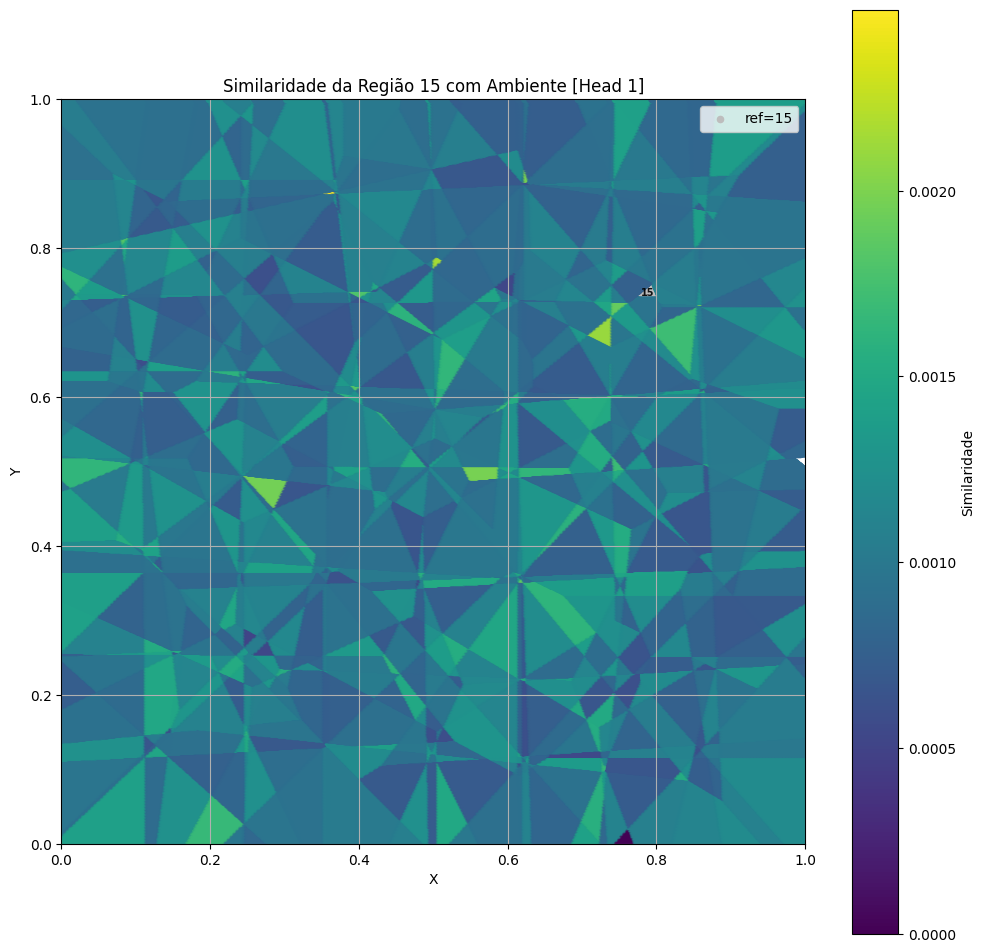

In [12]:
plot_similarity_to_group_from_attn_matrix(apd, head1_att, grupo_ref=15, cmap="viridis", annotate_means=False, num_head=1)

# Head Attn w Pos

In [13]:
def plot_similarity_to_group_from_attn_matrix_w_pos(
    apd: pd.DataFrame,
    cossim_df: pd.DataFrame,
    grupo_ref: int,
    cmap: str = "viridis",
    annotate_means: bool = True,
    s_outros: int = 20,
    s_ref: int = 20,
    num_head:int = 0,
):
    """
    Colore os pontos de `apd` pela similaridade coseno (vinda de `cossim_df`)
    em relação ao grupo de referência `grupo_ref`. O grupo de referência é
    plotado em cinza.

    - apd: DataFrame com colunas ['X','Y','position_state_id']
    - cossim_df: DataFrame VxV, índice e colunas = ids (int ou str convertíveis p/ int)
    - grupo_ref: id do grupo de referência (deve existir em índice/colunas de cossim_df)
    """

    # --- saneamento: garantir que índice/colunas sejam inteiros compatíveis com position_state_id ---
    def _to_int_index(df: pd.DataFrame) -> pd.DataFrame:
        # tenta converter tanto index quanto columns para int (se forem strings numéricas)
        if not np.issubdtype(df.index.dtype, np.integer):
            df = df.copy()
            df.index = df.index.astype(int)
        if not np.issubdtype(df.columns.dtype, np.integer):
            df = df.copy()
            df.columns = df.columns.astype(int)
        return df

    cossim_df = _to_int_index(cossim_df)

    # checagens
    required_cols = {"X", "Y", "position_state_id"}
    assert required_cols.issubset(apd.columns), f"apd precisa conter {required_cols}"
    if grupo_ref not in cossim_df.index or grupo_ref not in cossim_df.columns:
        raise ValueError(f"grupo_ref {grupo_ref} não encontrado em cossim_df")

    # separa ref e outros
    is_ref = (apd["position_state_id"] == grupo_ref)
    df_ref = apd[is_ref]
    df_outros = apd[~is_ref].copy()

    # série de similaridades do ref com todos (indexada por id)
    sim_series = cossim_df.loc[grupo_ref]  # pandas Series: index = ids, values = cosenos

    # mapeia cada position_state_id -> similaridade; ids ausentes viram NaN
    df_outros["sim"] = df_outros["position_state_id"].map(sim_series)

    # plot
    plt.figure(figsize=(12, 12))

    # 1) referência em cinza
    if not df_ref.empty:
        plt.scatter(df_ref["X"], df_ref["Y"], c="#bdbdbd", s=s_ref, label=f"ref={grupo_ref}")
        plt.annotate(str(grupo_ref),
                         (df_ref["X"].mean(), df_ref["Y"].mean()),
                         fontsize=7, ha="center", va="center", fontweight="bold", alpha=0.9)

    # 2) demais coloridos pela similaridade (linhas com NaN são ignoradas pelo scatter)
    if not df_outros.empty:
        sc = plt.scatter(df_outros["X"], df_outros["Y"], c=df_outros["sim"], cmap=cmap, s=s_outros)
        cbar = plt.colorbar(sc)
        cbar.set_label(f"Similaridade")

    # 3) anotação das médias por grupo (≠ ref)
    if annotate_means and not df_outros.empty:
        medias = df_outros.groupby("position_state_id")[["X", "Y"]].mean().reset_index()
        for _, row in medias.iterrows():
            plt.annotate(str(int(row["position_state_id"])),
                         (row["X"], row["Y"]),
                         fontsize=7, ha="center", va="center", fontweight="bold", alpha=0.9)

    # layout
    plt.xlabel("X")
    plt.ylabel("Y")
    plt.title(f"Similaridade da Região {grupo_ref} com Ambiente [Head {num_head}]")
    plt.xlim(0, 1)
    plt.ylim(0, 1)
    plt.grid(True)
    plt.gca().set_aspect("equal", adjustable="box")
    plt.legend(loc="upper right")
    plt.show()

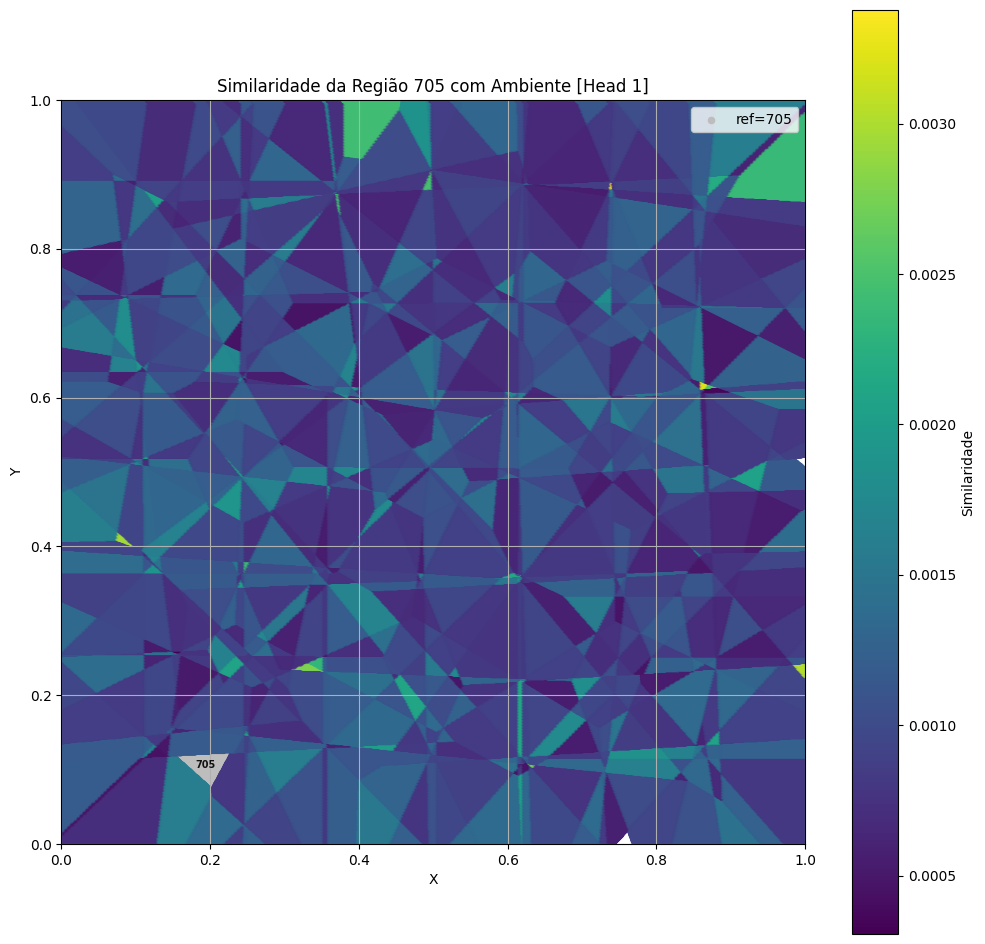

In [22]:
plot_similarity_to_group_from_attn_matrix_w_pos(apd, head1_att_pos, grupo_ref=705, cmap="viridis", annotate_means=False, num_head=1)

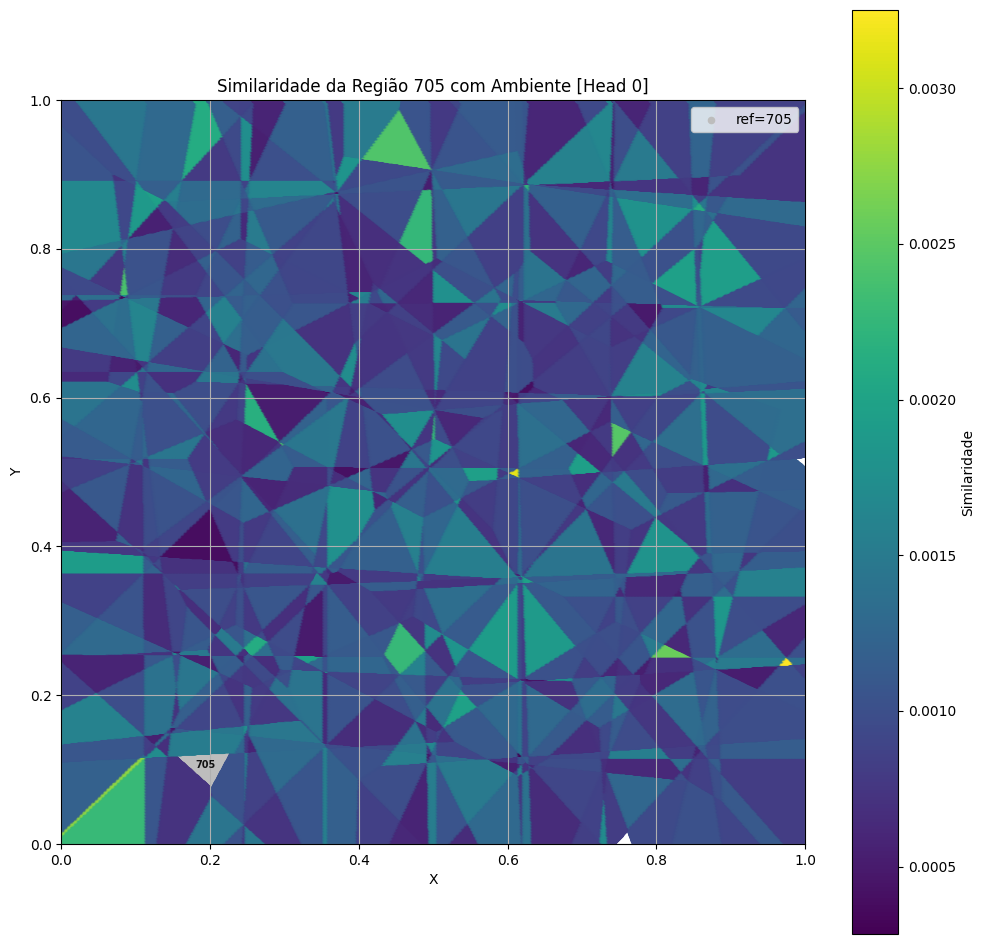

In [23]:
plot_similarity_to_group_from_attn_matrix_w_pos(apd, head0_att_pos, grupo_ref=705, cmap="viridis", annotate_means=False, num_head=0)

In [19]:
# plot_similarity_to_group_from_attn_matrix(apd, head1_att_pos, grupo_ref=806, cmap="viridis", annotate_means=False, num_head=1)

In [ ]:
head1_att_pos.iloc[705].sort_values(ascending=False).head()

341    0.002764
210    0.002684
770    0.002652
667    0.002426
775    0.002383
Name: 15, dtype: float64

In [ ]:
head0_att_pos.iloc[705].sort_values(ascending=False).head()

808    0.004574
138    0.003253
743    0.002719
624    0.002260
446    0.002227
Name: 15, dtype: float64

In [ ]:
head1_att_pos.iloc[15]['806']

0.0027919996

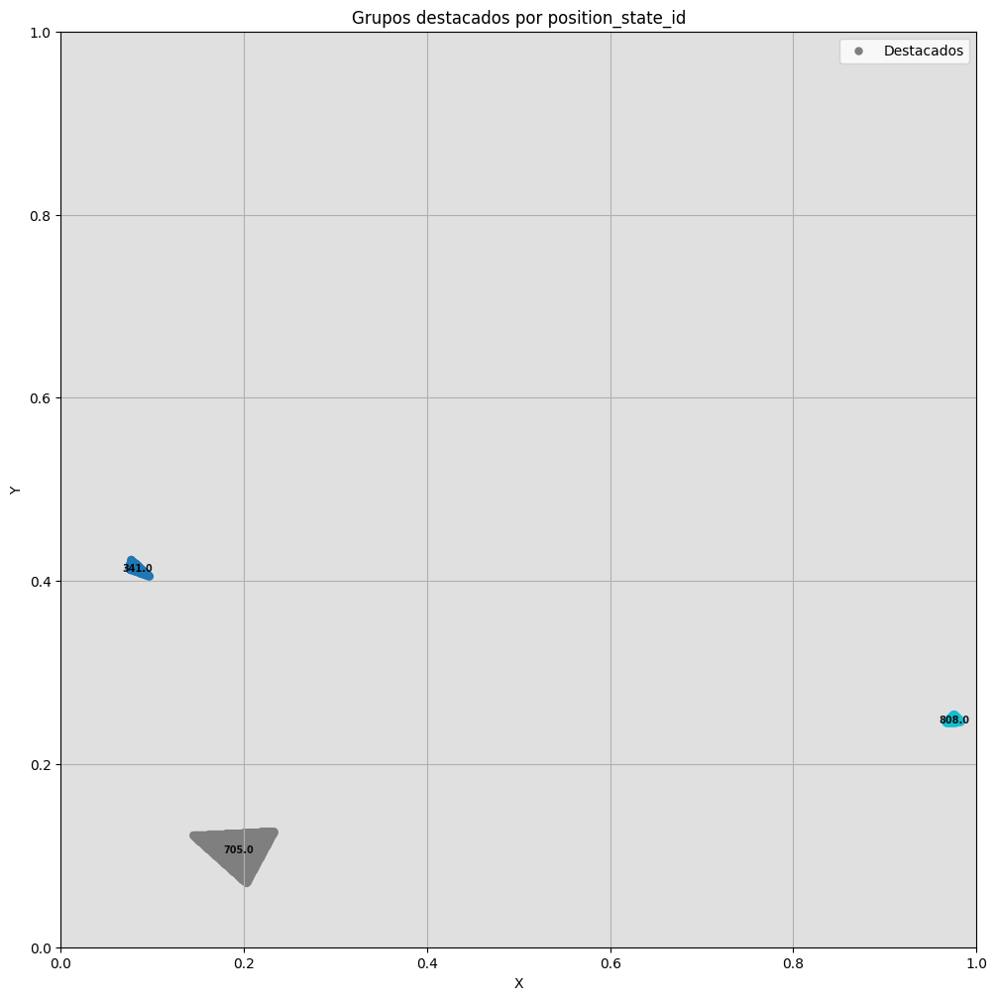

In [24]:
plot_position_states(apd, [705, 341, 808])

# Head Attn W Pos Softmax

In [16]:
def plot_similarity_to_group_from_attn_matrix_w_pos(
    apd: pd.DataFrame,
    cossim_df: pd.DataFrame,
    grupo_ref: int,
    cmap: str = "viridis",
    annotate_means: bool = True,
    s_outros: int = 20,
    s_ref: int = 20,
    num_head:int = 0,
    mode: str='',
):
    """
    Colore os pontos de `apd` pela similaridade coseno (vinda de `cossim_df`)
    em relação ao grupo de referência `grupo_ref`. O grupo de referência é
    plotado em cinza.

    - apd: DataFrame com colunas ['X','Y','position_state_id']
    - cossim_df: DataFrame VxV, índice e colunas = ids (int ou str convertíveis p/ int)
    - grupo_ref: id do grupo de referência (deve existir em índice/colunas de cossim_df)
    """

    # --- saneamento: garantir que índice/colunas sejam inteiros compatíveis com position_state_id ---
    def _to_int_index(df: pd.DataFrame) -> pd.DataFrame:
        # tenta converter tanto index quanto columns para int (se forem strings numéricas)
        if not np.issubdtype(df.index.dtype, np.integer):
            df = df.copy()
            df.index = df.index.astype(int)
        if not np.issubdtype(df.columns.dtype, np.integer):
            df = df.copy()
            df.columns = df.columns.astype(int)
        return df

    cossim_df = _to_int_index(cossim_df)

    # checagens
    required_cols = {"X", "Y", "position_state_id"}
    assert required_cols.issubset(apd.columns), f"apd precisa conter {required_cols}"
    if grupo_ref not in cossim_df.index or grupo_ref not in cossim_df.columns:
        raise ValueError(f"grupo_ref {grupo_ref} não encontrado em cossim_df")

    # separa ref e outros
    is_ref = (apd["position_state_id"] == grupo_ref)
    df_ref = apd[is_ref]
    df_outros = apd[~is_ref].copy()

    # série de similaridades do ref com todos (indexada por id)
    sim_series = cossim_df.loc[grupo_ref]  # pandas Series: index = ids, values = cosenos

    # mapeia cada position_state_id -> similaridade; ids ausentes viram NaN
    df_outros["sim"] = df_outros["position_state_id"].map(sim_series)

    # plot
    plt.figure(figsize=(12, 12))

    # 1) referência em cinza
    if not df_ref.empty:
        plt.scatter(df_ref["X"], df_ref["Y"], c="#bdbdbd", s=s_ref, label=f"ref={grupo_ref}")
        plt.annotate(str(grupo_ref),
                         (df_ref["X"].mean(), df_ref["Y"].mean()),
                         fontsize=7, ha="center", va="center", fontweight="bold", alpha=0.9)

    # 2) demais coloridos pela similaridade (linhas com NaN são ignoradas pelo scatter)
    if not df_outros.empty:
        sc = plt.scatter(df_outros["X"], df_outros["Y"], c=df_outros["sim"], cmap=cmap, s=s_outros)
        cbar = plt.colorbar(sc)
        cbar.set_label(f"Similaridade")

    # 3) anotação das médias por grupo (≠ ref)
    if annotate_means and not df_outros.empty:
        medias = df_outros.groupby("position_state_id")[["X", "Y"]].mean().reset_index()
        for _, row in medias.iterrows():
            plt.annotate(str(int(row["position_state_id"])),
                         (row["X"], row["Y"]),
                         fontsize=7, ha="center", va="center", fontweight="bold", alpha=0.9)

    # layout
    plt.xlabel("X")
    plt.ylabel("Y")
    plt.title(f"Similaridade da Região {grupo_ref} com Ambiente [Head {num_head}, {mode}]")
    plt.xlim(0, 1)
    plt.ylim(0, 1)
    plt.grid(True)
    plt.gca().set_aspect("equal", adjustable="box")
    plt.legend(loc="upper right")
    plt.show()

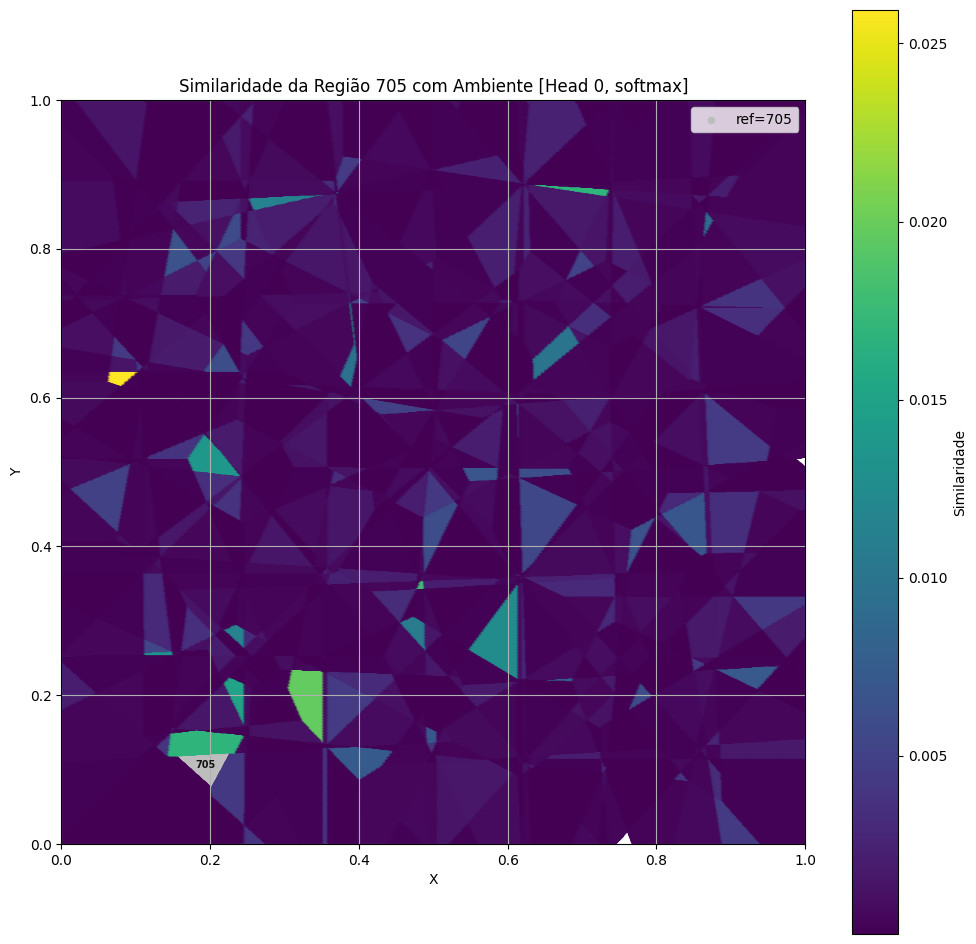

In [19]:
plot_similarity_to_group_from_attn_matrix_w_pos(apd, head0_att_pos_softmax, grupo_ref=705, cmap="viridis", annotate_means=False, num_head=0, mode='softmax')

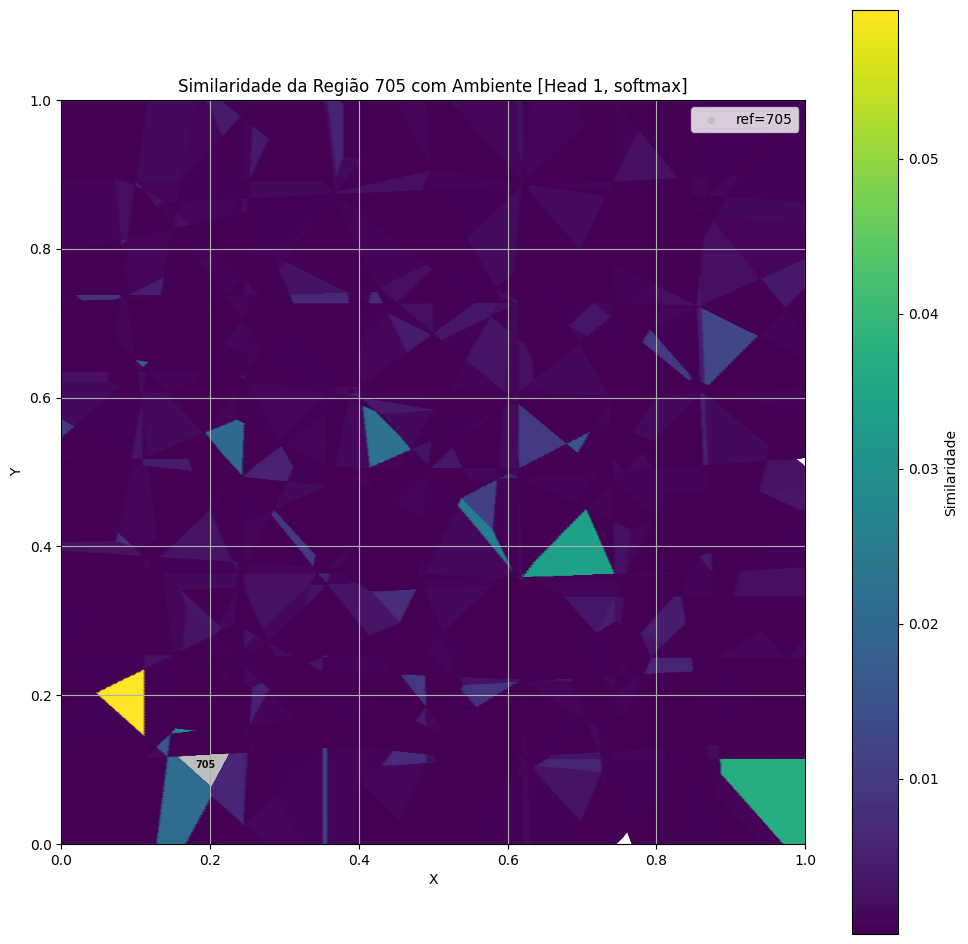

In [18]:
plot_similarity_to_group_from_attn_matrix_w_pos(apd, head1_att_pos_softmax, grupo_ref=705, cmap="viridis", annotate_means=False, num_head=1, mode='softmax')

# Head Attn W Pos Logit

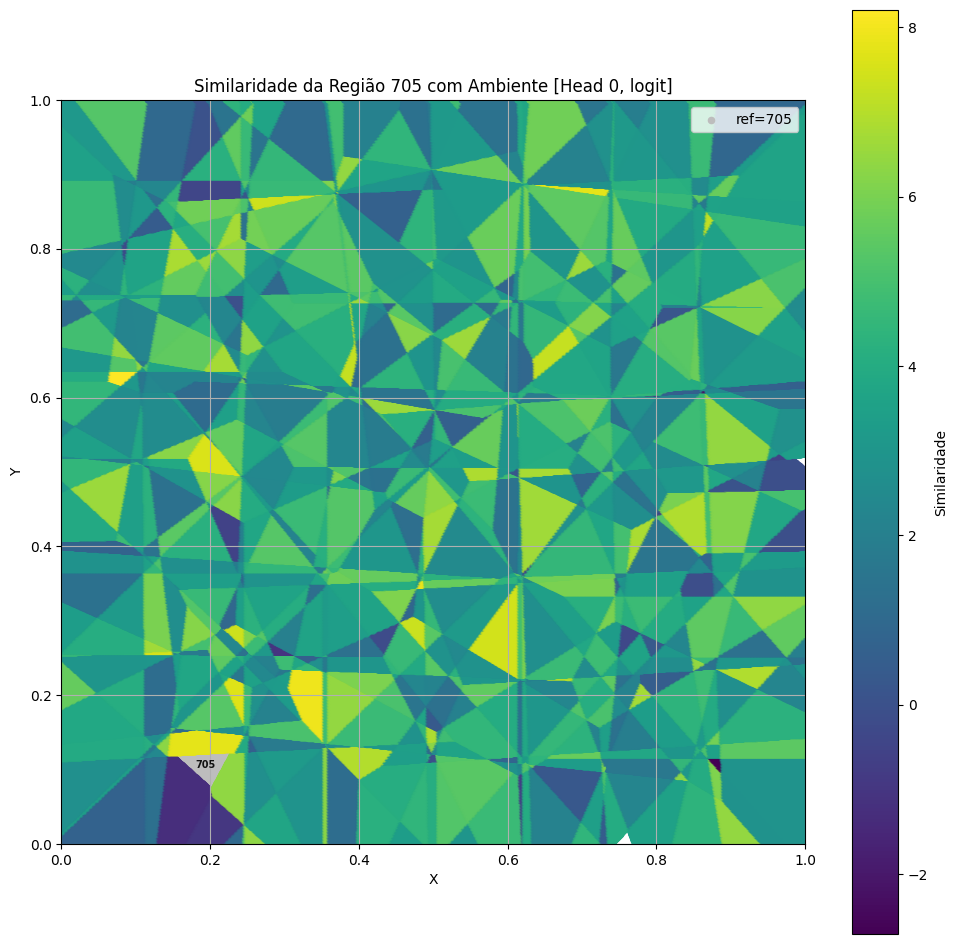

In [20]:
plot_similarity_to_group_from_attn_matrix_w_pos(apd, head0_att_pos_logit, grupo_ref=705, cmap="viridis", annotate_means=False, num_head=0, mode='logit')

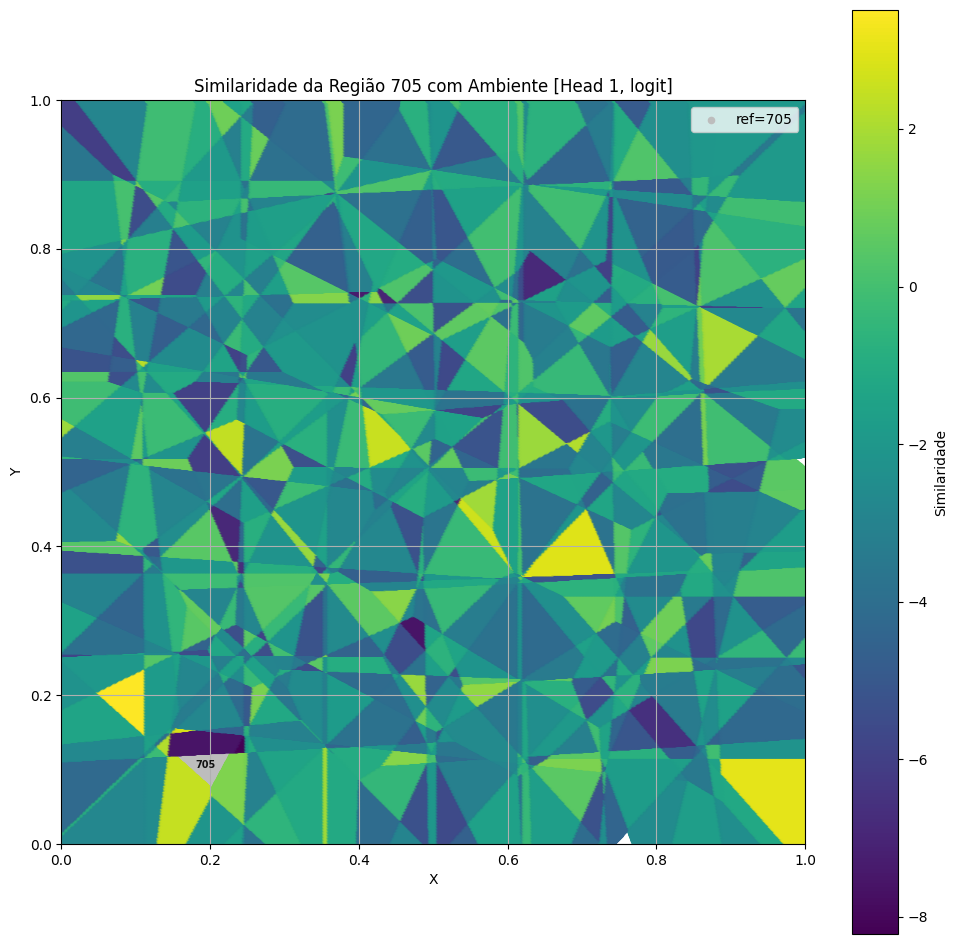

In [21]:
plot_similarity_to_group_from_attn_matrix_w_pos(apd, head1_att_pos_logit, grupo_ref=705, cmap="viridis", annotate_means=False, num_head=1, mode='logit')

# Head Attn W Pos Cossine

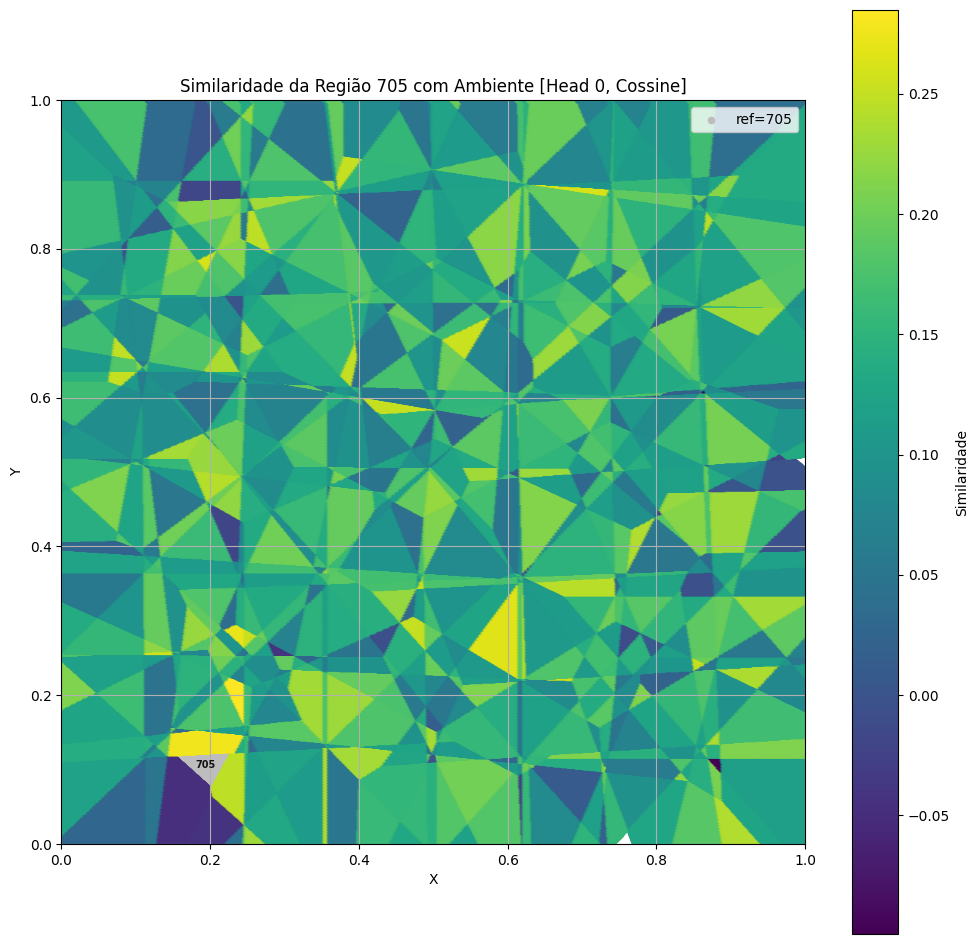

In [23]:
plot_similarity_to_group_from_attn_matrix_w_pos(apd, head0_att_pos_coss, grupo_ref=705, cmap="viridis", annotate_means=False, num_head=0, mode='Cossine')

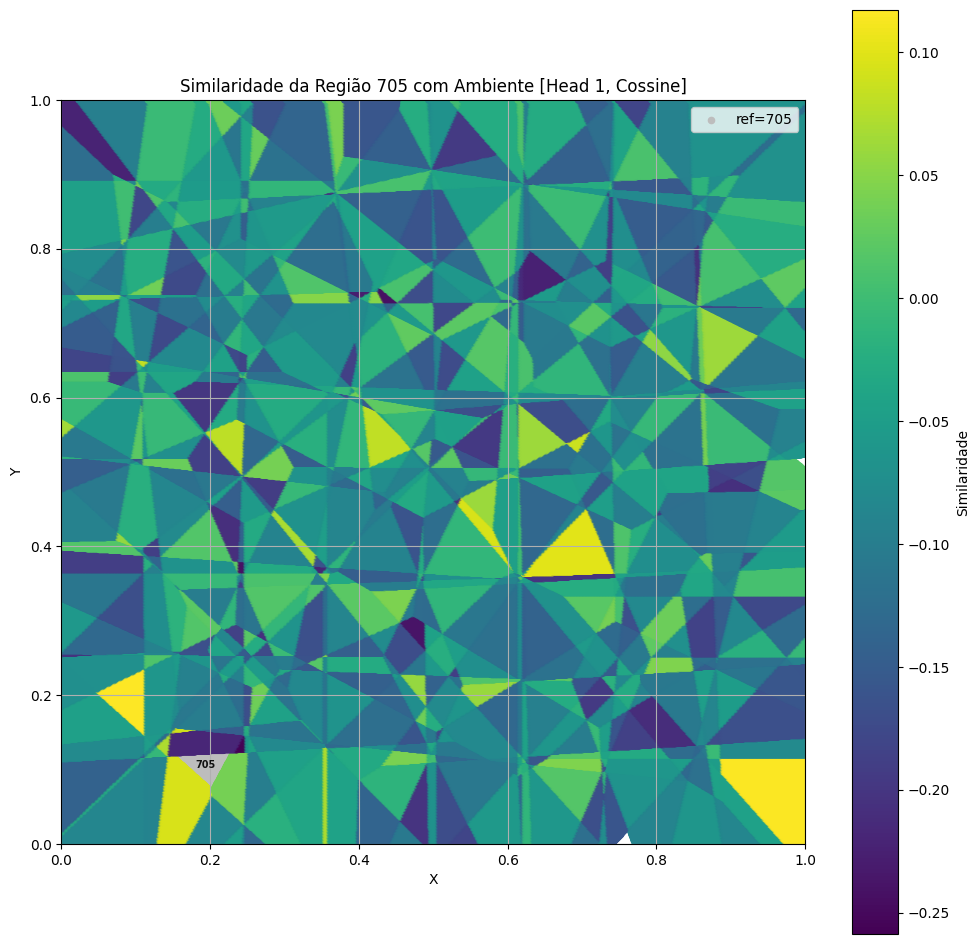

In [22]:
plot_similarity_to_group_from_attn_matrix_w_pos(apd, head1_att_pos_coss, grupo_ref=705, cmap="viridis", annotate_means=False, num_head=1, mode='Cossine')

# Imgs and GIFs

In [35]:
def gerar_graficos_expansao(
    apd,
    sequencias,
    pasta_destino="imgs",
    titulo_base="Passo",
    dpi=150,
    file_tag: str = '',
    modo: str = "mono",             # "mono" (novo) ou "colormap"
):
    """
    Aceita lista plana OU lista de listas.
    'modo' controla qual função de plot usar: "mono" (novo) ou 
    "colormap".
    """
    # normaliza entrada (plana -> cumulativa)
    if not isinstance(sequencias, (list, tuple)) or len(sequencias) == 0:
        raise ValueError("sequencias deve ser uma lista não vazia (plana ou de listas).")
    is_plana = all(not isinstance(x, (list, tuple)) for x in sequencias)
    sequencias_ids = [list(sequencias[:i+1]) for i in range(len(sequencias))] if is_plana \
                     else [list(s) for s in sequencias]

    os.makedirs(pasta_destino, exist_ok=True)
    caminhos = []
    use_colormap = (modo.lower() == "colormap")

    for step, ids in enumerate(sequencias_ids):
        caminho_arquivo = os.path.join(pasta_destino, f"{file_tag}etapa_{step:02}.png")
        title = f"{titulo_base} {step:02} | {ids[0]}->{ids[-1]}" if len(ids) >= 2 else f"{titulo_base} {step:02}"

        if use_colormap:
            plot_position_states_w_title(apd, grupos_destacados=ids, title=title)
        else:
            plot_position_states_emphasis_w_title(apd, grupos_destacados=ids, title=title)

        plt.savefig(caminho_arquivo, bbox_inches="tight", dpi=dpi)
        plt.close()
        caminhos.append(caminho_arquivo)

    return caminhos

In [36]:
import os, glob, re
from PIL import Image

def gerar_gif(pasta_imagens, file_prefix="", nome_gif="legacy/media/trajetoria_animada.gif", duracao=1000, loop=0):
    """
    Cria um GIF a partir dos PNGs em `pasta_imagens` cujo nome COMEÇA com `file_prefix`.

    Ex.: se você salvou como f"{file_tag}etapa_{step:02}.png",
         passe `file_prefix=file_tag` para pegar só esses frames.

    Parâmetros:
    - pasta_imagens : str | Path
    - file_prefix   : str  (prefixo do arquivo; ex.: "runA_" -> "runA_etapa_00.png")
    - nome_gif      : str  (nome do GIF final; salvo dentro de `pasta_imagens`)
    - duracao       : int  (ms entre frames)
    - loop          : int  (0 = infinito)

    Retorna:
    - caminho do GIF salvo (str) ou None se não encontrou imagens.
    """
    if not os.path.isdir(pasta_imagens):
        raise FileNotFoundError(f"Pasta não encontrada: {pasta_imagens}")

    padrao = os.path.join(pasta_imagens, f"{file_prefix}*.png")
    arquivos = glob.glob(padrao)

    if not arquivos:
        print(f"Nenhuma imagem encontrada com prefixo '{file_prefix}' em {pasta_imagens}.")
        return None

    # ordena por número de etapa_XX; se não casar, ordena por nome
    def key_etapa(p):
        m = re.search(r"etapa_(\d+)\.png$", os.path.basename(p))
        return (0, int(m.group(1))) if m else (1, os.path.basename(p))

    arquivos = sorted(arquivos, key=key_etapa)

    # carrega frames
    frames = [Image.open(p) for p in arquivos]
    try:
        out_path = os.path.join(pasta_imagens, nome_gif)
        frames[0].save(
            out_path,
            save_all=True,
            append_images=frames[1:],
            duration=duracao,
            loop=loop,
            optimize=True,
            disposal=2,   # ajuda a evitar ghosting entre frames
        )
        print(f"GIF salvo: {out_path}  ({len(frames)} frames)")
        return out_path
    finally:
        for im in frames:
            try:
                im.close()
            except Exception:
                pass


In [ ]:
[15, 10, 11,  8,  6,  5, 10, 15, 13, 14, 61]

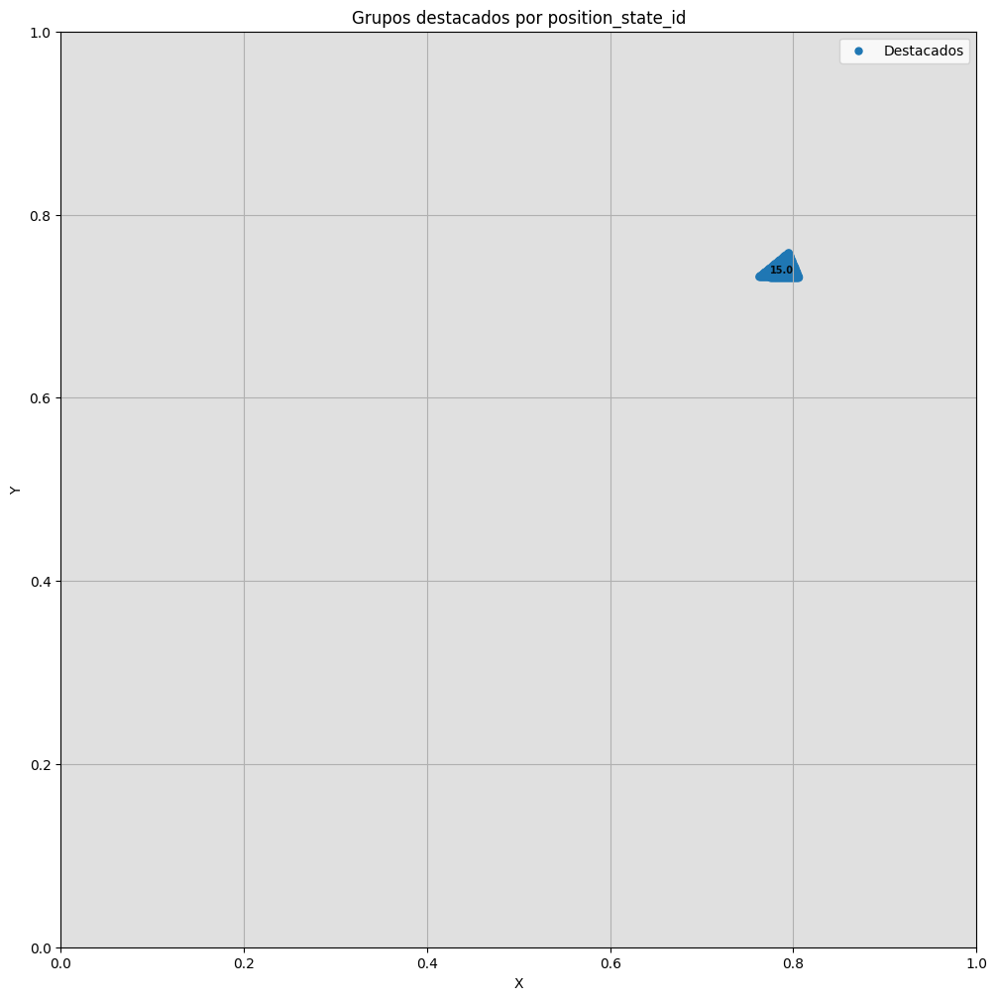

In [26]:
plot_position_states(apd, [15])

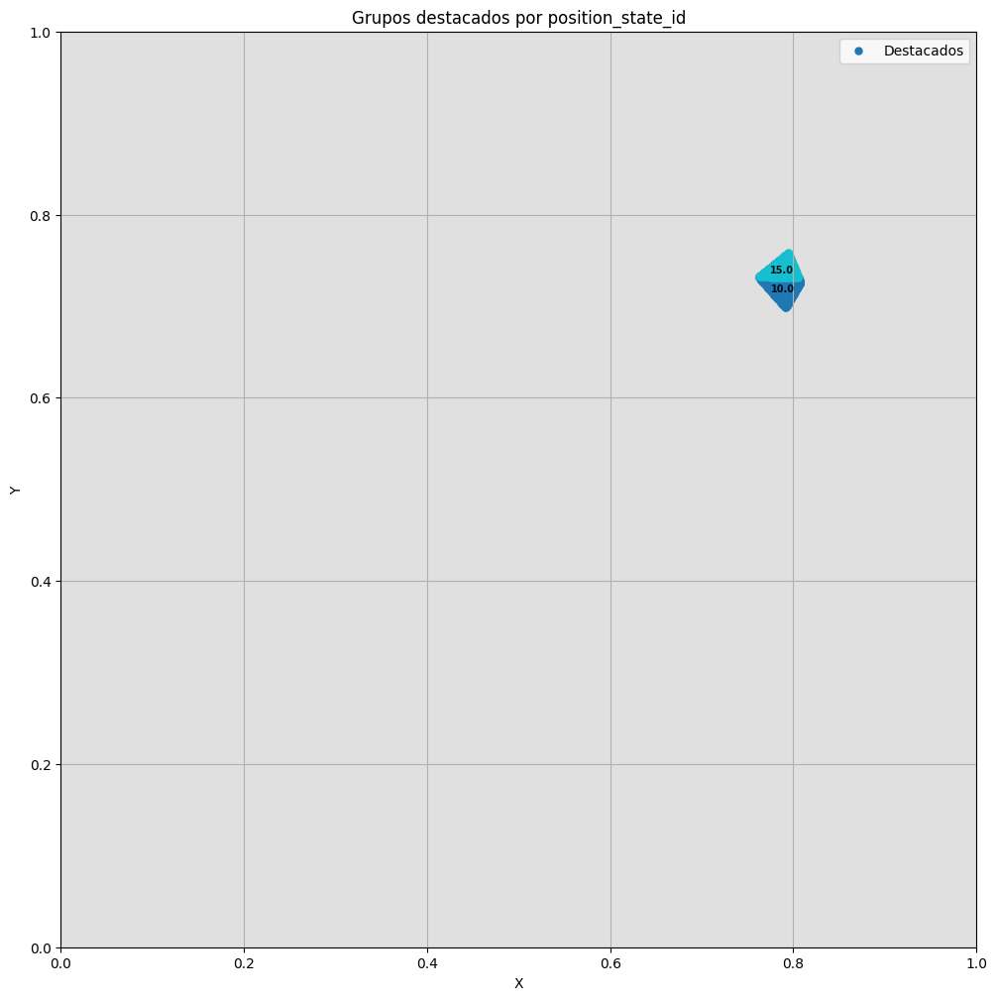

In [27]:
plot_position_states(apd, [15, 10])

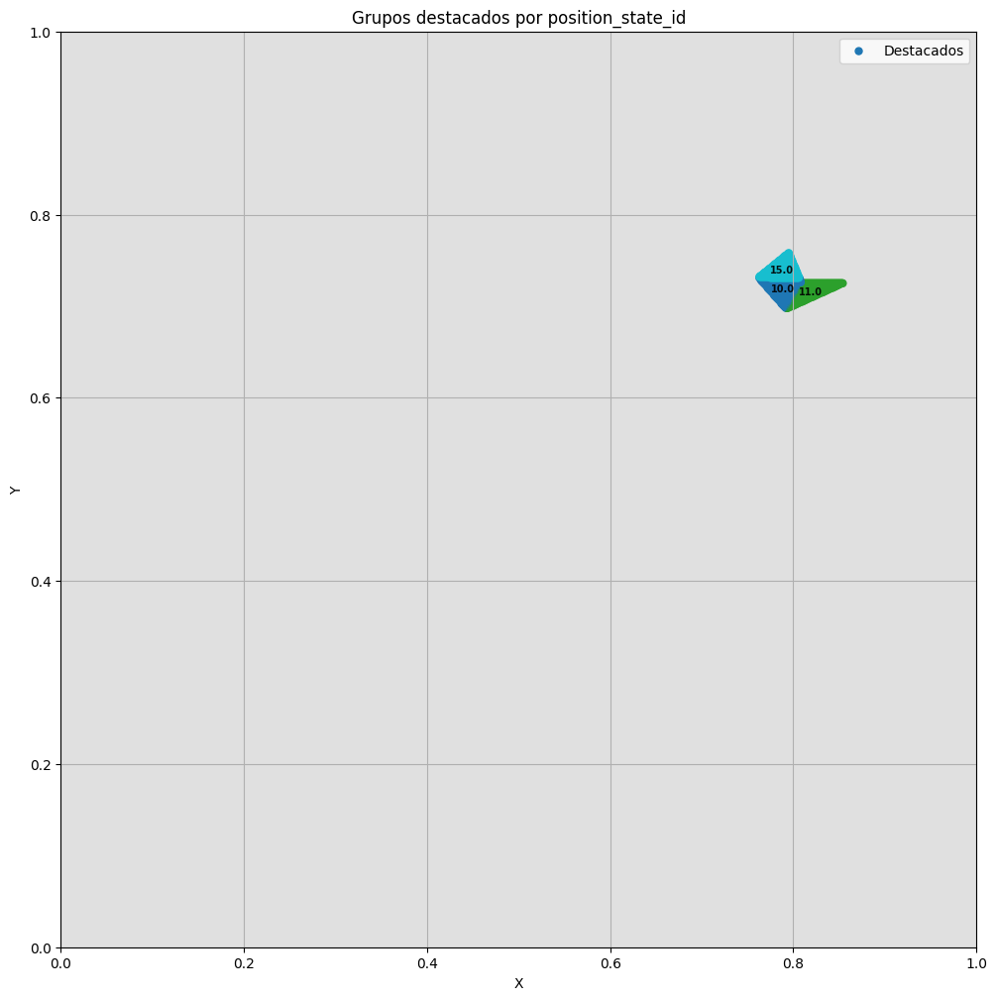

In [29]:
plot_position_states(apd, [15, 10, 11])

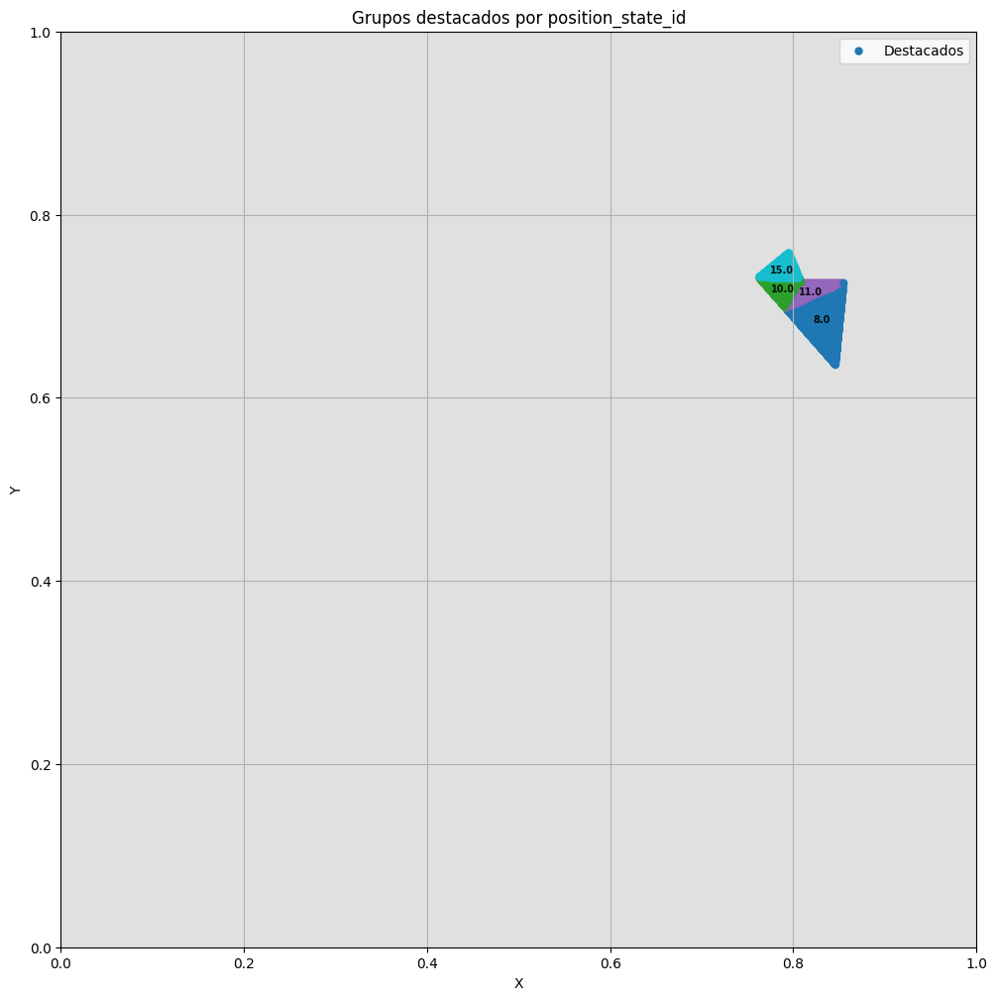

In [30]:
plot_position_states(apd, [15, 10, 11, 8])

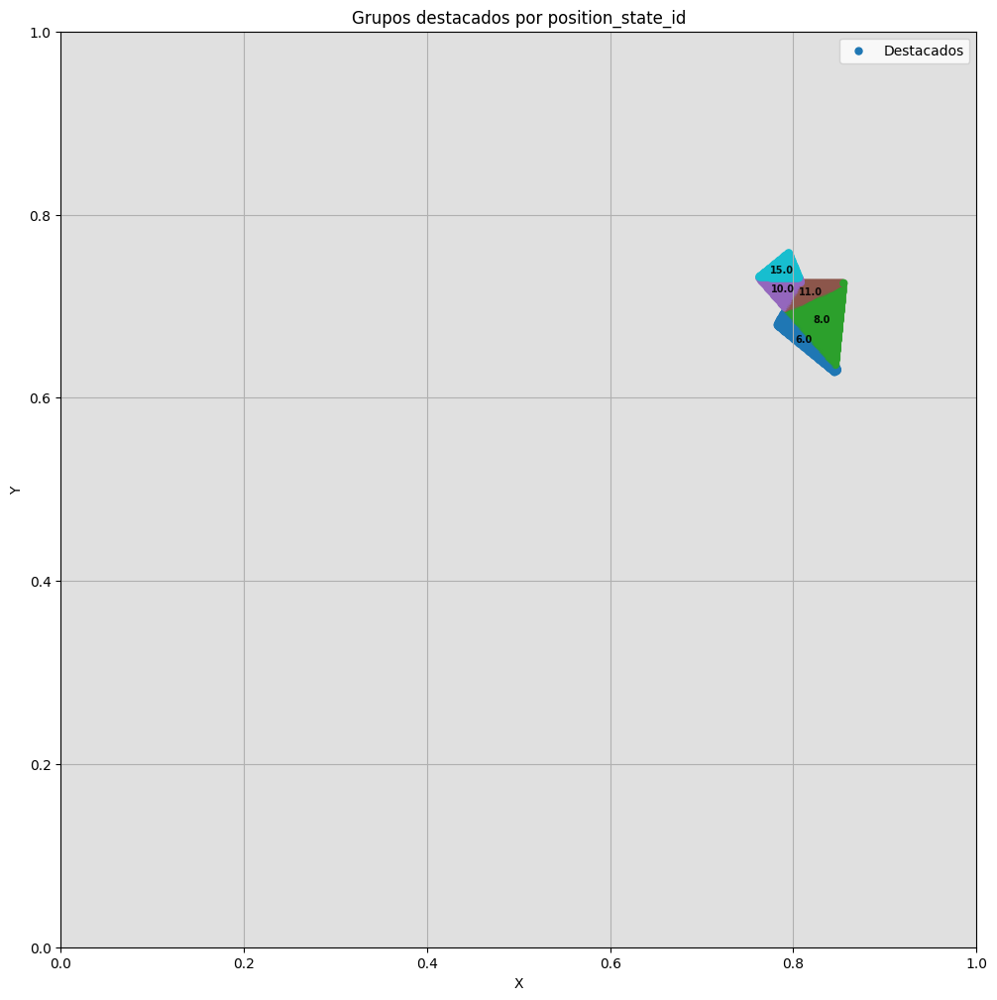

In [31]:
plot_position_states(apd, [15, 10, 11, 8, 6])

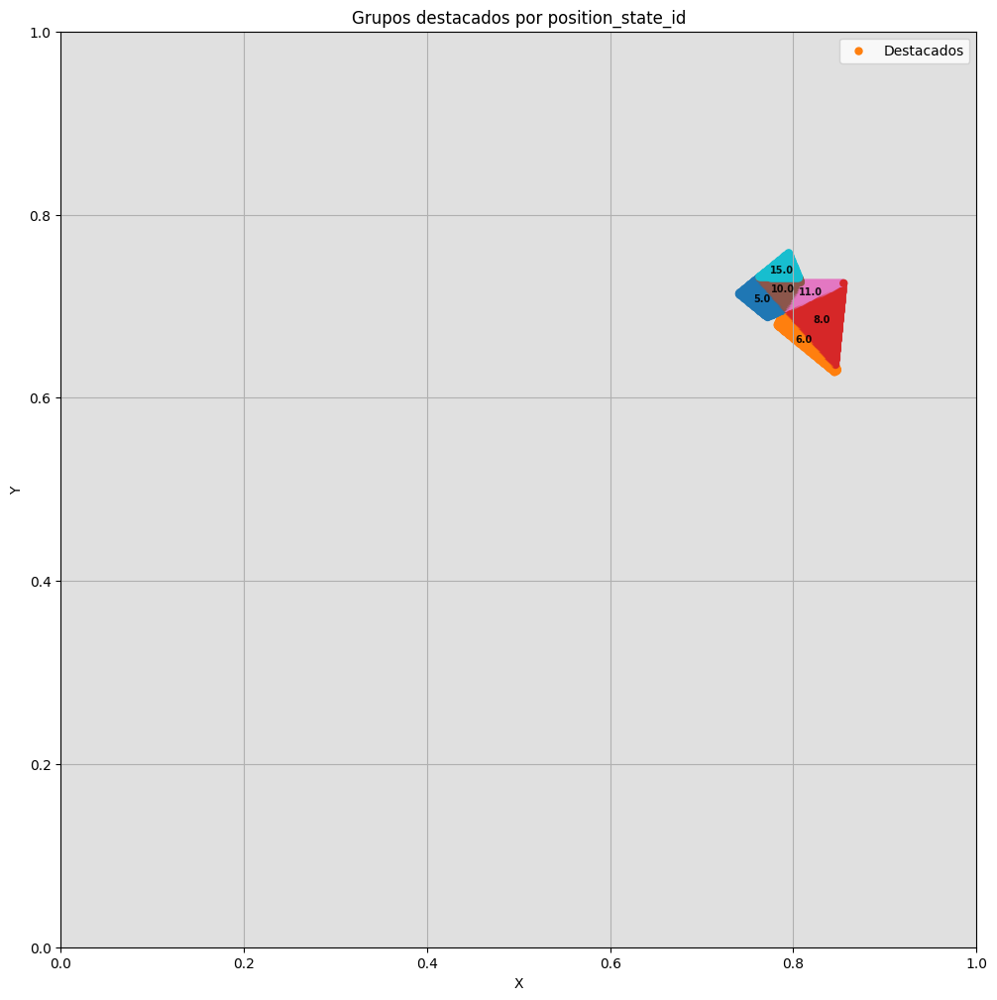

In [32]:
plot_position_states(apd, [15, 10, 11, 8, 6, 5])

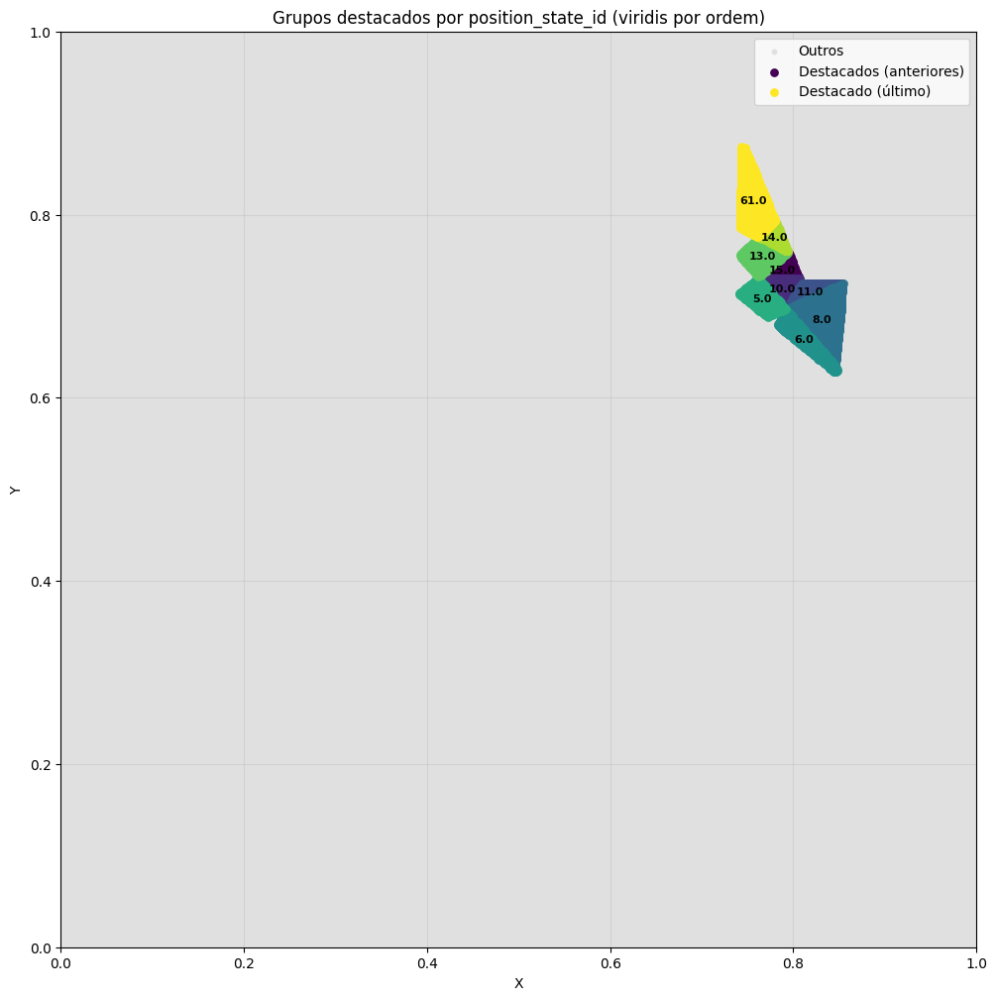

In [ ]:
plot_position_states_w_title(apd, [15, 10, 11,  8,  6,  5, 10, 15, 13, 14, 61])

In [19]:
gerar_graficos_expansao(apd, [15, 10, 11,  8,  6,  5, 10, 15, 13, 14, 61], titulo_base='Exemplo', modo='mono', file_tag='test_')

['imgs/test_etapa_00.png',
 'imgs/test_etapa_01.png',
 'imgs/test_etapa_02.png',
 'imgs/test_etapa_03.png',
 'imgs/test_etapa_04.png',
 'imgs/test_etapa_05.png',
 'imgs/test_etapa_06.png',
 'imgs/test_etapa_07.png',
 'imgs/test_etapa_08.png',
 'imgs/test_etapa_09.png',
 'imgs/test_etapa_10.png']

In [37]:
gerar_graficos_expansao(apd, [705, 698, 226, 225, 221, 219, 499, 219, 223, 224, 512], titulo_base='Exemplo', modo='mono', file_tag='test705_')

['imgs/test705_etapa_00.png',
 'imgs/test705_etapa_01.png',
 'imgs/test705_etapa_02.png',
 'imgs/test705_etapa_03.png',
 'imgs/test705_etapa_04.png',
 'imgs/test705_etapa_05.png',
 'imgs/test705_etapa_06.png',
 'imgs/test705_etapa_07.png',
 'imgs/test705_etapa_08.png',
 'imgs/test705_etapa_09.png',
 'imgs/test705_etapa_10.png']

In [39]:
# Se gerou com file_tag="GPT_Passo_"
gerar_gif("imgs", file_prefix="test_", nome_gif="test_trajetoria_gpt.gif", duracao=600, loop=0)

GIF salvo: imgs/test_trajetoria_gpt.gif  (11 frames)


'imgs/test_trajetoria_gpt.gif'

In [40]:
# Se gerou com file_tag="GPT_Passo_"
gerar_gif("imgs", file_prefix="test705_", nome_gif="test705_trajetoria_gpt.gif", duracao=600, loop=0)

GIF salvo: imgs/test705_trajetoria_gpt.gif  (11 frames)


'imgs/test705_trajetoria_gpt.gif'

# Probs Distribs

In [9]:
def _parse_xy(v):
    """
    Converte `pos` para (x, y).
    Aceita:
      - [x, y]
      - (x, y)
      - np.array([x, y])
      - string "[x, y]"
    """
    if isinstance(v, str):
        v = ast.literal_eval(v)

    if isinstance(v, (list, tuple, np.ndarray)) and len(v) == 2:
        return float(v[0]), float(v[1])

    raise ValueError(f"Valor inválido em pos: {v}")


def _resolve_step_col(step):
    """
    Aceita:
      - 'Passo 01'
      - 1, 2, ..., 10
    """
    if isinstance(step, str):
        return step
    if isinstance(step, int):
        return f"Passo {step:02d}"
    raise ValueError("`step` deve ser int ou str.")


def plot_next_id_probability_map_no_env(
    df_states,
    probs_df,
    current_id,
    *,
    step="Passo 01",
    pos_col="pos",
    id_col="position_state_id",
    probs_id_col=None,          # use se probs_df tiver o id em coluna
    xlim=(0.0, 1.0),
    ylim=(0.0, 1.0),
    figsize=(10, 10),
    cmap="viridis",
    current_color="lightgray",
    current_alpha=0.95,
    current_size=20,
    show_current_label=True,
    smooth_sigma=0.03,
    grid_size=250,
    min_support=1e-6,
    prob_power=1.0,
    show_colorbar=True,
    env_linewidth=2.0,
    env_color="gray",
    grid=True,
    grid_alpha=0.7,
    interpolation="bilinear",
):
    """
    Plota um mapa espacial suavizado de probabilidade do próximo id, sem depender de Env.

    Regras:
    - o id atual é pintado em cinza
    - os outros ids são pintados pela probabilidade do passo escolhido
    - a pintura é suavizada espacialmente com kernel gaussiano
    - o ambiente é desenhado manualmente entre 0 e 1 em x e y

    Parâmetros
    ----------
    df_states : pd.DataFrame
        DataFrame com colunas como [position_state_id, pos]
    probs_df : pd.DataFrame
        DataFrame com uma linha por id e colunas "Passo 01", "Passo 02", ...
    current_id : int | str
        id atual do animal
    step : str | int
        passo a visualizar
    """

    step_col = _resolve_step_col(step)

    # ----------------------------
    # prepara probs_df
    # ----------------------------
    probs = probs_df.copy()

    if probs_id_col is not None:
        probs = probs.set_index(probs_id_col)

    if step_col not in probs.columns:
        raise ValueError(
            f"Coluna '{step_col}' não encontrada em probs_df. "
            f"Colunas disponíveis: {list(probs.columns)}"
        )

    # ----------------------------
    # prepara df_states
    # ----------------------------
    df = df_states.copy()

    xy = df[pos_col].apply(_parse_xy)
    df["_x"] = [p[0] for p in xy]
    df["_y"] = [p[1] for p in xy]

    # tenta compatibilizar tipos do índice das probabilidades com o id do dataframe
    try:
        probs.index = probs.index.astype(df[id_col].dtype, copy=False)
    except Exception:
        pass

    # mapa de probabilidade do passo escolhido
    prob_map = probs[step_col].to_dict()
    df["_prob"] = df[id_col].map(prob_map).fillna(0.0)

    # separa id atual e outros
    df_current = df[df[id_col] == current_id].copy()
    df_other = df.copy() #df[df[id_col] != current_id].copy()

    if len(df_current) == 0:
        raise ValueError(f"Nenhuma linha encontrada para current_id={current_id}")

    # ajuste opcional de contraste
    if prob_power != 1.0:
        df_other["_prob"] = np.power(df_other["_prob"].clip(lower=0), prob_power)

    # ----------------------------
    # malha do ambiente
    # ----------------------------
    xmin, xmax = xlim
    ymin, ymax = ylim

    gx = np.linspace(xmin, xmax, grid_size)
    gy = np.linspace(ymin, ymax, grid_size)
    XX, YY = np.meshgrid(gx, gy)

    field = np.zeros_like(XX, dtype=float)
    support = np.zeros_like(XX, dtype=float)

    # ----------------------------
    # suavização espacial
    # ----------------------------
    if len(df_other) > 0 and df_other["_prob"].sum() > 0:
        xs = df_other["_x"].to_numpy(float)
        ys = df_other["_y"].to_numpy(float)
        ws = df_other["_prob"].to_numpy(float)

        for x0, y0, w in zip(xs, ys, ws):
            d2 = (XX - x0) ** 2 + (YY - y0) ** 2
            k = np.exp(-0.5 * d2 / (smooth_sigma ** 2))
            field += w * k
            support += k

        smoothed = np.zeros_like(field)
        valid = support > min_support
        smoothed[valid] = field[valid] / support[valid]

        # mascara regiões sem suporte para não “lavar” o ambiente todo
        mask = ~valid
        smoothed = np.ma.array(smoothed, mask=mask)
    else:
        smoothed = np.ma.array(np.zeros_like(field), mask=np.ones_like(field, dtype=bool))

    # ----------------------------
    # plot
    # ----------------------------
    fig, ax = plt.subplots(figsize=figsize)

    vmax = float(df_other["_prob"].max()) if len(df_other) > 0 else 1.0
    if vmax <= 0:
        vmax = 1.0

    im = ax.imshow(
        smoothed,
        extent=[xmin, xmax, ymin, ymax],
        origin="lower",
        cmap=cmap,
        norm=Normalize(vmin=0.0, vmax=1.0),
        interpolation=interpolation,
        alpha=0.95,
        zorder=1,
    )

    # # pontos do id atual em cinza
    # ax.scatter(
    #     df_current["_x"],
    #     df_current["_y"],
    #     s=current_size,
    #     color=current_color,
    #     alpha=current_alpha,
    #     zorder=3,
    #     label=f"token={current_id}",
    # )

    if show_current_label:
        cx = df_current["_x"].mean()
        cy = df_current["_y"].mean()
        ax.text(
            cx,
            cy,
            str(current_id),
            fontsize=10,
            color="black",
            ha="center",
            va="center",
            zorder=4,
        )

    # moldura manual do ambiente
    ax.plot([xmin, xmax], [ymin, ymin], color=env_color, linewidth=env_linewidth, zorder=5)
    ax.plot([xmin, xmax], [ymax, ymax], color=env_color, linewidth=env_linewidth, zorder=5)
    ax.plot([xmin, xmin], [ymin, ymax], color=env_color, linewidth=env_linewidth, zorder=5)
    ax.plot([xmax, xmax], [ymin, ymax], color=env_color, linewidth=env_linewidth, zorder=5)

    ax.set_xlim(xmin, xmax)
    ax.set_ylim(ymin, ymax)
    ax.set_aspect("equal")
    ax.set_xlabel("X")
    ax.set_ylabel("Y")
    ax.set_title(f"Probabilidade no {step_col}")

    if grid:
        ax.grid(True, alpha=grid_alpha)

    ax.legend(loc="upper right", frameon=True)

    if show_colorbar:
        cbar = plt.colorbar(im, ax=ax)
        cbar.set_label(f"Probabilidade ({step_col})")

    plt.tight_layout()
    plt.show()

    return fig, ax

In [32]:
import ast
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import Normalize


def _parse_xy(v):
    """
    Converte `pos` para (x, y).
    Aceita:
      - [x, y]
      - (x, y)
      - np.array([x, y])
      - string "[x, y]"
    """
    if isinstance(v, str):
        v = ast.literal_eval(v)

    if isinstance(v, (list, tuple, np.ndarray)) and len(v) == 2:
        return float(v[0]), float(v[1])

    raise ValueError(f"Valor inválido em pos: {v}")


def _resolve_step_col(step):
    """
    Aceita:
      - 'Passo 01'
      - 1, 2, ..., 10
    """
    if isinstance(step, str):
        return step
    if isinstance(step, int):
        return f"Passo {step:02d}"
    raise ValueError("`step` deve ser int ou str.")


def plot_next_id_probability_map_no_env(
    df_states,
    probs_df,
    current_id,
    *,
    step="Passo 01",
    pos_col="pos",
    id_col="position_state_id",
    xlim=(0.0, 1.0),
    ylim=(0.0, 1.0),
    figsize=(10, 10),
    cmap="viridis",
    current_color="lightgray",
    current_alpha=1.0,
    current_size=20,
    current_edgecolor="black",
    current_linewidth=0.8,
    show_current_label=True,
    smooth_sigma=0.03,
    grid_size=250,
    min_support=1e-6,
    prob_power=1.0,
    include_current_in_field=True,
    show_colorbar=True,
    colorbar_ticks=(0.0, 0.25, 0.5, 0.75, 1.0),
    env_linewidth=2.0,
    env_color="gray",
    grid=True,
    grid_alpha=0.7,
    interpolation="bilinear",
    show=True,
):
    """
    Plota um mapa espacial suavizado de probabilidade do próximo id, sem depender de Env.

    Suposição sobre probs_df:
    - índice = id
    - colunas = passos ("Passo 01", ..., "Passo 10")

    Parâmetros
    ----------
    df_states : pd.DataFrame
        DataFrame com colunas como [position_state_id, pos]
    probs_df : pd.DataFrame
        DataFrame com índice = id e colunas = passos
    current_id : int | str
        id atual do animal
    step : str | int
        passo a visualizar
    include_current_in_field : bool
        se True, o current_id também contribui para o mapa
    """

    step_col = _resolve_step_col(step)

    # ----------------------------
    # valida probs_df
    # ----------------------------
    probs = probs_df.copy()

    if step_col not in probs.columns:
        raise ValueError(
            f"Coluna '{step_col}' não encontrada em probs_df. "
            f"Colunas disponíveis: {list(probs.columns)}"
        )

    # ----------------------------
    # prepara df_states
    # ----------------------------
    df = df_states.copy()

    xy = df[pos_col].apply(_parse_xy)
    df["_x"] = [p[0] for p in xy]
    df["_y"] = [p[1] for p in xy]

    if len(df[df[id_col] == current_id]) == 0:
        raise ValueError(f"Nenhuma linha encontrada para current_id={current_id}")

    # tenta compatibilizar o índice do probs_df com o tipo do id do df
    try:
        probs.index = probs.index.astype(df[id_col].dtype, copy=False)
    except Exception:
        pass

    # ----------------------------
    # mapa de probabilidade do passo escolhido
    # cada linha do probs_df é um id
    # ----------------------------
    prob_map = probs[step_col].to_dict()
    df["_prob"] = df[id_col].map(prob_map).fillna(0.0)

    df_current = df[df[id_col] == current_id].copy()

    if include_current_in_field:
        df_field = df.copy()
    else:
        df_field = df[df[id_col] != current_id].copy()

    # ----------------------------
    # ajuste opcional de contraste
    # ----------------------------
    if prob_power != 1.0:
        df_field["_prob"] = np.power(df_field["_prob"].clip(lower=0), prob_power)

    # ----------------------------
    # malha do ambiente
    # ----------------------------
    xmin, xmax = xlim
    ymin, ymax = ylim

    gx = np.linspace(xmin, xmax, grid_size)
    gy = np.linspace(ymin, ymax, grid_size)
    XX, YY = np.meshgrid(gx, gy)

    field = np.zeros_like(XX, dtype=float)
    support = np.zeros_like(XX, dtype=float)

    # ----------------------------
    # suavização espacial
    # ----------------------------
    if len(df_field) > 0 and np.any(df_field["_prob"].to_numpy(float) > 0):
        xs = df_field["_x"].to_numpy(float)
        ys = df_field["_y"].to_numpy(float)
        ws = df_field["_prob"].to_numpy(float)

        for x0, y0, w in zip(xs, ys, ws):
            d2 = (XX - x0) ** 2 + (YY - y0) ** 2
            k = np.exp(-0.5 * d2 / (smooth_sigma ** 2))
            field += w * k
            support += k

        smoothed = np.zeros_like(field)
        valid = support > min_support
        smoothed[valid] = field[valid] / support[valid]
        smoothed = np.ma.array(smoothed, mask=~valid)
    else:
        smoothed = np.ma.array(np.zeros_like(field), mask=np.ones_like(field, dtype=bool))


    # ----------------------------
    # plot
    # ----------------------------
    fig, ax = plt.subplots(figsize=figsize)

    im = ax.imshow(
        smoothed/np.max(smoothed),
        extent=[xmin, xmax, ymin, ymax],
        origin="lower",
        cmap=cmap,
        norm=Normalize(vmin=0.0, vmax=1.),
        interpolation=interpolation,
        alpha=0.95,
        zorder=1,
    )

    # current_id destacado
    ax.scatter(
        df_current["_x"],
        df_current["_y"],
        s=current_size,
        color=current_color,
        alpha=current_alpha,
        edgecolors=current_edgecolor,
        linewidths=current_linewidth,
        zorder=3,
        label=f"id={current_id}",
    )

    if show_current_label:
        cx = df_current["_x"].mean()
        cy = df_current["_y"].mean()
        ax.text(
            cx,
            cy,
            str(current_id),
            fontsize=10,
            color="black",
            ha="center",
            va="center",
            zorder=4,
        )

    # moldura manual do ambiente
    ax.plot([xmin, xmax], [ymin, ymin], color=env_color, linewidth=env_linewidth, zorder=5)
    ax.plot([xmin, xmax], [ymax, ymax], color=env_color, linewidth=env_linewidth, zorder=5)
    ax.plot([xmin, xmin], [ymin, ymax], color=env_color, linewidth=env_linewidth, zorder=5)
    ax.plot([xmax, xmax], [ymin, ymax], color=env_color, linewidth=env_linewidth, zorder=5)

    ax.set_xlim(xmin, xmax)
    ax.set_ylim(ymin, ymax)
    ax.set_aspect("equal")
    ax.set_xlabel("X")
    ax.set_ylabel("Y")
    ax.set_title(f"Probabilidade no {step_col}")

    if grid:
        ax.grid(True, alpha=grid_alpha)

    ax.legend(loc="upper right", frameon=True)

    if show_colorbar:
        cbar = plt.colorbar(im, ax=ax, fraction=0.046, pad=0.04)
        cbar.set_label(f"Probabilidade ({step_col})")
        cbar.set_ticks(list(colorbar_ticks))

    plt.tight_layout()

    if show:
        plt.show()

    return fig, ax

In [15]:
distribs_probs

,Passo 01,Passo 02,Passo 03,Passo 04,Passo 05,Passo 06,Passo 07,Passo 08,Passo 09,Passo 10
0,2.598972e-17,2.493726e-14,1.383213e-13,3.338092e-11,4.016604e-05,3.673005e-06,6.472213e-09,1.864279e-05,1.864279e-05,1.864279e-05
1,2.681792e-15,2.477439e-12,5.376502e-14,1.601375e-10,9.529092e-14,1.311385e-06,3.285838e-07,2.026865e-06,2.026865e-06,2.026865e-06
2,1.596827e-14,2.873133e-16,6.649071e-13,3.450411e-16,9.930361e-12,5.815633e-15,1.402859e-14,5.183709e-10,5.183709e-10,5.183709e-10
3,1.640961e-14,1.991135e-14,8.181848e-14,3.952838e-16,4.258749e-14,1.613058e-16,9.555273e-15,4.195397e-10,4.195397e-10,4.195397e-10
4,1.347440e-15,5.029149e-18,2.961455e-14,9.340738e-15,1.715134e-12,2.520477e-11,3.903900e-15,9.767139e-10,9.767139e-10,9.767139e-10
...,...,...,...,...,...,...,...,...,...,...
943,2.755505e-21,2.575930e-17,2.346101e-15,5.191522e-11,6.254883e-12,1.498388e-07,6.093366e-08,2.967503e-09,2.967503e-09,2.967503e-09
944,1.143534e-07,1.401456e-15,2.688509e-08,3.940510e-15,6.210689e-14,4.465005e-17,5.771280e-17,8.144076e-15,8.144076e-15,8.144076e-15
945,7.203919e-15,7.494059e-13,5.414551e-13,1.139544e-09,6.801361e-10,6.376551e-14,5.830955e-12,7.832956e-13,7.832956e-13,7.832956e-13
946,1.416663e-14,2.542534e-16,1.349244e-10,2.788094e-16,1.075157e-10,1.183721e-11,2.131670e-12,1.830738e-09,1.830738e-09,1.830738e-09


No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.


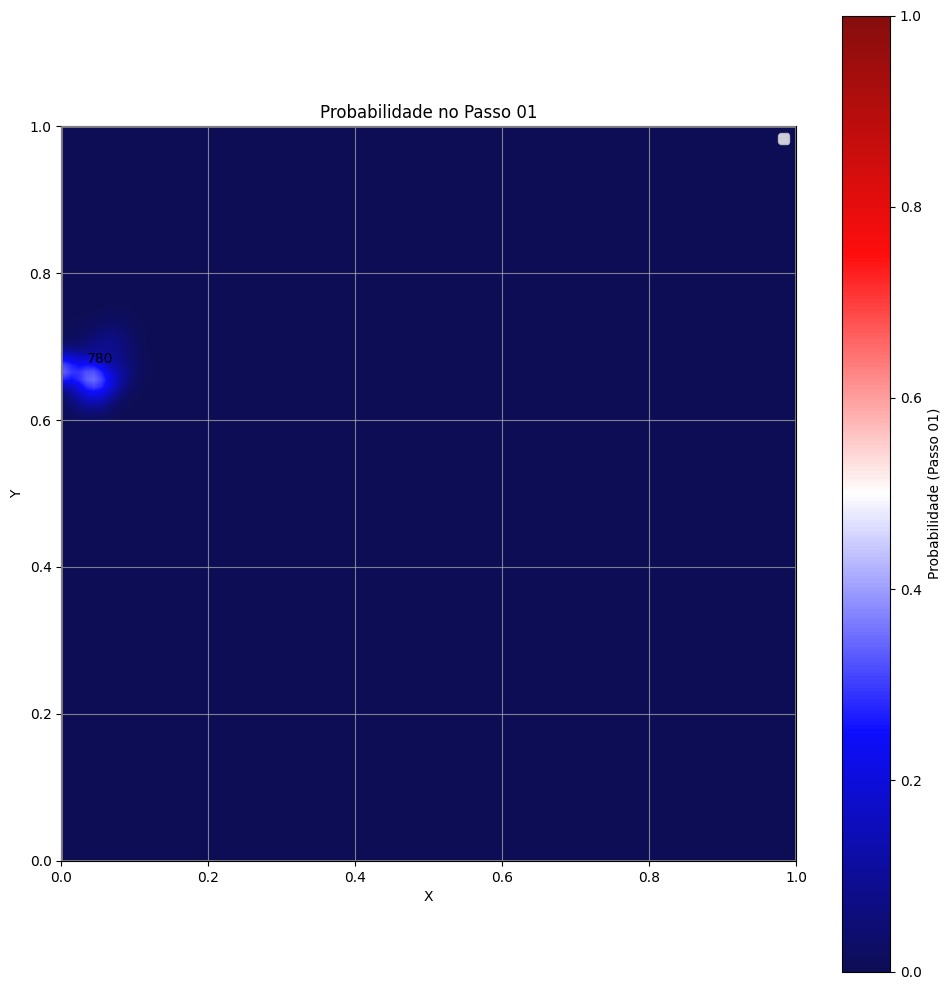

(<Figure size 1000x1000 with 2 Axes>,
 <Axes: title={'center': 'Probabilidade no Passo 01'}, xlabel='X', ylabel='Y'>)

In [17]:
plot_next_id_probability_map_no_env(
    df_states=df,
    probs_df=distribs_probs,
    current_id=780,
    step="Passo 01",
    smooth_sigma=0.015,
    grid_size=100,
    cmap='seismic'
    # prob_power=1.5,
)

In [34]:
ids_sequence_list = [784, 785, 351, 337, 323, 319, 320, 324, 323, 323]

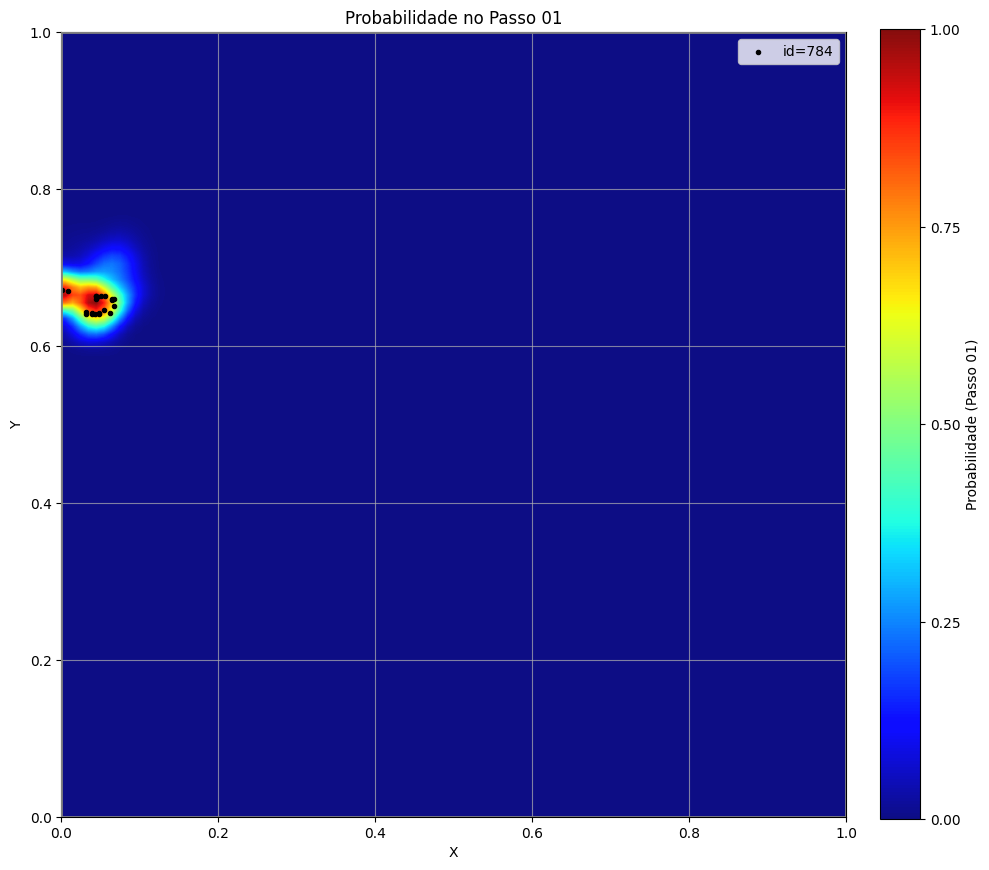

(<Figure size 1000x1000 with 2 Axes>,
 <Axes: title={'center': 'Probabilidade no Passo 01'}, xlabel='X', ylabel='Y'>)

In [45]:
step_to_plot = 1
plot_next_id_probability_map_no_env(
    df_states=df,
    probs_df=distribs_probs,
    current_id=ids_sequence_list[step_to_plot-1],
    step=step_to_plot,
    cmap="jet",
    smooth_sigma=0.015,
    grid_size=100,
    prob_power=1.,
    current_color="k",
    current_size=10,
    current_alpha=1,
    show_current_label=False,
)

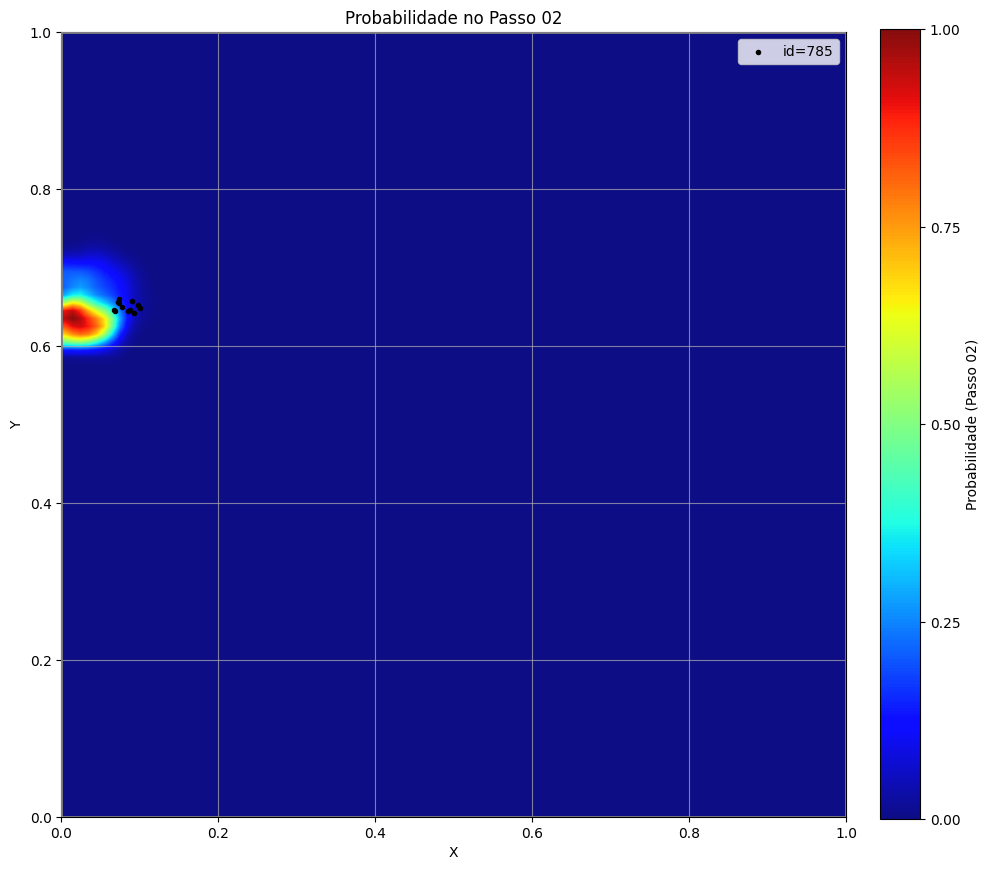

(<Figure size 1000x1000 with 2 Axes>,
 <Axes: title={'center': 'Probabilidade no Passo 02'}, xlabel='X', ylabel='Y'>)

In [46]:
step_to_plot = 2
plot_next_id_probability_map_no_env(
    df_states=df,
    probs_df=distribs_probs,
    current_id=ids_sequence_list[step_to_plot-1],
    step=step_to_plot,
    cmap="jet",
    smooth_sigma=0.015,
    grid_size=100,
    prob_power=1.,
    current_color="k",
    current_size=10,
    current_alpha=1,
    show_current_label=False,
)

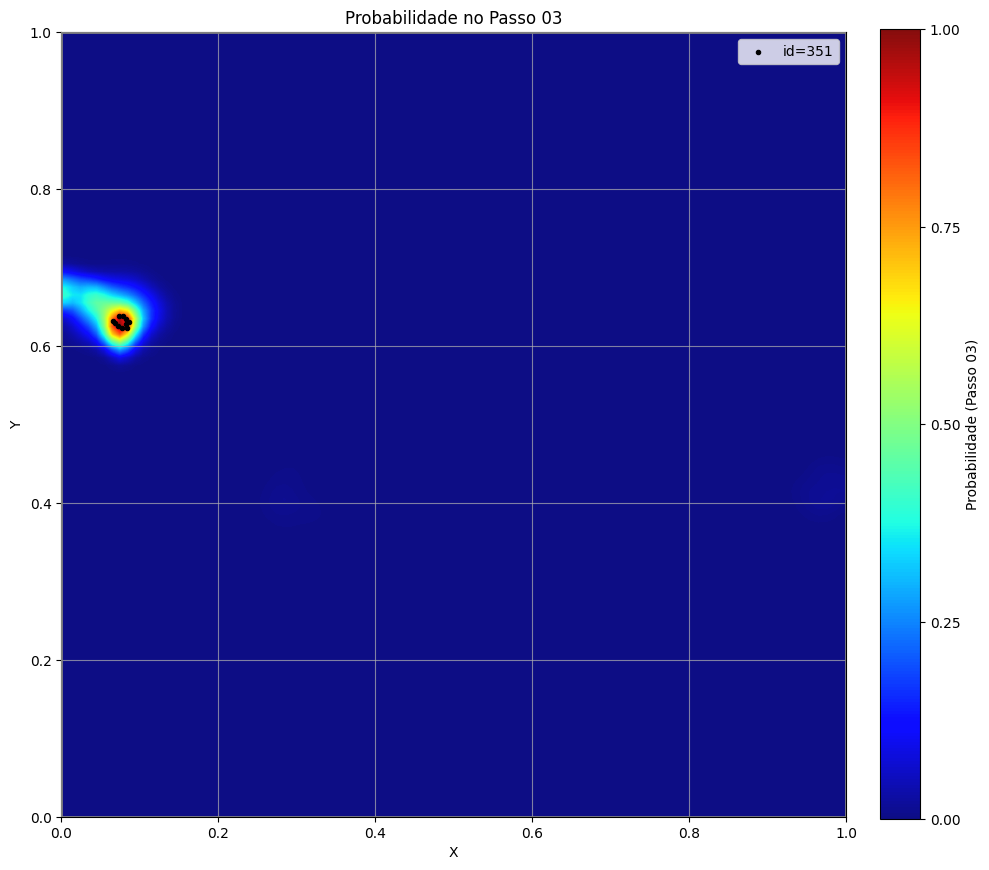

(<Figure size 1000x1000 with 2 Axes>,
 <Axes: title={'center': 'Probabilidade no Passo 03'}, xlabel='X', ylabel='Y'>)

In [47]:
step_to_plot = 3
plot_next_id_probability_map_no_env(
    df_states=df,
    probs_df=distribs_probs,
    current_id=ids_sequence_list[step_to_plot-1],
    step=step_to_plot,
    cmap="jet",
    smooth_sigma=0.015,
    grid_size=100,
    prob_power=1.,
    current_color="k",
    current_size=10,
    current_alpha=1,
    show_current_label=False,
)

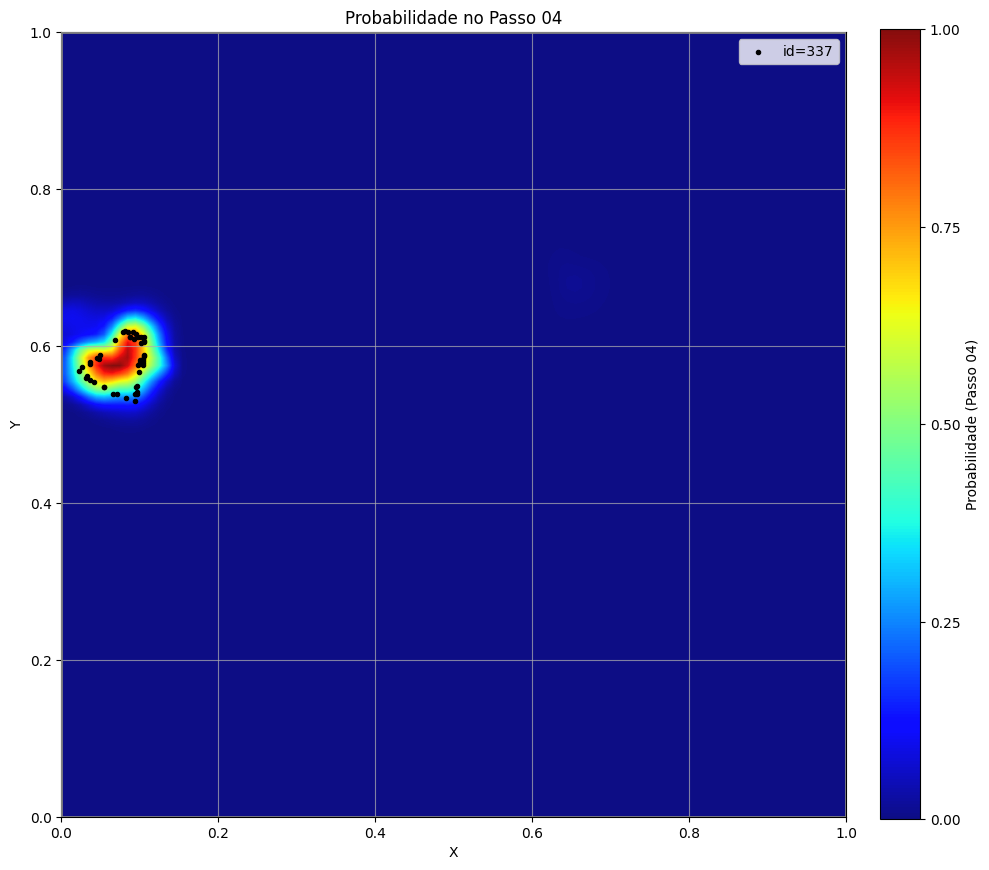

(<Figure size 1000x1000 with 2 Axes>,
 <Axes: title={'center': 'Probabilidade no Passo 04'}, xlabel='X', ylabel='Y'>)

In [48]:
step_to_plot = 4
plot_next_id_probability_map_no_env(
    df_states=df,
    probs_df=distribs_probs,
    current_id=ids_sequence_list[step_to_plot-1],
    step=step_to_plot,
    cmap="jet",
    smooth_sigma=0.015,
    grid_size=100,
    prob_power=1.,
    current_color="k",
    current_size=10,
    current_alpha=1,
    show_current_label=False,
)

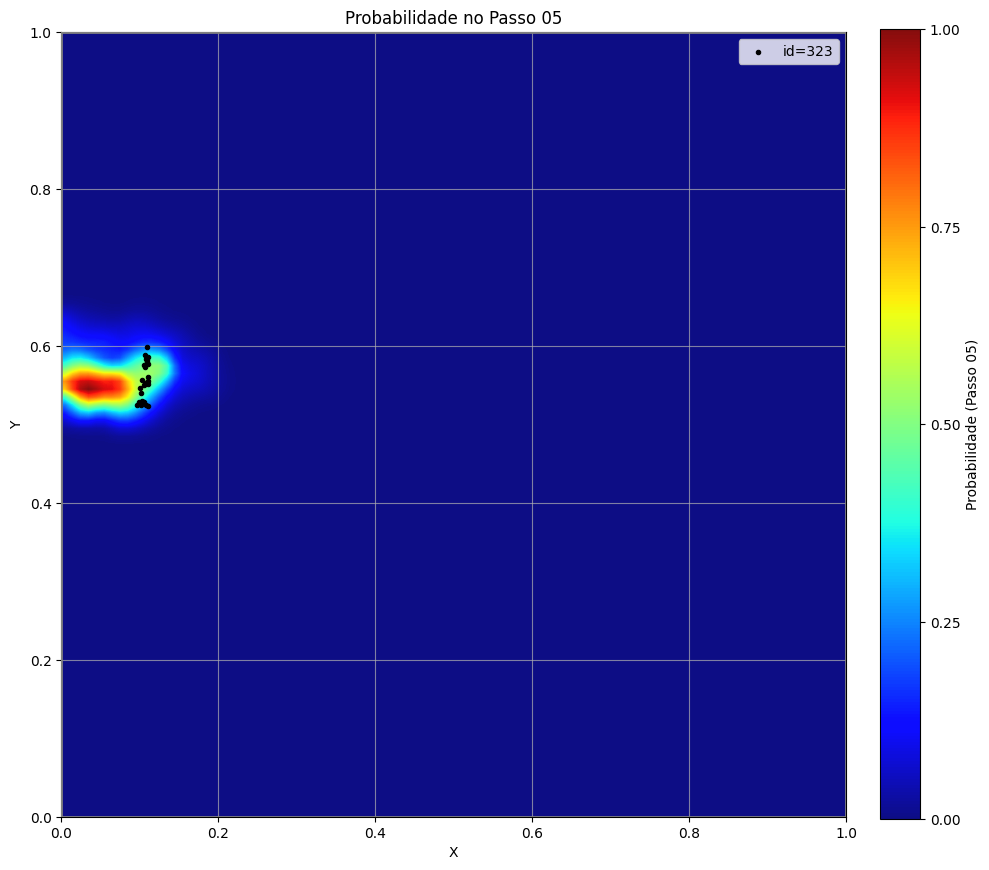

(<Figure size 1000x1000 with 2 Axes>,
 <Axes: title={'center': 'Probabilidade no Passo 05'}, xlabel='X', ylabel='Y'>)

In [49]:
step_to_plot = 5
plot_next_id_probability_map_no_env(
    df_states=df,
    probs_df=distribs_probs,
    current_id=ids_sequence_list[step_to_plot-1],
    step=step_to_plot,
    cmap="jet",
    smooth_sigma=0.015,
    grid_size=100,
    prob_power=1.,
    current_color="k",
    current_size=10,
    current_alpha=1,
    show_current_label=False,
)

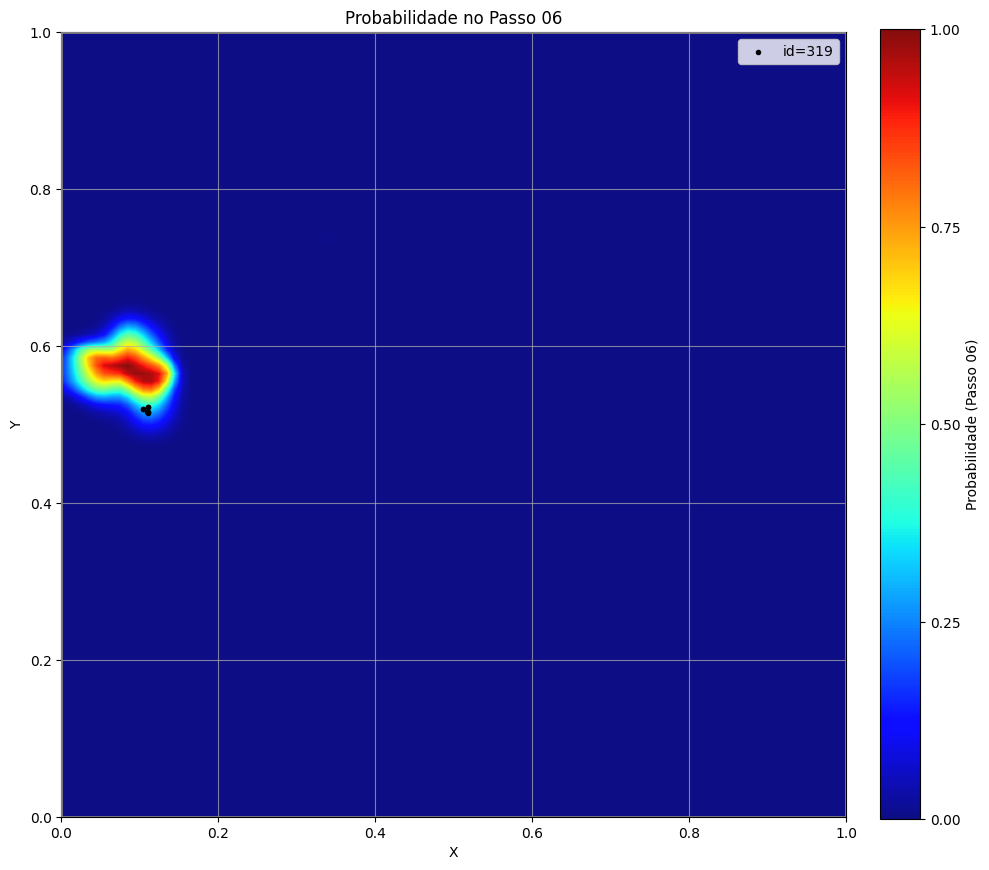

(<Figure size 1000x1000 with 2 Axes>,
 <Axes: title={'center': 'Probabilidade no Passo 06'}, xlabel='X', ylabel='Y'>)

In [50]:
step_to_plot = 6
plot_next_id_probability_map_no_env(
    df_states=df,
    probs_df=distribs_probs,
    current_id=ids_sequence_list[step_to_plot-1],
    step=step_to_plot,
    cmap="jet",
    smooth_sigma=0.015,
    grid_size=100,
    prob_power=1.,
    current_color="k",
    current_size=10,
    current_alpha=1,
    show_current_label=False,
)

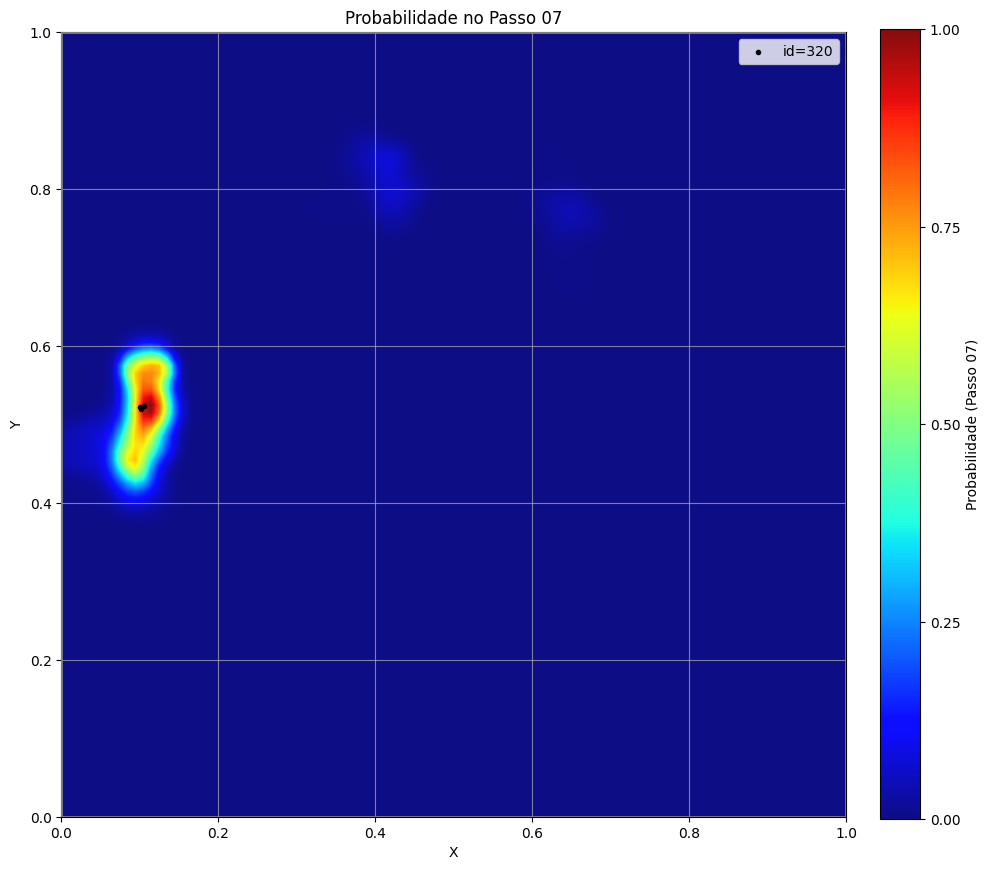

(<Figure size 1000x1000 with 2 Axes>,
 <Axes: title={'center': 'Probabilidade no Passo 07'}, xlabel='X', ylabel='Y'>)

In [51]:
step_to_plot = 7
plot_next_id_probability_map_no_env(
    df_states=df,
    probs_df=distribs_probs,
    current_id=ids_sequence_list[step_to_plot-1],
    step=step_to_plot,
    cmap="jet",
    smooth_sigma=0.015,
    grid_size=100,
    prob_power=1.,
    current_color="k",
    current_size=10,
    current_alpha=1,
    show_current_label=False,
)

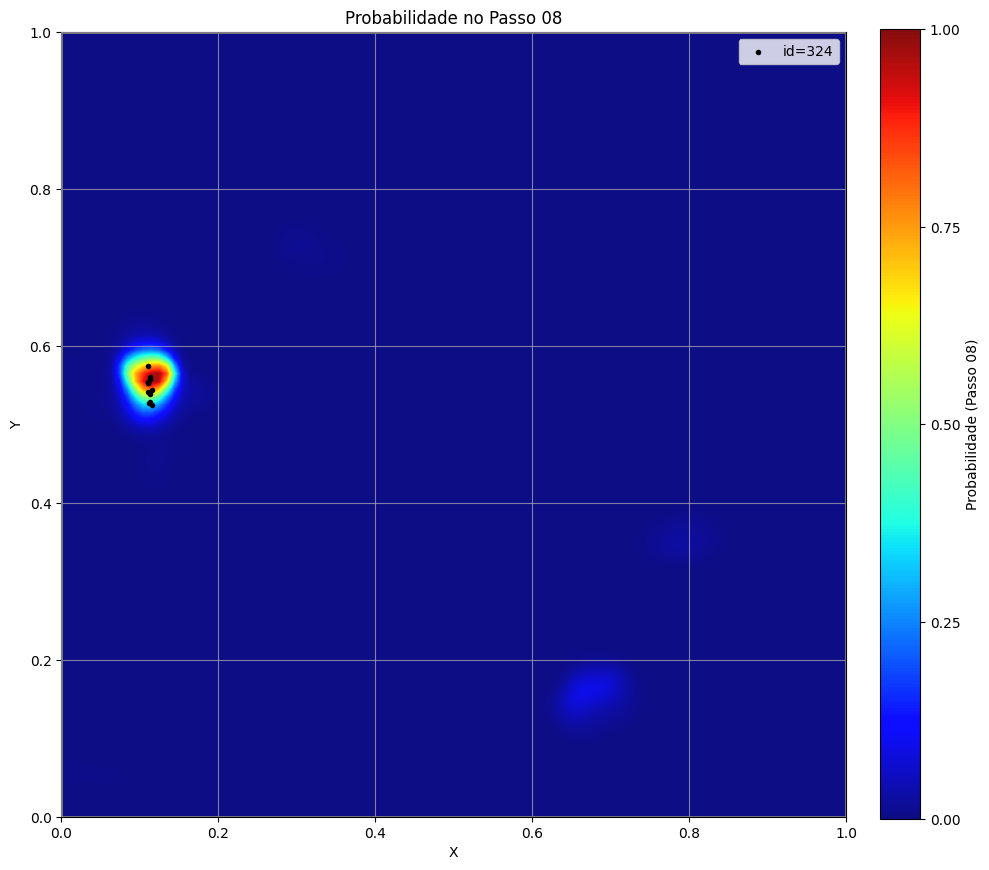

(<Figure size 1000x1000 with 2 Axes>,
 <Axes: title={'center': 'Probabilidade no Passo 08'}, xlabel='X', ylabel='Y'>)

In [52]:
step_to_plot = 8
plot_next_id_probability_map_no_env(
    df_states=df,
    probs_df=distribs_probs,
    current_id=ids_sequence_list[step_to_plot-1],
    step=step_to_plot,
    cmap="jet",
    smooth_sigma=0.015,
    grid_size=100,
    prob_power=1.,
    current_color="k",
    current_size=10,
    current_alpha=1,
    show_current_label=False,
)

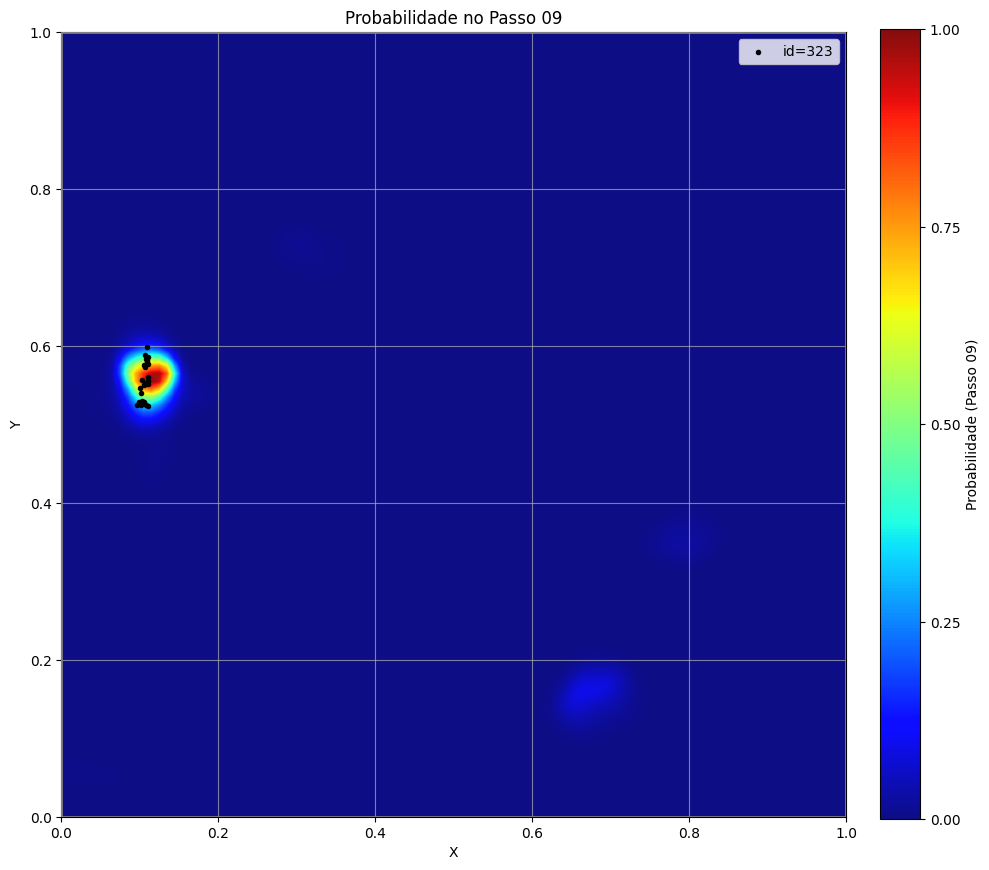

(<Figure size 1000x1000 with 2 Axes>,
 <Axes: title={'center': 'Probabilidade no Passo 09'}, xlabel='X', ylabel='Y'>)

In [53]:
step_to_plot = 9
plot_next_id_probability_map_no_env(
    df_states=df,
    probs_df=distribs_probs,
    current_id=ids_sequence_list[step_to_plot-1],
    step=step_to_plot,
    cmap="jet",
    smooth_sigma=0.015,
    grid_size=100,
    prob_power=1.,
    current_color="k",
    current_size=10,
    current_alpha=1,
    show_current_label=False,
)

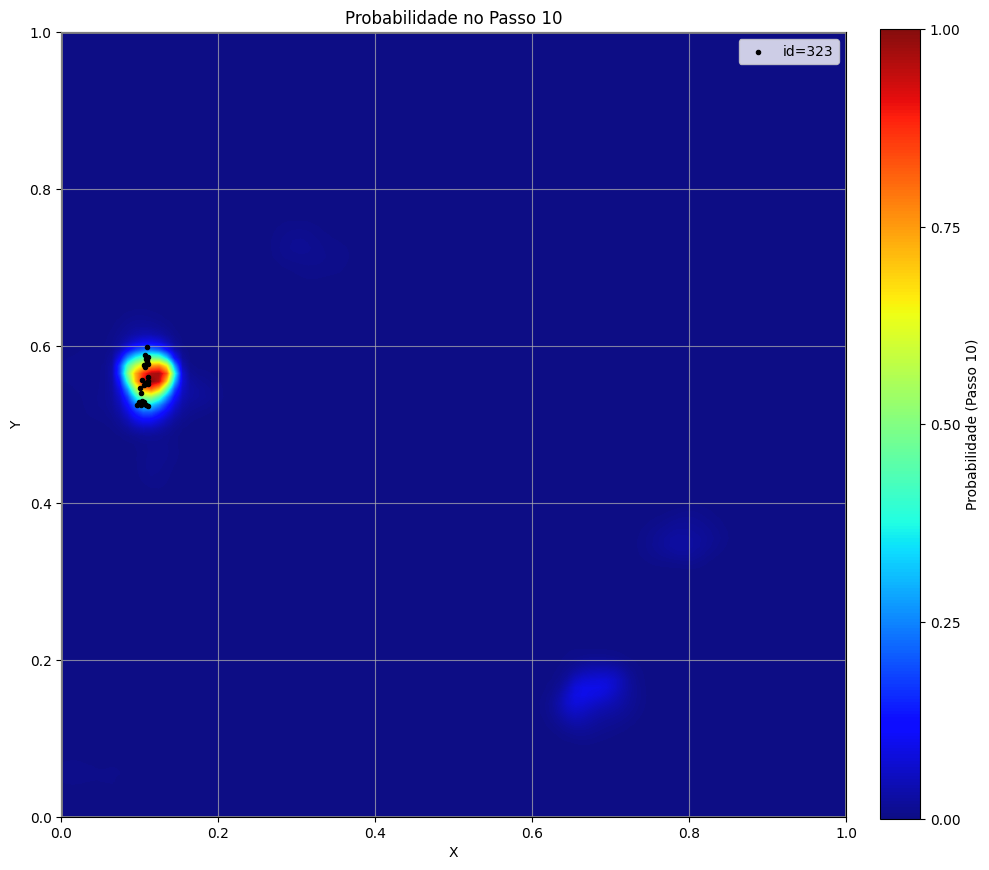

(<Figure size 1000x1000 with 2 Axes>,
 <Axes: title={'center': 'Probabilidade no Passo 10'}, xlabel='X', ylabel='Y'>)

In [54]:
step_to_plot = 10
plot_next_id_probability_map_no_env(
    df_states=df,
    probs_df=distribs_probs,
    current_id=ids_sequence_list[step_to_plot-1],
    step=step_to_plot,
    cmap="jet",
    smooth_sigma=0.015,
    grid_size=100,
    prob_power=1.,
    current_color="k",
    current_size=10,
    current_alpha=1,
    show_current_label=False,
)

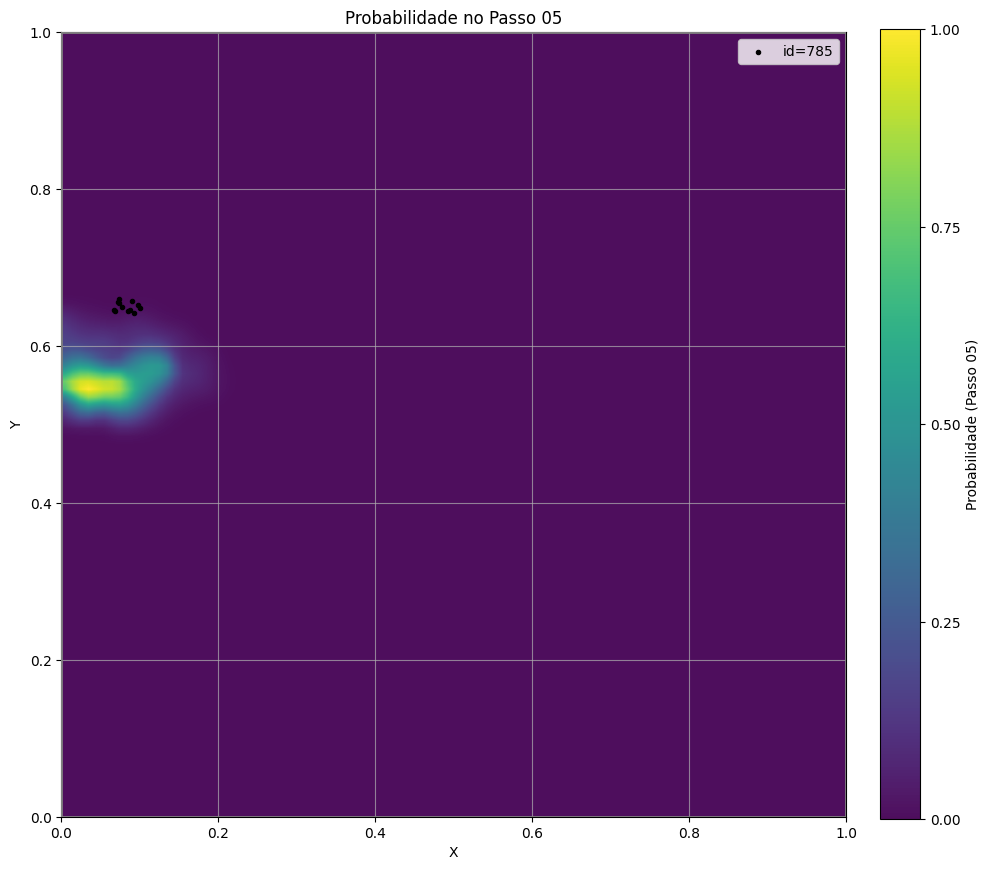

(<Figure size 1000x1000 with 2 Axes>,
 <Axes: title={'center': 'Probabilidade no Passo 05'}, xlabel='X', ylabel='Y'>)

In [33]:
plot_next_id_probability_map_no_env(
    df_states=df,
    probs_df=distribs_probs,
    current_id=785,
    step=5,
    cmap="viridis",
    smooth_sigma=0.015,
    grid_size=100,
    prob_power=1.,
    current_color="k",
    current_size=10,
    current_alpha=1,
    show_current_label=False,
)

In [128]:
def _parse_xy(v):
    if isinstance(v, str):
        v = ast.literal_eval(v)
    if isinstance(v, (list, tuple, np.ndarray)) and len(v) == 2:
        return float(v[0]), float(v[1])
    raise ValueError(f"Valor inválido em pos: {v}")


def _parse_head_vector(v):
    if isinstance(v, str):
        v = ast.literal_eval(v)
    if isinstance(v, (list, tuple, np.ndarray)) and len(v) == 2:
        return float(v[0]), float(v[1])
    raise ValueError(f"Valor inválido em head_direction: {v}")


def plot_position_states_with_env_and_circular_kde(
    df,
    ids,
    Env,
    num_of_cues=None,
    pos_col="pos",
    id_col="position_state_id",
    head_col="head_direction",
    theta_sampled_col=None,
    use_only_theta_sampled=False,
    colors=None,
    cmap="tab10",
    point_size=18,
    point_alpha=0.9,
    kde_points=360,
    bandwidth=0.35,
    fill=True,
    fill_alpha=0.18,
    show_mean_direction=False,
    mean_line_width=2.0,
    figsize=(16, 8),
    polar_rect=(0.56, 0.24, 0.25, 0.42),
    env_rect=(0.05, 0.10, 0.47, 0.82),
    cue_fontsize=12,
    cue_color="black",
    cue_offset=(0.0, 0.0),
    gridlines=True,
    legend_loc="lower left",
    legend_bbox_to_anchor=(1.15, 1.10),
):
    """
    Plota múltiplos position_state_id:
      - no ambiente RatInABox, com pontos coloridos por id
      - no polar plot, com KDE circular por id
      - legenda apenas no polar plot

    Parâmetros
    ----------
    ids : int | list[int]
        Um id ou lista de ids
    colors : list[str] | dict | None
        Se list, deve ter o mesmo comprimento de ids
        Se dict, deve mapear id -> cor
        Se None, usa cmap
    """

    if np.isscalar(ids):
        ids = [ids]
    ids = list(ids)

    if len(ids) == 0:
        raise ValueError("A lista `ids` está vazia.")

    # ----------------------------
    # cores
    # ----------------------------
    if colors is None:
        cm = plt.get_cmap(cmap, len(ids))
        color_map = {id_: cm(i) for i, id_ in enumerate(ids)}
    elif isinstance(colors, dict):
        color_map = colors
    else:
        if len(colors) != len(ids):
            raise ValueError("Se `colors` for lista, deve ter o mesmo comprimento de `ids`.")
        color_map = {id_: c for id_, c in zip(ids, colors)}

    # ----------------------------
    # figura
    # ----------------------------
    fig = plt.figure(figsize=figsize)

    ax_env = fig.add_axes(env_rect)
    Env.plot_environment(gridlines=gridlines, fig=fig, ax=ax_env)

    cue_positions = Env.objects["objects"]
    if num_of_cues is None:
        num_of_cues = len(cue_positions)

    for i in range(min(num_of_cues, len(cue_positions))):
        x_cue, y_cue = cue_positions[i]
        ax_env.annotate(
            text=str(i + 1),
            xy=(x_cue, y_cue),
            xytext=(x_cue + cue_offset[0], y_cue + cue_offset[1]),
            fontweight="bold",
            fontsize=cue_fontsize,
            color=cue_color,
        )

    ax_env.set_title("Ambiente com Pistas Numeradas")
    ax_env.set_xlabel("X")
    ax_env.set_ylabel("Y")

    ax_polar = fig.add_axes(polar_rect, projection="polar")
    legend_handles = []

    # ----------------------------
    # loop sobre ids
    # ----------------------------
    for id_ in ids:
        sdf_all = df[df[id_col] == id_].copy()

        if len(sdf_all) == 0:
            continue

        sdf_theta = sdf_all.copy()
        if use_only_theta_sampled:
            if theta_sampled_col is None:
                raise ValueError(
                    "use_only_theta_sampled=True, mas theta_sampled_col não foi informado."
                )
            if theta_sampled_col not in sdf_theta.columns:
                raise ValueError(f"A coluna '{theta_sampled_col}' não existe no dataframe.")
            sdf_theta = sdf_theta[sdf_theta[theta_sampled_col].astype(bool)].copy()

        color = color_map[id_]

        # pontos do ambiente: sempre usa todos os pontos do id
        xy = sdf_all[pos_col].apply(_parse_xy)
        x_values = np.array([p[0] for p in xy], dtype=float)
        y_values = np.array([p[1] for p in xy], dtype=float)

        ax_env.scatter(
            x_values,
            y_values,
            s=point_size,
            color=color,
            alpha=point_alpha,
            zorder=5,
        )

        # se não houver dados para theta depois do filtro, pula polar
        if len(sdf_theta) == 0:
            continue

        head_vecs = sdf_theta[head_col].apply(_parse_head_vector)
        dx = np.array([v[0] for v in head_vecs], dtype=float)
        dy = np.array([v[1] for v in head_vecs], dtype=float)

        theta_samples = np.mod(np.arctan2(dy, dx), 2 * np.pi)

        theta_grid = np.linspace(0, 2 * np.pi, kde_points, endpoint=False)
        diff = theta_grid[:, None] - theta_samples[None, :]
        diff = np.angle(np.exp(1j * diff))

        density = np.exp(-0.5 * (diff / bandwidth) ** 2).sum(axis=1)

        if density.max() > 0:
            density = density / density.max()

        theta_closed = np.r_[theta_grid, theta_grid[0]]
        density_closed = np.r_[density, density[0]]

        ax_polar.plot(theta_closed, density_closed, color=color, linewidth=2.5)

        if fill:
            ax_polar.fill(theta_closed, density_closed, color=color, alpha=fill_alpha)

        if show_mean_direction:
            mean_dx = dx.mean()
            mean_dy = dy.mean()
            mean_theta = np.mod(np.arctan2(mean_dy, mean_dx), 2 * np.pi)
            ax_polar.plot(
                [mean_theta, mean_theta],
                [0, 1.0],
                color=color,
                linewidth=mean_line_width,
            )

        legend_handles.append(
            Line2D([0], [0], color=color, lw=3, label=str(id_))
        )

    ax_polar.set_title("Distribuição de head_direction", pad=22)
    ax_polar.set_theta_zero_location("E")
    ax_polar.set_theta_direction(1)
    ax_polar.set_yticklabels([])
    ax_polar.grid(True)

    if legend_handles:
        ax_polar.legend(
            handles=legend_handles,
            title="position_state_id",
            loc=legend_loc,
            bbox_to_anchor=legend_bbox_to_anchor,
            frameon=True,
        )

    plt.show()

    return fig, (ax_env, ax_polar)

In [135]:
distribs_probs

,Passo 01,Passo 02,Passo 03,Passo 04,Passo 05,Passo 06,Passo 07,Passo 08,Passo 09,Passo 10
0,3.733144e-11,2.535789e-11,3.418911e-12,1.474400e-11,1.035879e-11,7.013101e-10,7.013101e-10,7.013101e-10,7.013101e-10,7.013101e-10
1,1.633742e-03,4.766837e-02,1.066357e-03,1.276592e-03,4.649818e-03,2.510545e-02,2.510545e-02,2.510545e-02,2.510545e-02,2.510545e-02
2,9.501031e-02,1.893770e-02,4.756216e-02,4.680143e-02,1.565142e-01,1.361480e-02,1.361480e-02,1.361480e-02,1.361480e-02,1.361480e-02
3,9.988304e-05,9.905570e-04,1.776355e-05,3.218167e-03,1.145704e-03,2.423014e-04,2.423014e-04,2.423014e-04,2.423014e-04,2.423014e-04
4,1.090578e-02,5.543185e-03,2.414116e-04,2.167431e-03,1.349156e-02,2.454410e-03,2.454410e-03,2.454410e-03,2.454410e-03,2.454410e-03
...,...,...,...,...,...,...,...,...,...,...
313,3.842112e-09,1.399710e-07,3.601841e-10,5.479781e-09,8.967101e-08,2.278932e-10,2.278932e-10,2.278932e-10,2.278932e-10,2.278932e-10
314,1.421186e-07,1.651138e-06,1.468253e-07,4.042578e-08,1.671000e-07,4.080760e-07,4.080760e-07,4.080760e-07,4.080760e-07,4.080760e-07
315,2.925285e-08,2.457175e-08,1.670535e-10,8.432850e-10,1.769332e-09,2.644688e-09,2.644688e-09,2.644688e-09,2.644688e-09,2.644688e-09
316,1.329890e-06,1.683778e-05,4.990804e-06,7.780559e-05,4.497102e-06,1.400089e-06,1.400089e-06,1.400089e-06,1.400089e-06,1.400089e-06


In [136]:
distribs_probs.sort_values('Passo 01', ascending=False).index[:3]

Index([207, 144, 2], dtype='int64')

In [137]:
colors = {
    160: "grey",
    207: "red",
    144: "orange",
    2: "yellow",
}

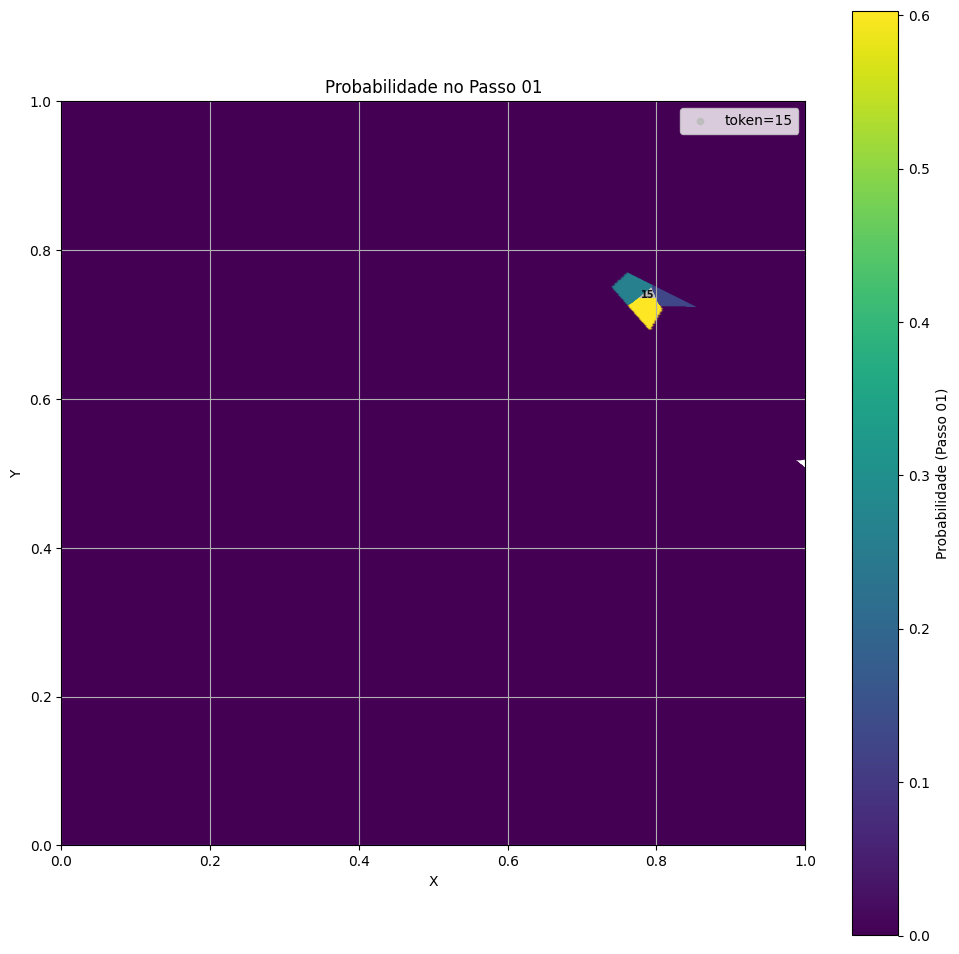

In [30]:
plot_prob_from_probs_df_w_pos(apd, distribs_probs, passo=0, token_atual=15,)

In [23]:
distribs_probs.head()

,Passo 01,Passo 02,Passo 03,Passo 04,Passo 05,Passo 06,Passo 07,Passo 08,Passo 09,Passo 10
0,3.662680e-06,3.177991e-06,4.009456e-06,1.145890e-06,2.520847e-06,0.000004,5.748174e-06,8.418958e-06,1.464796e-07,0.000228
1,2.157076e-07,1.543836e-07,1.201682e-07,5.364881e-08,7.375746e-07,0.000002,4.088467e-07,4.277045e-07,1.134515e-08,0.000080
2,1.828289e-04,1.275089e-05,1.952099e-06,6.359525e-07,6.182945e-04,0.000040,6.925649e-05,3.427698e-05,2.078097e-08,0.000072
3,7.179261e-06,5.824850e-01,8.121820e-05,5.431971e-01,3.116338e-06,0.000618,9.700832e-04,7.698964e-04,1.833539e-07,0.000396
4,1.745968e-05,2.277800e-05,6.613256e-06,8.439538e-06,5.750006e-06,0.000010,5.122279e-06,3.306124e-06,5.105923e-08,0.000084


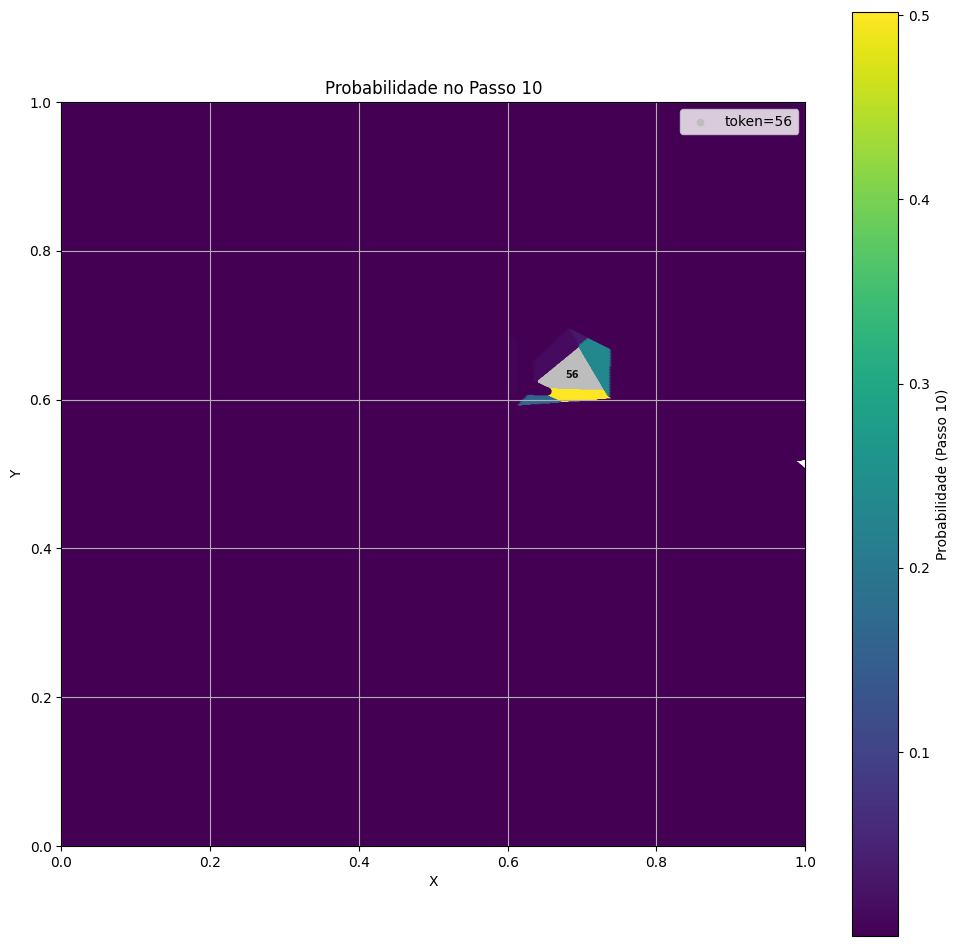

In [26]:
plot_prob_from_probs_df_w_pos(apd, distribs_probs, passo=9, token_atual=56,)

In [32]:
[705, 698, 226, 225, 221, 219, 499, 219, 223, 224, 512]

[705, 698, 226, 225, 221, 219, 499, 219, 223, 224, 512]

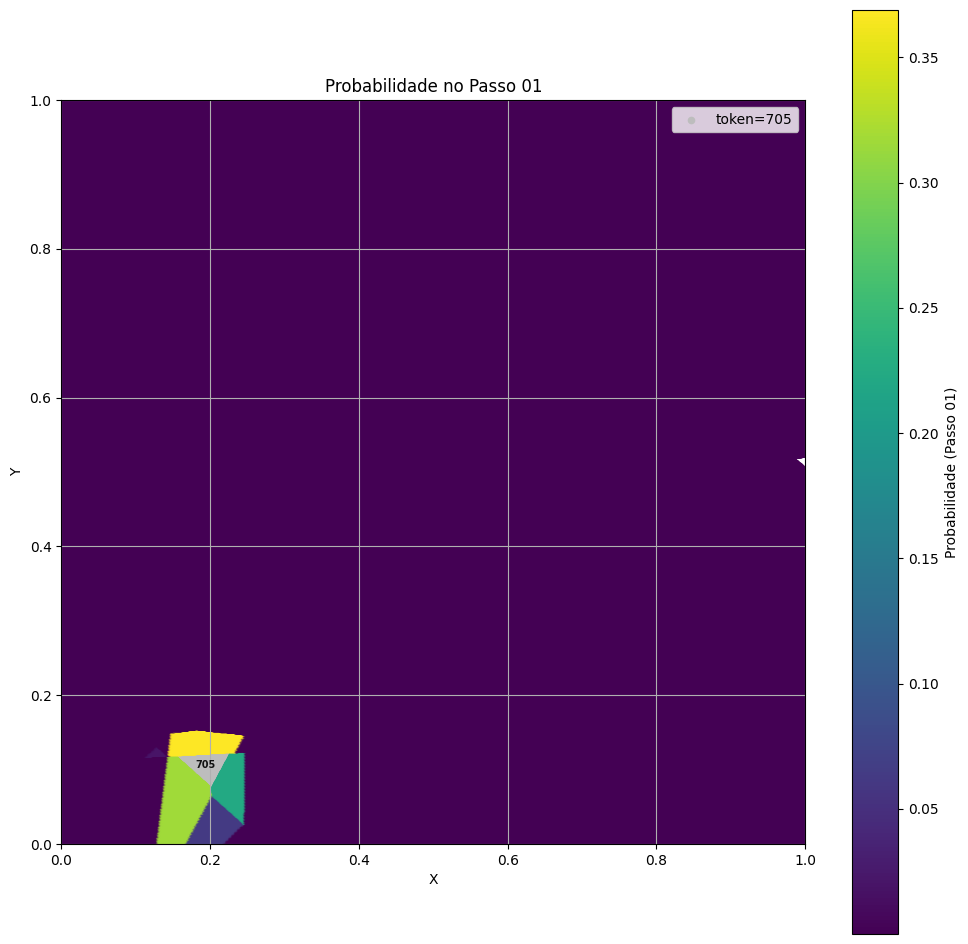

In [31]:
plot_prob_from_probs_df_w_pos(apd, distribs_probs705, passo=0, token_atual=705,)

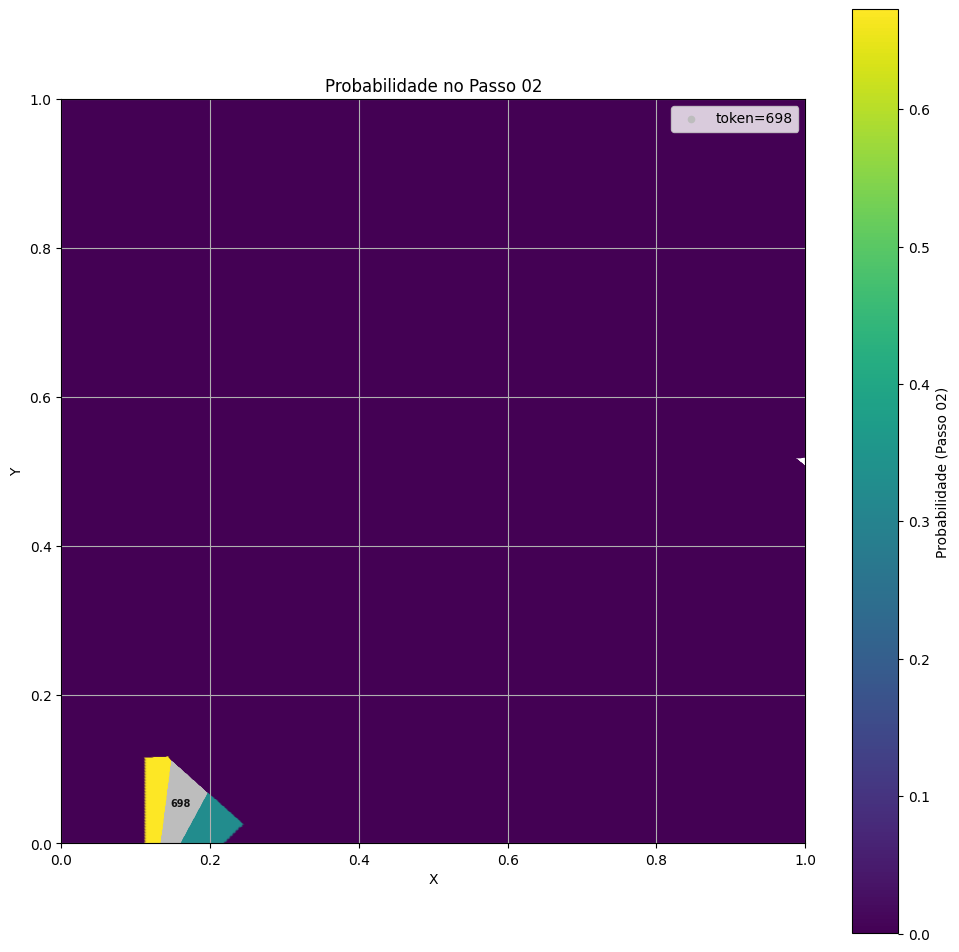

In [33]:
plot_prob_from_probs_df_w_pos(apd, distribs_probs705, passo=1, token_atual=698,)

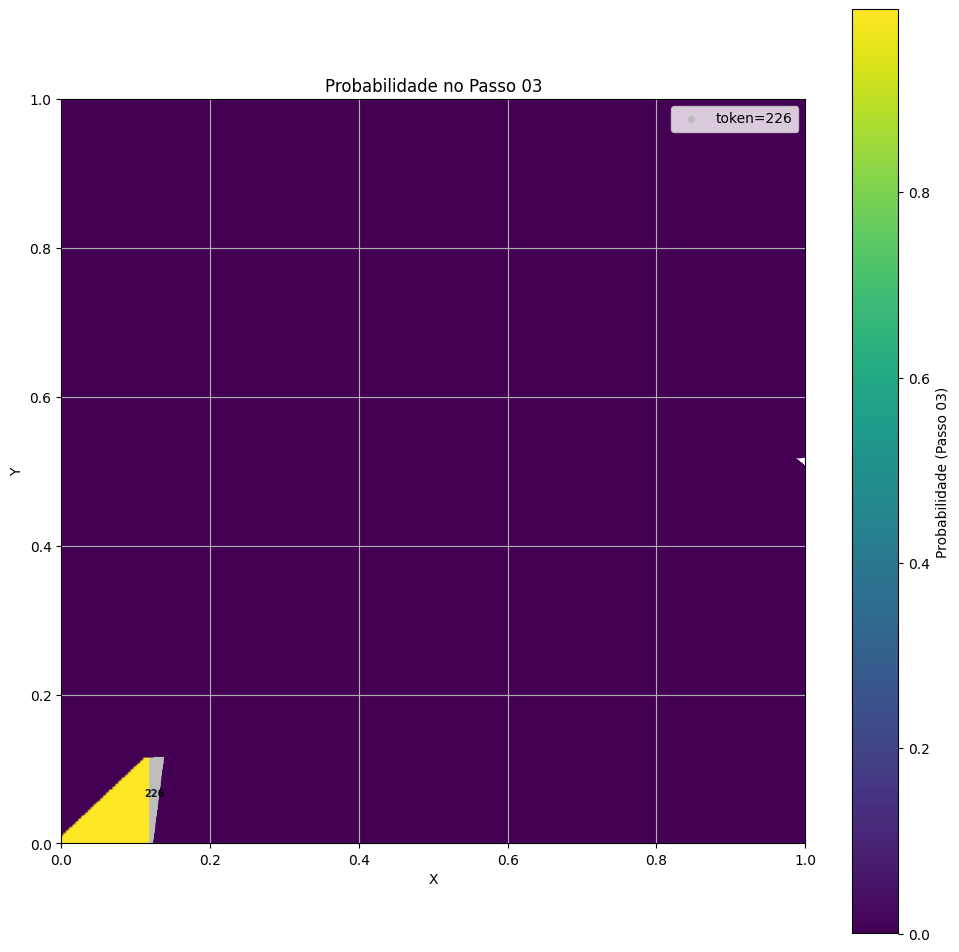

In [41]:
plot_prob_from_probs_df_w_pos(apd, distribs_probs705, passo=2, token_atual=226,)

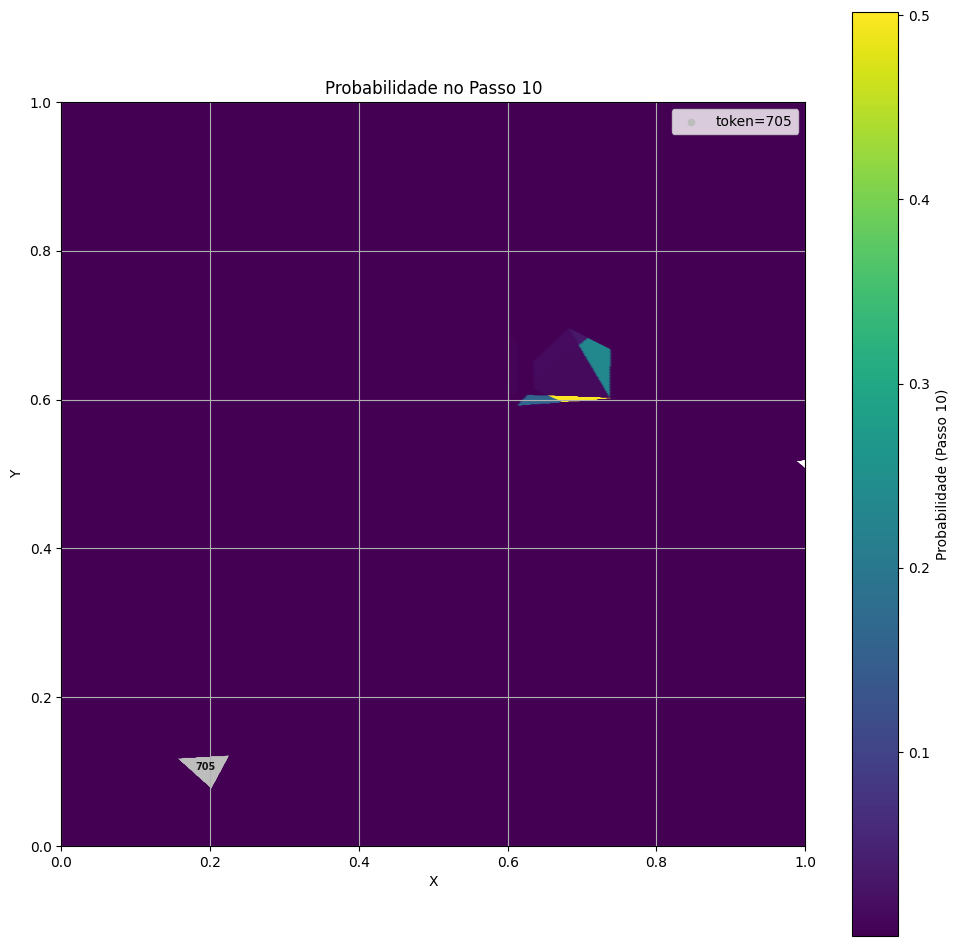

In [27]:
plot_prob_from_probs_df_w_pos(apd, distribs_probs, passo=9, token_atual=705,)

# Logits Distrib

In [15]:
def plot_logits_from_logits_df_w_pos(
    apd: pd.DataFrame,
    logits_df: pd.DataFrame,    # index: token_id (int ou str numérica), columns: "Passo 01", ...
    passo,                      # str ("Passo 04") OU int (0 = primeira coluna)
    token_atual: int,           # id do token atual (marcado em cinza)
    cmap: str = "viridis",
    annotate_means: bool = False,
    s_outros: int = 20,
    s_ref: int = 20,
    num_head: int = 0,
    mode: str = "",
):
    """
    Colore os pontos de `apd` pelo **logit** do token no `passo` escolhido.
    O `token_atual` é plotado em cinza.
    """
    # --- saneamento: garantir que o índice (tokens) seja int compatível com position_state_id ---
    def _to_int_index(df: pd.DataFrame) -> pd.DataFrame:
        if not np.issubdtype(df.index.dtype, np.integer):
            df = df.copy()
            df.index = df.index.astype(int)
        return df

    logits_df = _to_int_index(logits_df)

    # checagens
    required_cols = {"X", "Y", "position_state_id"}
    assert required_cols.issubset(apd.columns), f"apd precisa conter {required_cols}"

    # resolve a coluna do passo
    col = logits_df.columns[passo] if isinstance(passo, int) else passo
    if col not in logits_df.columns:
        raise ValueError(f"Coluna '{col}' não encontrada em logits_df")

    # separa atual e demais
    is_ref = (apd["position_state_id"] == token_atual)
    df_ref = apd[is_ref]
    df_outros = apd[~is_ref].copy()

    # série de logits no passo escolhido (indexada por id)
    logit_series = logits_df[col]

    # mapeia cada position_state_id -> logit no passo; ids ausentes viram NaN
    # substitui ±inf (ex.: após top-k) por NaN para o scatter ignorar
    df_outros["logit"] = df_outros["position_state_id"].map(logit_series).replace([np.inf, -np.inf], np.nan)

    # plot
    plt.figure(figsize=(12, 12))

    # 1) token atual em cinza
    if not df_ref.empty:
        plt.scatter(df_ref["X"], df_ref["Y"], c="#bdbdbd", s=s_ref, label=f"token={token_atual}")
        plt.annotate(str(token_atual),
                     (df_ref["X"].mean(), df_ref["Y"].mean()),
                     fontsize=7, ha="center", va="center", fontweight="bold", alpha=0.9)

    # 2) demais coloridos pelo logit (NaN são ignorados pelo scatter)
    if not df_outros.empty:
        sc = plt.scatter(df_outros["X"], df_outros["Y"], c=df_outros["logit"], cmap=cmap, s=s_outros)
        cbar = plt.colorbar(sc)
        cbar.set_label(f"Logit ({col})")

    # 3) anotação das médias por grupo (≠ token atual)
    if annotate_means and not df_outros.empty:
        medias = df_outros.groupby("position_state_id")[["X", "Y"]].mean().reset_index()
        for _, row in medias.iterrows():
            plt.annotate(str(int(row["position_state_id"])),
                         (row["X"], row["Y"]),
                         fontsize=7, ha="center", va="center", fontweight="bold", alpha=0.9)

    # layout
    plt.xlabel("X")
    plt.ylabel("Y")
    plt.title(f"Logits de Cada Região no {col}")
    plt.xlim(0, 1)
    plt.ylim(0, 1)
    plt.grid(True)
    plt.gca().set_aspect("equal", adjustable="box")
    plt.legend(loc="upper right")
    plt.show()


In [86]:
import ast
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import Normalize, TwoSlopeNorm


def _parse_xy(v):
    """
    Converte `pos` para (x, y).
    Aceita:
      - [x, y]
      - (x, y)
      - np.array([x, y])
      - string "[x, y]"
    """
    if isinstance(v, str):
        v = ast.literal_eval(v)

    if isinstance(v, (list, tuple, np.ndarray)) and len(v) == 2:
        return float(v[0]), float(v[1])

    raise ValueError(f"Valor inválido em pos: {v}")


def _resolve_step_col(step):
    """
    Aceita:
      - 'Passo 01'
      - 1, 2, ..., 10
    """
    if isinstance(step, str):
        return step
    if isinstance(step, int):
        return f"Passo {step:02d}"
    raise ValueError("`step` deve ser int ou str.")


def plot_next_id_logits_map_no_env(
    df_states,
    logits_df,
    current_id,
    *,
    step="Passo 01",
    pos_col="pos",
    id_col="position_state_id",
    logits_id_col=None,
    xlim=(0.0, 1.0),
    ylim=(0.0, 1.0),
    figsize=(10, 10),
    cmap="coolwarm",
    current_color="lightgray",
    current_alpha=0.95,
    current_size=20,
    show_current_label=True,
    smooth_sigma=0.03,
    grid_size=250,
    min_support=1e-6,
    logit_power=1.0,
    preserve_sign=True,
    include_current_in_field=True,
    center_colormap_at_zero=True,
    show_colorbar=True,
    env_linewidth=2.0,
    env_color="gray",
    grid=True,
    grid_alpha=0.7,
    interpolation="bilinear",
    colorbar_num_ticks=5,
):
    """
    Plota um mapa espacial suavizado de logits do próximo id, sem depender de Env.

    Regras:
    - plota apenas a coluna selecionada por `step`
    - mas a escala da colorbar é calculada usando TODO o dataframe de logits
    - assim, todos os plots compartilham a mesma escala de cores
    """

    step_col = _resolve_step_col(step)

    # ----------------------------
    # prepara logits_df
    # ----------------------------
    logits = logits_df.copy()

    if logits_id_col is not None:
        logits = logits.set_index(logits_id_col)

    if step_col not in logits.columns:
        raise ValueError(
            f"Coluna '{step_col}' não encontrada em logits_df. "
            f"Colunas disponíveis: {list(logits.columns)}"
        )

    # ----------------------------
    # prepara df_states
    # ----------------------------
    df = df_states.copy()

    xy = df[pos_col].apply(_parse_xy)
    df["_x"] = [p[0] for p in xy]
    df["_y"] = [p[1] for p in xy]

    try:
        logits.index = logits.index.astype(df[id_col].dtype, copy=False)
    except Exception:
        pass

    # mapa de logits apenas do passo escolhido
    logit_map = logits[step_col].to_dict()
    df["_logit"] = df[id_col].map(logit_map).fillna(0.0)

    df_current = df[df[id_col] == current_id].copy()
    df_field = df.copy() if include_current_in_field else df[df[id_col] != current_id].copy()

    if len(df_current) == 0:
        raise ValueError(f"Nenhuma linha encontrada para current_id={current_id}")

    # ----------------------------
    # ajuste opcional de contraste
    # ----------------------------
    if logit_power != 1.0:
        vals = df_field["_logit"].to_numpy(float)
        if preserve_sign:
            vals = np.sign(vals) * (np.abs(vals) ** logit_power)
        else:
            vals = vals ** logit_power
        df_field["_logit"] = vals

    # ----------------------------
    # malha do ambiente
    # ----------------------------
    xmin, xmax = xlim
    ymin, ymax = ylim

    gx = np.linspace(xmin, xmax, grid_size)
    gy = np.linspace(ymin, ymax, grid_size)
    XX, YY = np.meshgrid(gx, gy)

    field = np.zeros_like(XX, dtype=float)
    support = np.zeros_like(XX, dtype=float)

    # ----------------------------
    # suavização espacial
    # ----------------------------
    if len(df_field) > 0 and np.any(np.abs(df_field["_logit"].to_numpy(float)) > 0):
        xs = df_field["_x"].to_numpy(float)
        ys = df_field["_y"].to_numpy(float)
        ws = df_field["_logit"].to_numpy(float)

        for x0, y0, w in zip(xs, ys, ws):
            d2 = (XX - x0) ** 2 + (YY - y0) ** 2
            k = np.exp(-0.5 * d2 / (smooth_sigma ** 2))
            field += w * k
            support += k

        smoothed = np.zeros_like(field)
        valid = support > min_support
        smoothed[valid] = field[valid] / support[valid]
        smoothed = np.ma.array(smoothed, mask=~valid)
    else:
        smoothed = np.ma.array(np.zeros_like(field), mask=np.ones_like(field, dtype=bool))

    # ----------------------------
    # escala global da cor
    # usa TODO o dataframe de logits
    # ----------------------------
    all_logits = logits.to_numpy(dtype=float)
    finite_logits = all_logits[np.isfinite(all_logits)]

    if finite_logits.size == 0:
        vmin_global, vmax_global = -1.0, 1.0
    else:
        vmin_global = float(finite_logits.min())
        vmax_global = float(finite_logits.max())

        if vmin_global == vmax_global:
            eps = 1e-6 if vmin_global == 0 else abs(vmin_global) * 1e-6
            vmin_global -= eps
            vmax_global += eps

    if center_colormap_at_zero and (vmin_global < 0 < vmax_global):
        vmax_abs = max(abs(vmin_global), abs(vmax_global))
        norm = TwoSlopeNorm(vmin=-vmax_abs, vcenter=0.0, vmax=vmax_abs)
        tick_min, tick_max = -vmax_abs, vmax_abs
    else:
        norm = Normalize(vmin=vmin_global, vmax=vmax_global)
        tick_min, tick_max = vmin_global, vmax_global

    # ----------------------------
    # plot
    # ----------------------------
    fig, ax = plt.subplots(figsize=figsize)

    im = ax.imshow(
        smoothed,
        extent=[xmin, xmax, ymin, ymax],
        origin="lower",
        cmap=cmap,
        norm=norm,
        interpolation=interpolation,
        alpha=0.95,
        zorder=1,
    )

    # current_id destacado
    ax.scatter(
        df_current["_x"],
        df_current["_y"],
        s=current_size,
        color=current_color,
        alpha=current_alpha,
        zorder=3,
        label=f"id={current_id}",
    )

    if show_current_label:
        cx = df_current["_x"].mean()
        cy = df_current["_y"].mean()
        ax.text(
            cx,
            cy,
            str(current_id),
            fontsize=10,
            color="black",
            ha="center",
            va="center",
            zorder=4,
        )

    # moldura manual do ambiente
    ax.plot([xmin, xmax], [ymin, ymin], color=env_color, linewidth=env_linewidth, zorder=5)
    ax.plot([xmin, xmax], [ymax, ymax], color=env_color, linewidth=env_linewidth, zorder=5)
    ax.plot([xmin, xmin], [ymin, ymax], color=env_color, linewidth=env_linewidth, zorder=5)
    ax.plot([xmax, xmax], [ymin, ymax], color=env_color, linewidth=env_linewidth, zorder=5)

    ax.set_xlim(xmin, xmax)
    ax.set_ylim(ymin, ymax)
    ax.set_aspect("equal")
    ax.set_xlabel("X")
    ax.set_ylabel("Y")
    ax.set_title(f"Logits no {step_col}")

    if grid:
        ax.grid(True, alpha=grid_alpha)

    ax.legend(loc="upper right", frameon=True)

    if show_colorbar:
        cbar = plt.colorbar(im, ax=ax, fraction=0.046, pad=0.04)
        cbar.set_label(f"Logit ({step_col})")
        cbar.set_ticks(np.linspace(tick_min, tick_max, colorbar_num_ticks))

    plt.tight_layout()
    plt.show()

    return fig, ax

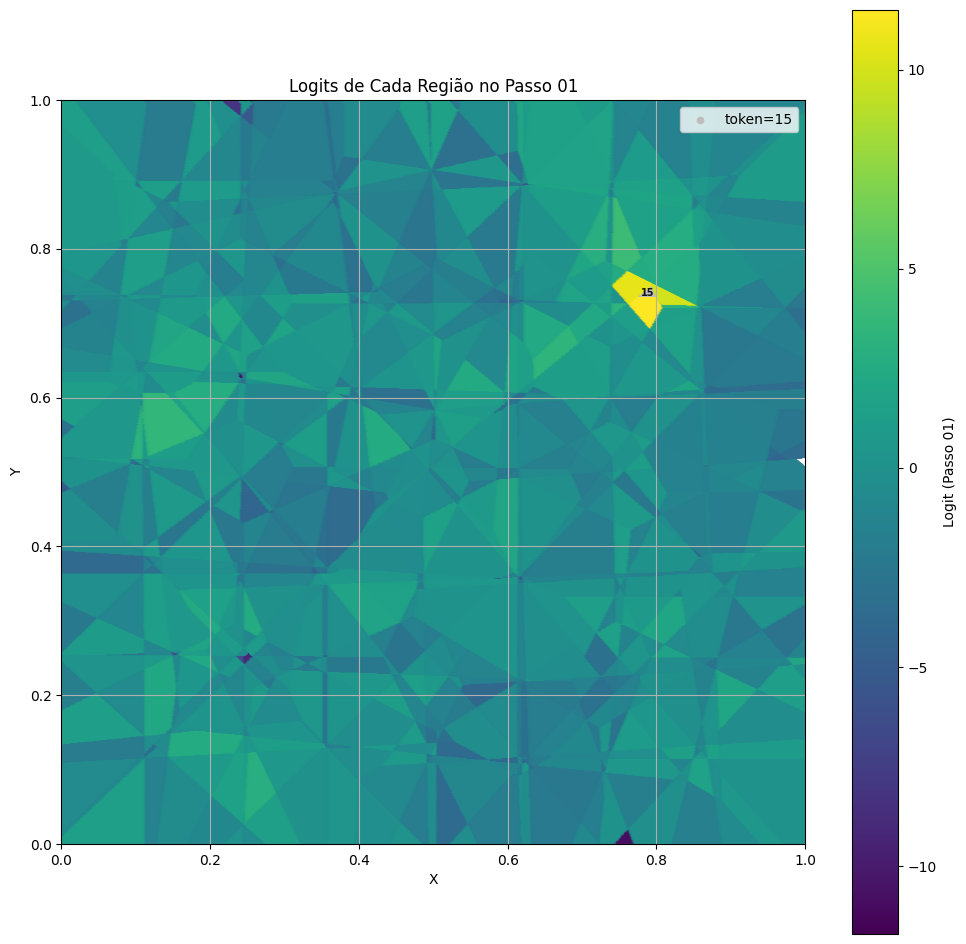

In [16]:
plot_logits_from_logits_df_w_pos(apd, distribs_logits, passo=0, token_atual=15)

In [85]:
distribs_logits.describe()

,Passo 01,Passo 02,Passo 03,Passo 04,Passo 05,Passo 06,Passo 07,Passo 08,Passo 09,Passo 10
count,948.000000,948.000000,948.000000,948.000000,948.000000,948.000000,948.000000,948.000000,948.000000,948.000000
mean,-0.791072,0.614037,-0.063351,0.201581,0.598120,0.633052,-0.445567,1.212842,1.212842,1.212842
std,8.139518,7.244642,7.214196,7.819971,7.564293,7.269515,7.845219,7.058315,7.058315,7.058315
min,-25.984743,-21.155283,-19.964338,-23.533283,-18.982740,-19.518433,-20.882362,-18.999651,-18.999651,-18.999651
25%,-6.311522,-4.218681,-4.985829,-5.451798,-4.575437,-4.353868,-5.977913,-3.578092,-3.578092,-3.578092
50%,-1.026146,0.763596,-0.094010,0.469261,0.473084,0.857549,-0.730815,1.093794,1.093794,1.093794
75%,4.825482,5.551798,5.127366,5.704403,6.052532,5.446939,4.743477,5.886080,5.886080,5.886080
max,25.292797,24.516903,21.598722,24.063732,24.767788,24.273556,22.876560,20.976965,20.976965,20.976965


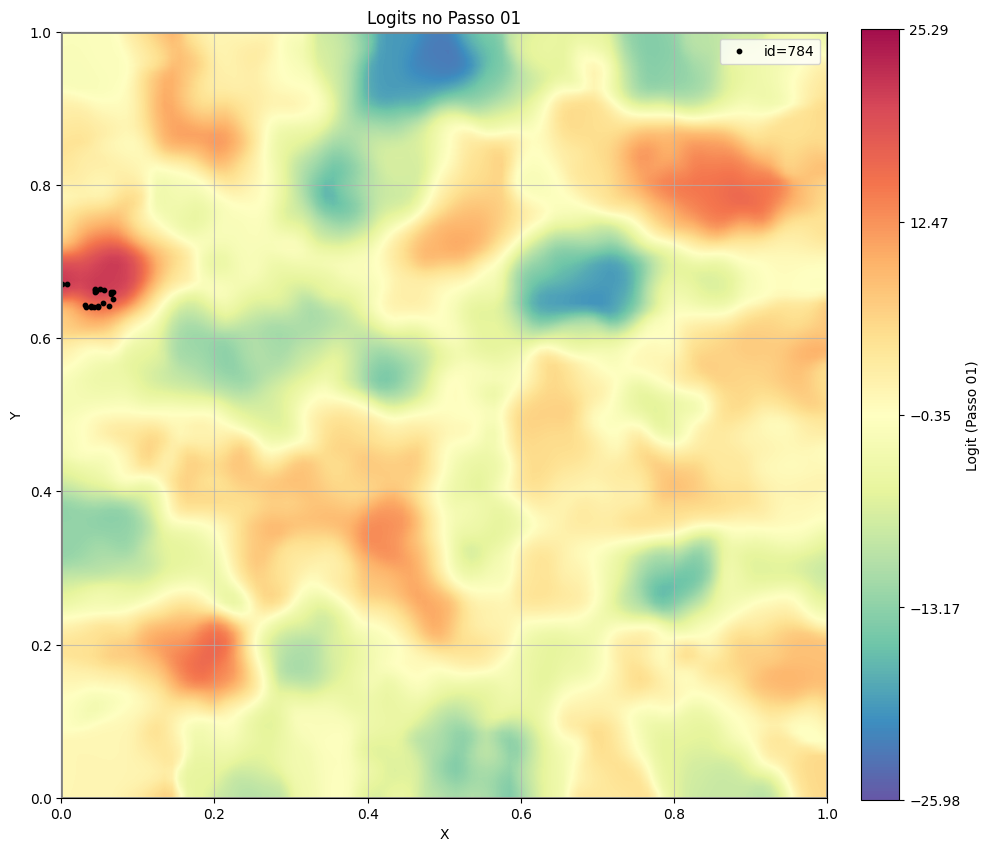

In [89]:
step_to_plot = 1
plot_next_id_logits_map_no_env(
    df_states=df,
    logits_df=distribs_logits,
    current_id=ids_sequence_list[step_to_plot-1],
    step=step_to_plot,
    cmap="Spectral_r",
    smooth_sigma=0.015,
    grid_size=100,
    logit_power=1.,
    current_color="k",
    current_size=10,
    current_alpha=1,
    show_current_label=False,
    center_colormap_at_zero=False,
)
plt.show()

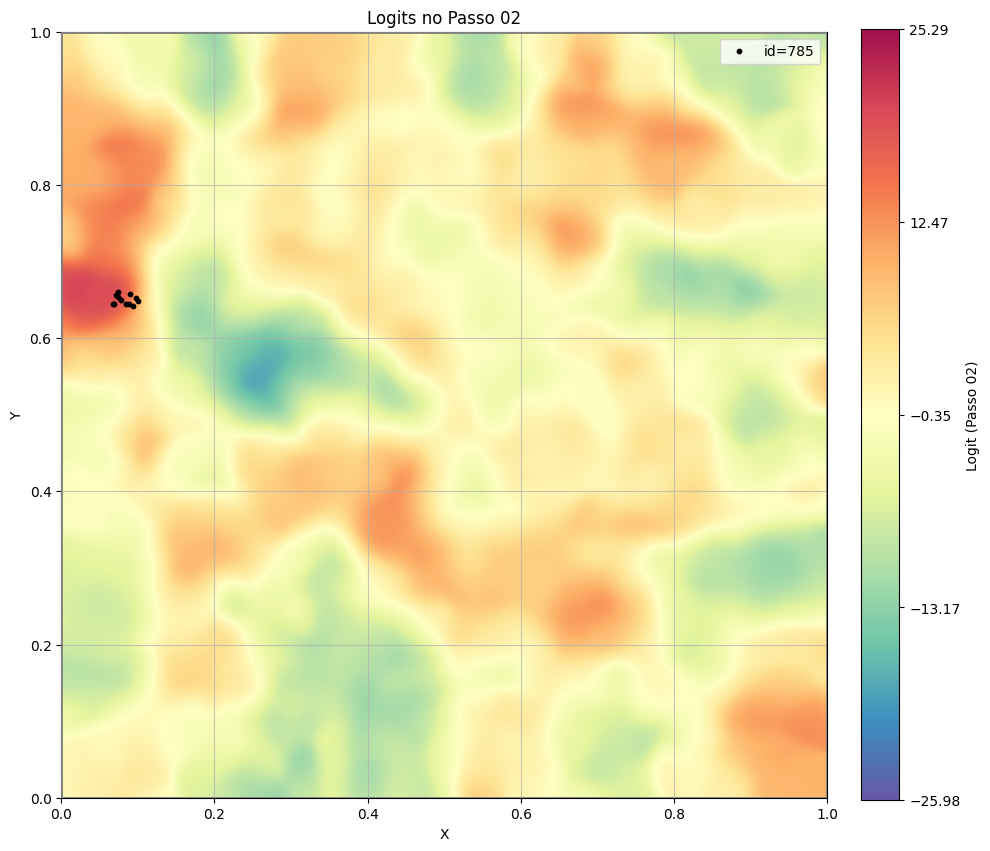

In [90]:
step_to_plot = 2
plot_next_id_logits_map_no_env(
    df_states=df,
    logits_df=distribs_logits,
    current_id=ids_sequence_list[step_to_plot-1],
    step=step_to_plot,
    cmap="Spectral_r",
    smooth_sigma=0.015,
    grid_size=100,
    logit_power=1.,
    current_color="k",
    current_size=10,
    current_alpha=1,
    show_current_label=False,
    center_colormap_at_zero=False,
)
plt.show()

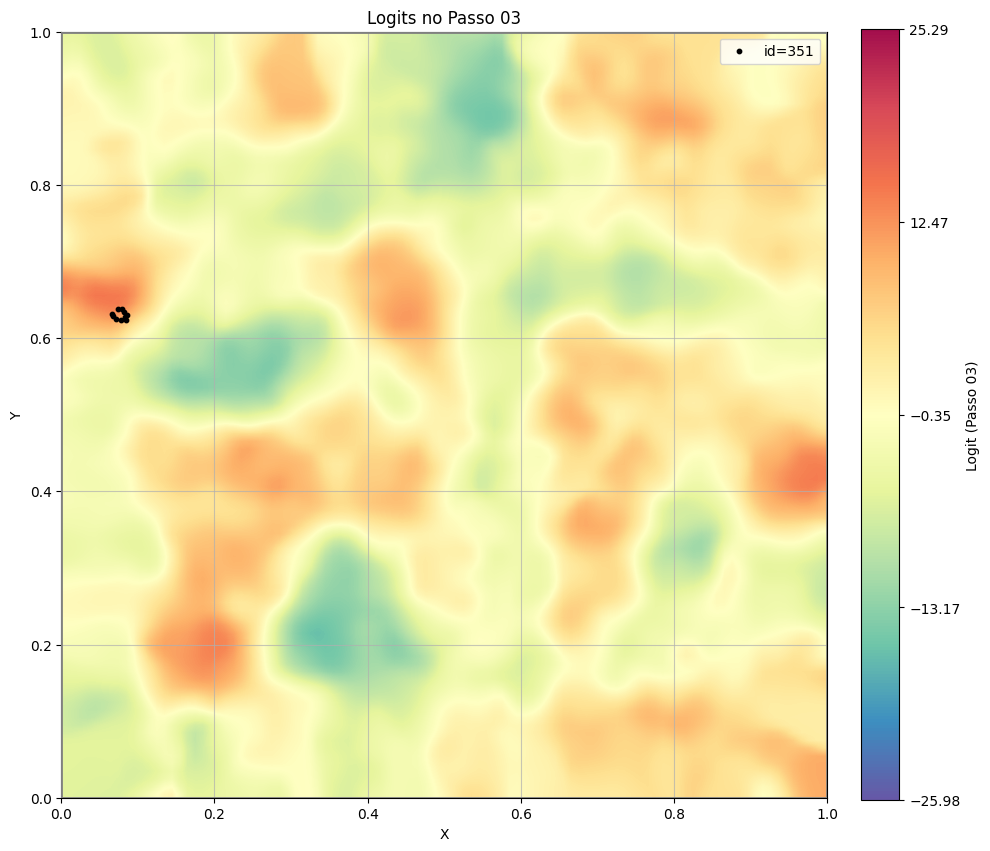

In [91]:
step_to_plot = 3
plot_next_id_logits_map_no_env(
    df_states=df,
    logits_df=distribs_logits,
    current_id=ids_sequence_list[step_to_plot-1],
    step=step_to_plot,
    cmap="Spectral_r",
    smooth_sigma=0.015,
    grid_size=100,
    logit_power=1.,
    current_color="k",
    current_size=10,
    current_alpha=1,
    show_current_label=False,
    center_colormap_at_zero=False,
)
plt.show()

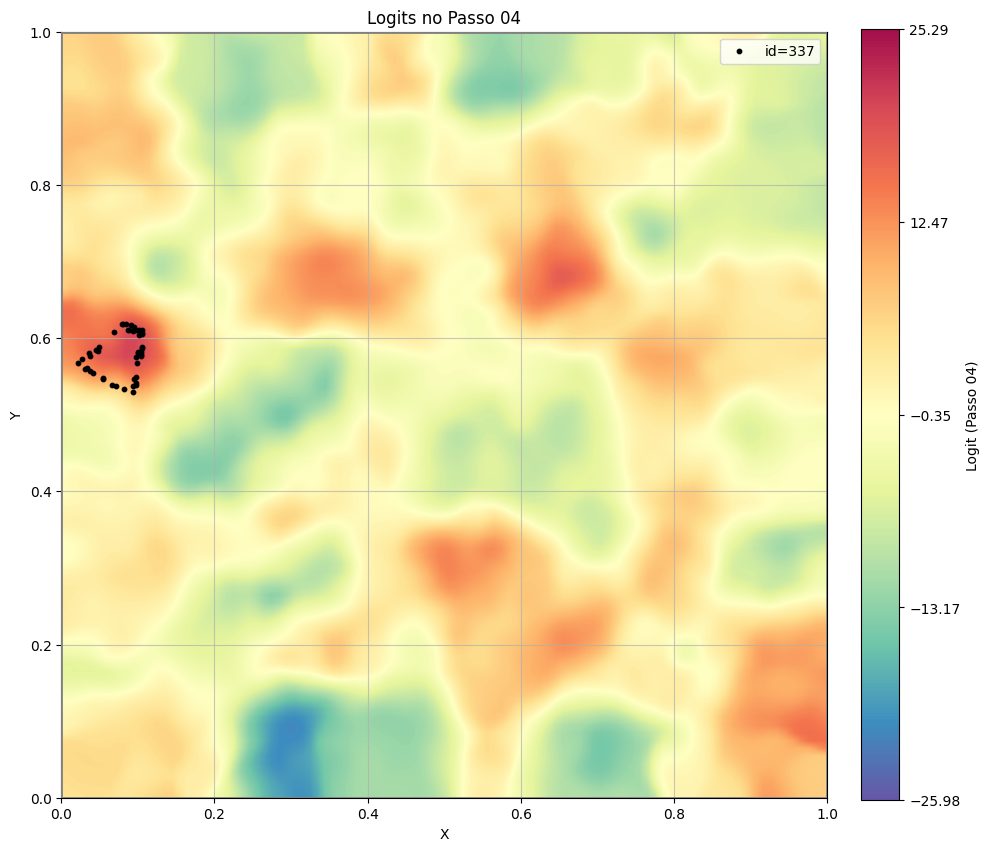

In [92]:
step_to_plot = 4
plot_next_id_logits_map_no_env(
    df_states=df,
    logits_df=distribs_logits,
    current_id=ids_sequence_list[step_to_plot-1],
    step=step_to_plot,
    cmap="Spectral_r",
    smooth_sigma=0.015,
    grid_size=100,
    logit_power=1.,
    current_color="k",
    current_size=10,
    current_alpha=1,
    show_current_label=False,
    center_colormap_at_zero=False,
)
plt.show()

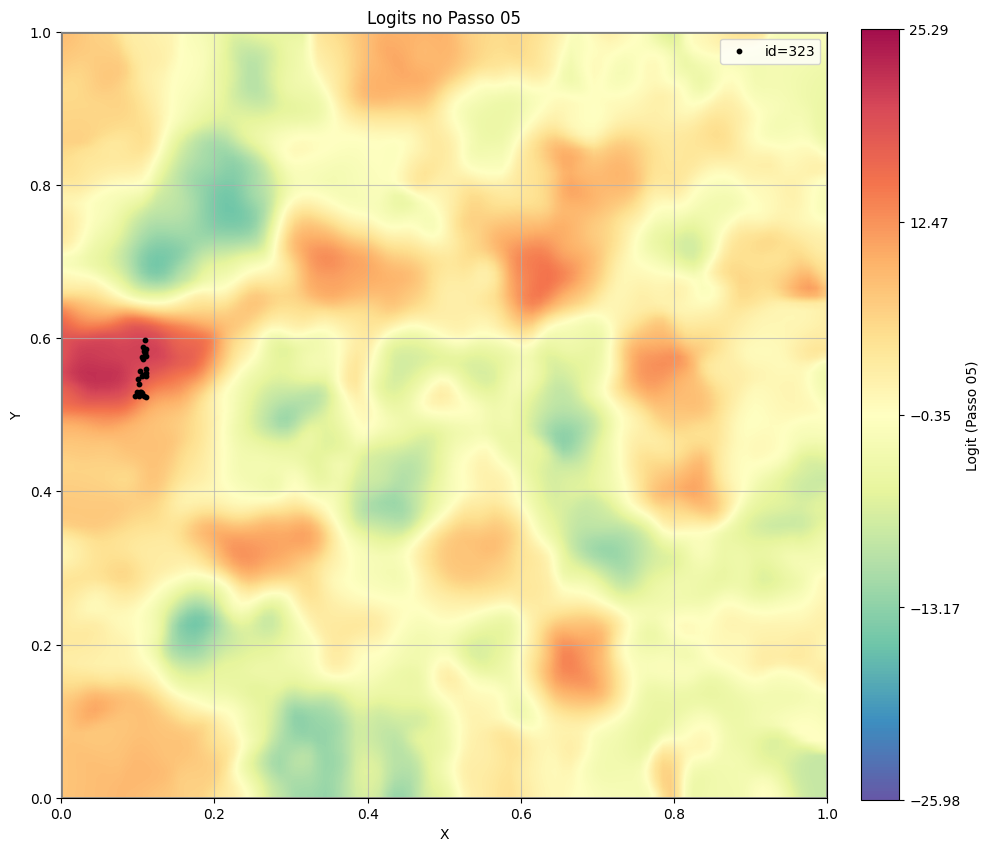

In [93]:
step_to_plot = 5
plot_next_id_logits_map_no_env(
    df_states=df,
    logits_df=distribs_logits,
    current_id=ids_sequence_list[step_to_plot-1],
    step=step_to_plot,
    cmap="Spectral_r",
    smooth_sigma=0.015,
    grid_size=100,
    logit_power=1.,
    current_color="k",
    current_size=10,
    current_alpha=1,
    show_current_label=False,
    center_colormap_at_zero=False,
)
plt.show()

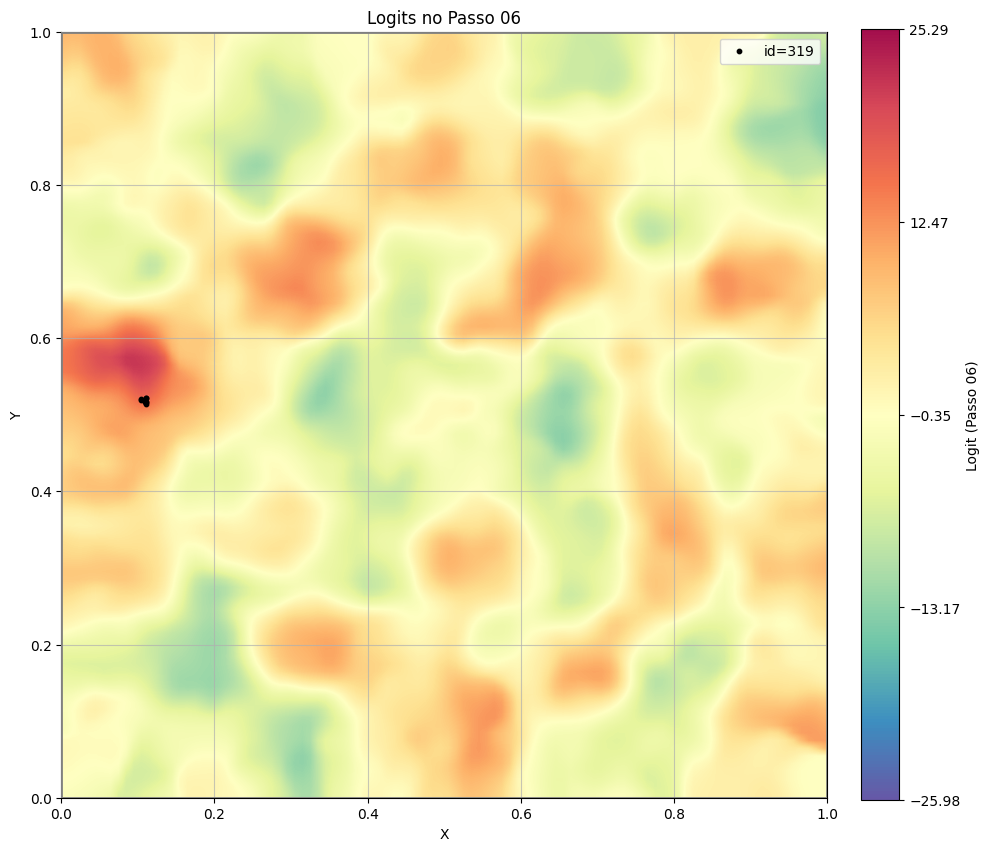

In [94]:
step_to_plot = 6
plot_next_id_logits_map_no_env(
    df_states=df,
    logits_df=distribs_logits,
    current_id=ids_sequence_list[step_to_plot-1],
    step=step_to_plot,
    cmap="Spectral_r",
    smooth_sigma=0.015,
    grid_size=100,
    logit_power=1.,
    current_color="k",
    current_size=10,
    current_alpha=1,
    show_current_label=False,
    center_colormap_at_zero=False,
)
plt.show()

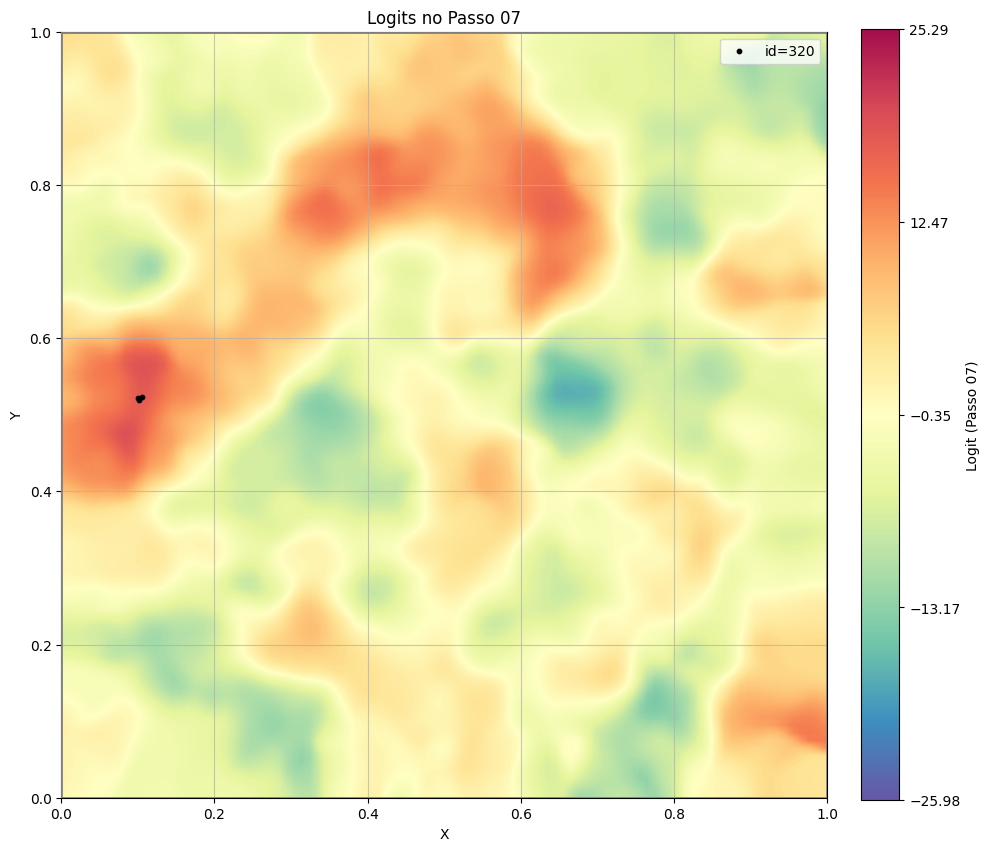

In [95]:
step_to_plot = 7
plot_next_id_logits_map_no_env(
    df_states=df,
    logits_df=distribs_logits,
    current_id=ids_sequence_list[step_to_plot-1],
    step=step_to_plot,
    cmap="Spectral_r",
    smooth_sigma=0.015,
    grid_size=100,
    logit_power=1.,
    current_color="k",
    current_size=10,
    current_alpha=1,
    show_current_label=False,
    center_colormap_at_zero=False,
)
plt.show()

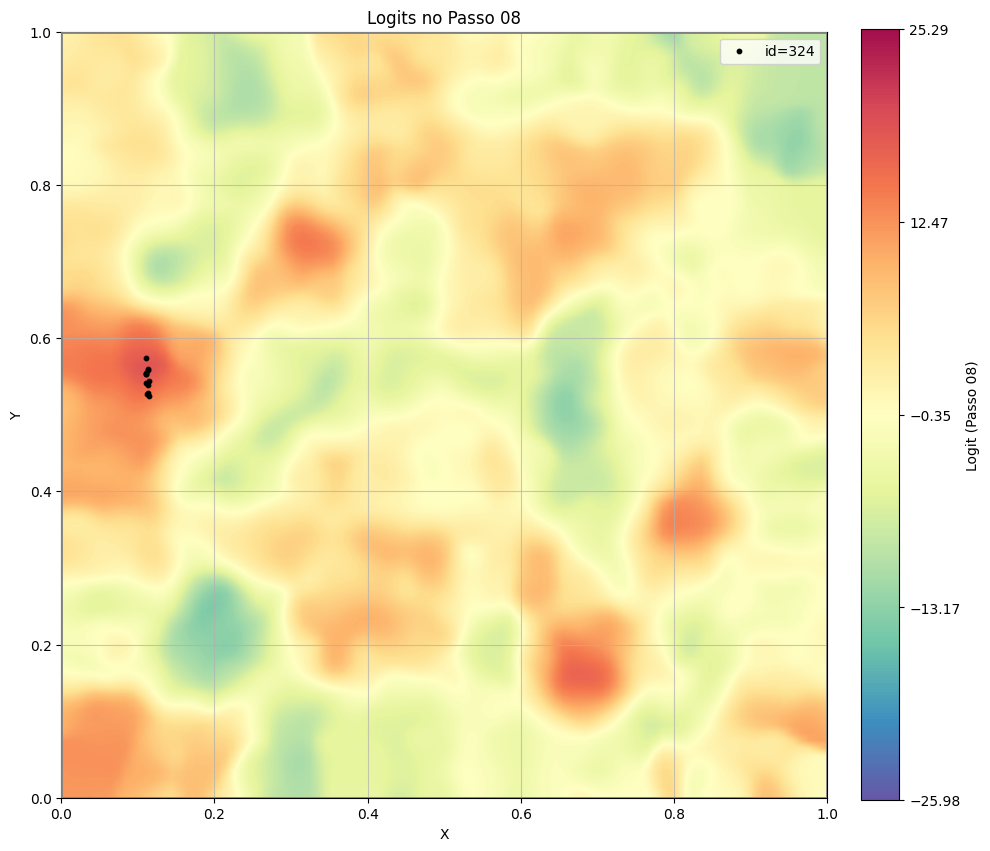

In [96]:
step_to_plot = 8
plot_next_id_logits_map_no_env(
    df_states=df,
    logits_df=distribs_logits,
    current_id=ids_sequence_list[step_to_plot-1],
    step=step_to_plot,
    cmap="Spectral_r",
    smooth_sigma=0.015,
    grid_size=100,
    logit_power=1.,
    current_color="k",
    current_size=10,
    current_alpha=1,
    show_current_label=False,
    center_colormap_at_zero=False,
)
plt.show()

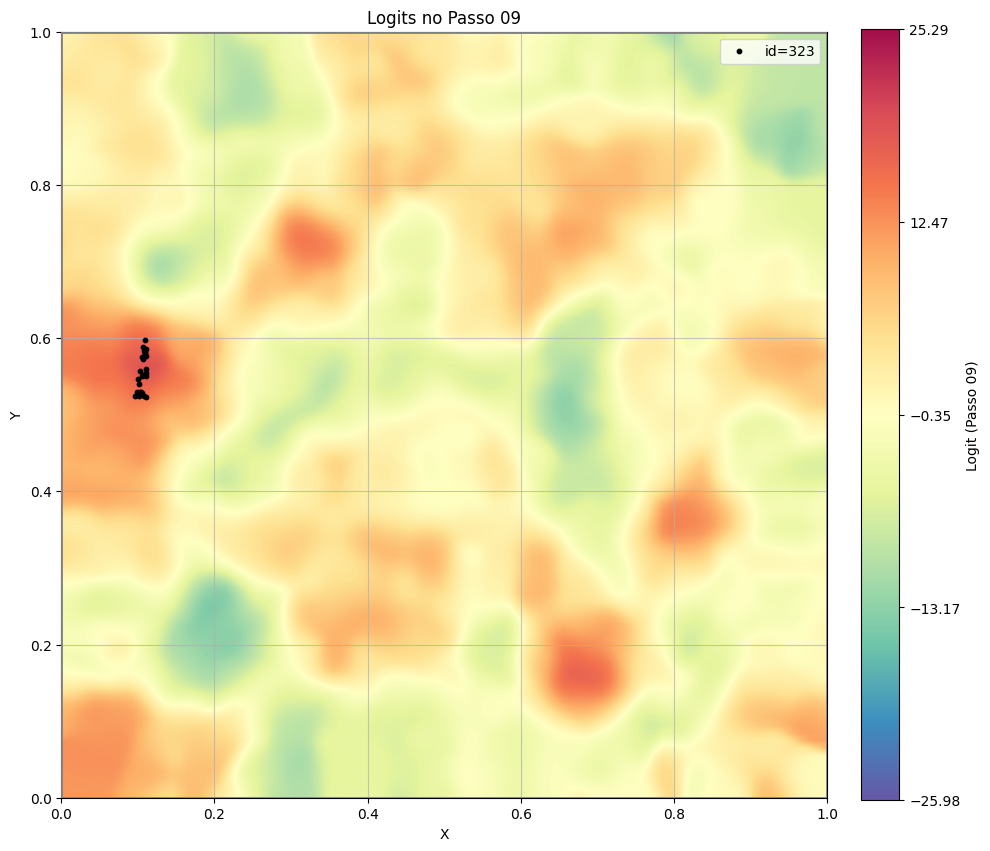

In [97]:
step_to_plot = 9
plot_next_id_logits_map_no_env(
    df_states=df,
    logits_df=distribs_logits,
    current_id=ids_sequence_list[step_to_plot-1],
    step=step_to_plot,
    cmap="Spectral_r",
    smooth_sigma=0.015,
    grid_size=100,
    logit_power=1.,
    current_color="k",
    current_size=10,
    current_alpha=1,
    show_current_label=False,
    center_colormap_at_zero=False,
)
plt.show()

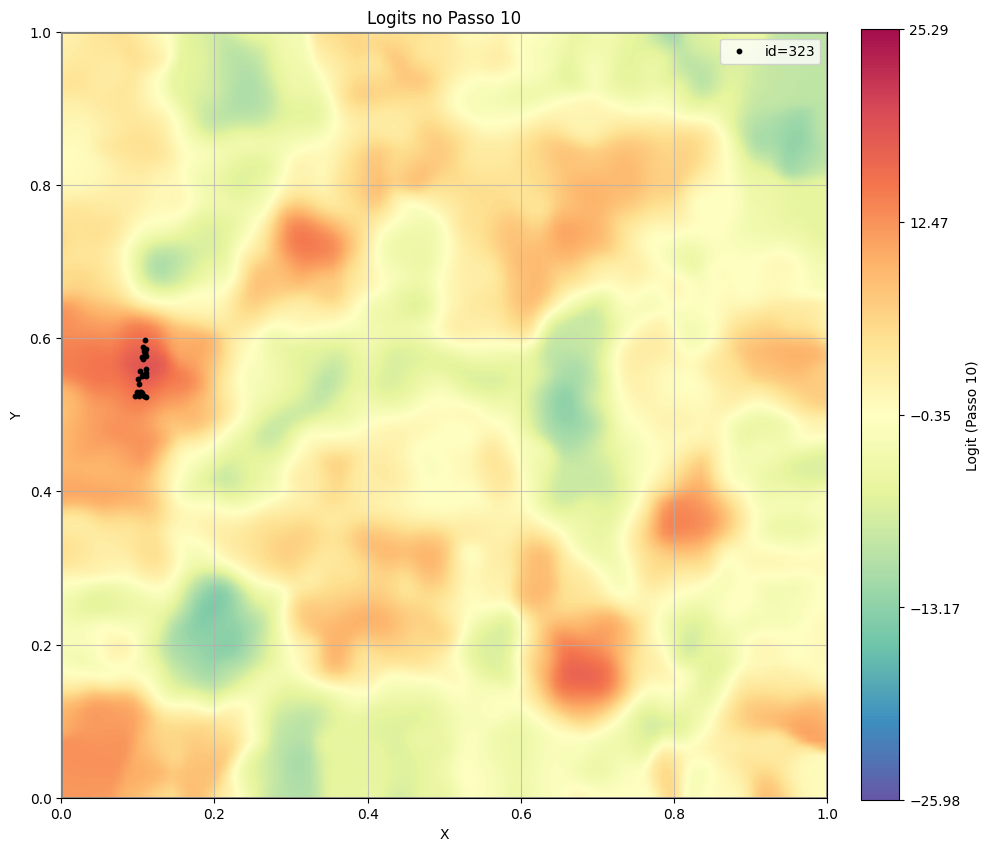

In [98]:
step_to_plot = 10
plot_next_id_logits_map_no_env(
    df_states=df,
    logits_df=distribs_logits,
    current_id=ids_sequence_list[step_to_plot-1],
    step=step_to_plot,
    cmap="Spectral_r",
    smooth_sigma=0.015,
    grid_size=100,
    logit_power=1.,
    current_color="k",
    current_size=10,
    current_alpha=1,
    show_current_label=False,
    center_colormap_at_zero=False,
)
plt.show()

## Raw Logits

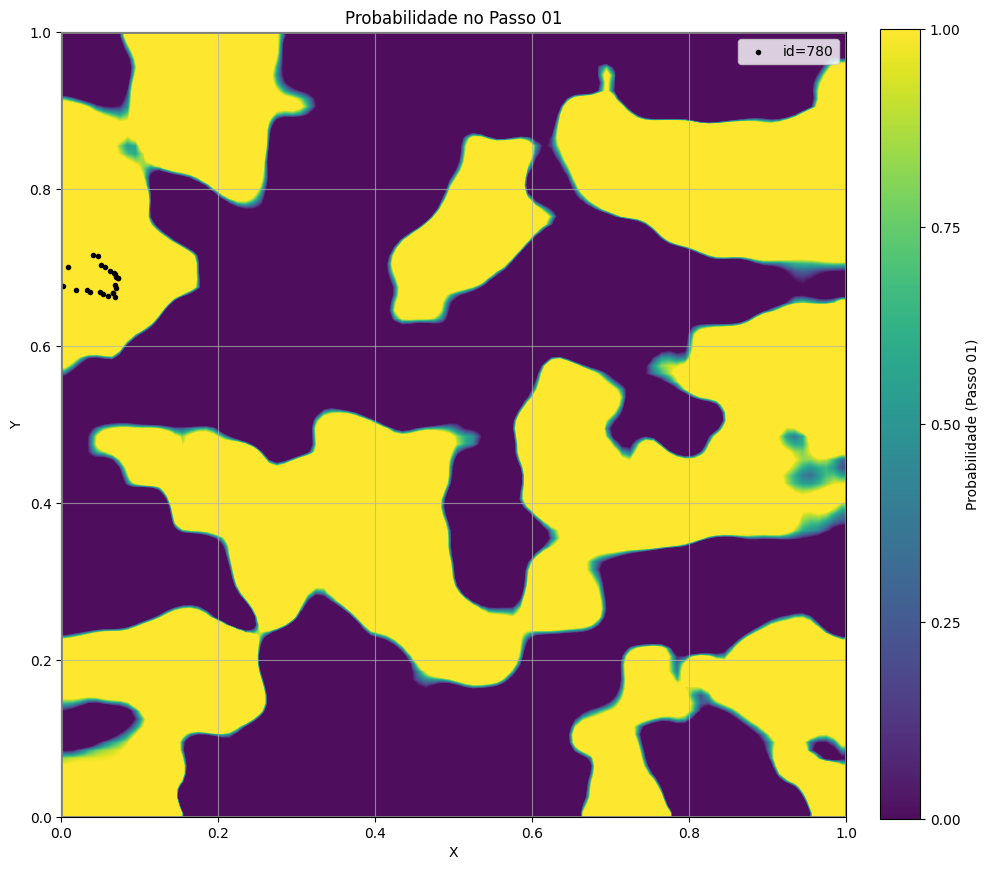

(<Figure size 1000x1000 with 2 Axes>,
 <Axes: title={'center': 'Probabilidade no Passo 01'}, xlabel='X', ylabel='Y'>)

In [22]:
plot_next_id_probability_map_no_env(
    df_states=df,
    probs_df=distribs_raw_logits,
    current_id=780,
    step="Passo 01",
    cmap="viridis",
    smooth_sigma=0.015,
    grid_size=100,
    prob_power=1.0,
    current_color="k",
    current_size=10,
    current_alpha=1,
    show_current_label=False,
)

# Smoothed Prob

In [32]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

def compute_prob_grid_from_apd(
    apd: pd.DataFrame,
    probs_df: pd.DataFrame,     # index: token_id (int ou str numérica), columns: "Passo 01", ...
    passo,                      # str ("Passo 04") OU int (0 = primeira coluna)
    resolucao: float = 0.01,    # tamanho da célula em X e Y
    plot_heat: bool = True,
    cmap: str = "viridis",
    alpha: float = 1.0,
    title: str = None,
):
    """
    Cria uma grade (x,y) com 'resolucao' (ex.: 0.01 -> 100x100 células).
    Para cada célula, busca os pontos de 'apd' que caem nela, usa seus tokens
    (position_state_id) para mapear as probabilidades em 'probs_df[passo]' e
    calcula a MÉDIA dessas probabilidades. Retorna o array 'heat' e um DataFrame
    com o resumo por célula. Opcionalmente plota um heatmap.

    Retorna:
      heat: np.ndarray shape (nb, nb) com médias por célula (NaN se vazia)
      cells_df: DataFrame com colunas:
        ['xbin','ybin','x0','x1','y0','y1','mean_prob','count']
    """
    # --- saneamento: índice de probs_df como int
    def _to_int_index(df: pd.DataFrame) -> pd.DataFrame:
        if not np.issubdtype(df.index.dtype, np.integer):
            df = df.copy()
            df.index = df.index.astype(int)
        return df

    probs_df = _to_int_index(probs_df)

    # checagens
    req = {"X","Y","position_state_id"}
    if not req.issubset(apd.columns):
        raise ValueError(f"'apd' precisa conter {req}")

    # resolve coluna do passo
    col = probs_df.columns[passo] if isinstance(passo, int) else passo
    if col not in probs_df.columns:
        raise ValueError(f"Coluna '{col}' não encontrada em probs_df")

    # mapeia prob do passo para cada linha do apd
    prob_series = probs_df[col]  # index = token_id
    ap = apd.copy()
    ap["prob"] = ap["position_state_id"].map(prob_series)

    # define número de bins por eixo
    nb = max(int(round(1.0 / float(resolucao))), 1)
    # bin edges (0, resolucao, 2*resolucao, ..., 1)
    # garantimos que o topo seja exatamente 1.0
    x_edges = np.linspace(0.0, 1.0, nb+1)
    y_edges = np.linspace(0.0, 1.0, nb+1)

    # calcula índices de bin (0..nb-1) para cada ponto
    eps = 1e-12
    ix = np.floor(np.clip(ap["X"].to_numpy(), 0, 1 - eps) * nb).astype(int)
    iy = np.floor(np.clip(ap["Y"].to_numpy(), 0, 1 - eps) * nb).astype(int)

    # agregação: média por (ix,iy), ignorando NaN
    # (usamos dicts para somar/contar e depois “loopamos” sobre todas as células)
    sum_grid = {}
    cnt_grid = {}
    probs_vals = ap["prob"].to_numpy()
    for xb, yb, p in zip(ix, iy, probs_vals):
        if np.isnan(p):
            continue
        key = (xb, yb)
        sum_grid[key] = sum_grid.get(key, 0.0) + float(p)
        cnt_grid[key] = cnt_grid.get(key, 0) + 1

    # constrói heatmap (nb x nb) e DataFrame de células
    heat = np.full((nb, nb), np.nan, dtype=float)
    rows = []
    for xb in range(nb):
        for yb in range(nb):
            x0, x1 = x_edges[xb], x_edges[xb+1]
            y0, y1 = y_edges[yb], y_edges[yb+1]
            key = (xb, yb)
            if key in cnt_grid:
                mean_p = sum_grid[key] / cnt_grid[key]
                heat[xb, yb] = mean_p
                rows.append({
                    "xbin": xb, "ybin": yb,
                    "x0": x0, "x1": x1, "y0": y0, "y1": y1,
                    "mean_prob": mean_p,
                    "count": cnt_grid[key],
                })
            else:
                rows.append({
                    "xbin": xb, "ybin": yb,
                    "x0": x0, "x1": x1, "y0": y0, "y1": y1,
                    "mean_prob": 0,
                    "count": 0,
                })

    cells_df = pd.DataFrame(rows)
    # plot opcional
    if plot_heat:
        plt.figure(figsize=(12, 12))
        # heat está como [x,y]; transpor para alinhar eixos no imshow
        data = np.nan_to_num(heat.T, nan=0.0)
        im = plt.imshow(
            data,
            origin="lower",
            extent=[0, 1, 0, 1],
            cmap=cmap,
            alpha=alpha,
            interpolation="nearest",
            aspect="equal",
            vmin=0.0
        )
        cbar = plt.colorbar(im)
        cbar.set_label(f"Média de Probabilidade por célula ({col}, {resolucao:.3f}×{resolucao:.3f})")
        plt.xlabel("X"); plt.ylabel("Y")
        plt.title(title or f"Média de prob por célula — {col}")
        plt.xlim(0, 1); plt.ylim(0, 1)
        plt.grid(True, alpha=0.3)
        plt.gca().set_aspect("equal", adjustable="box")
        plt.show()

    return heat, cells_df


In [ ]:
plot_next_id_probability_map_no_env(
    df_states=df,
    probs_df=distribs_logits,
    current_id=780,
    step="Passo 01",
    cmap="viridis",
    smooth_sigma=0.015,
    grid_size=100,
    prob_power=1.0,
    current_color="k",
    current_size=10,
    current_alpha=1,
    show_current_label=False,
)

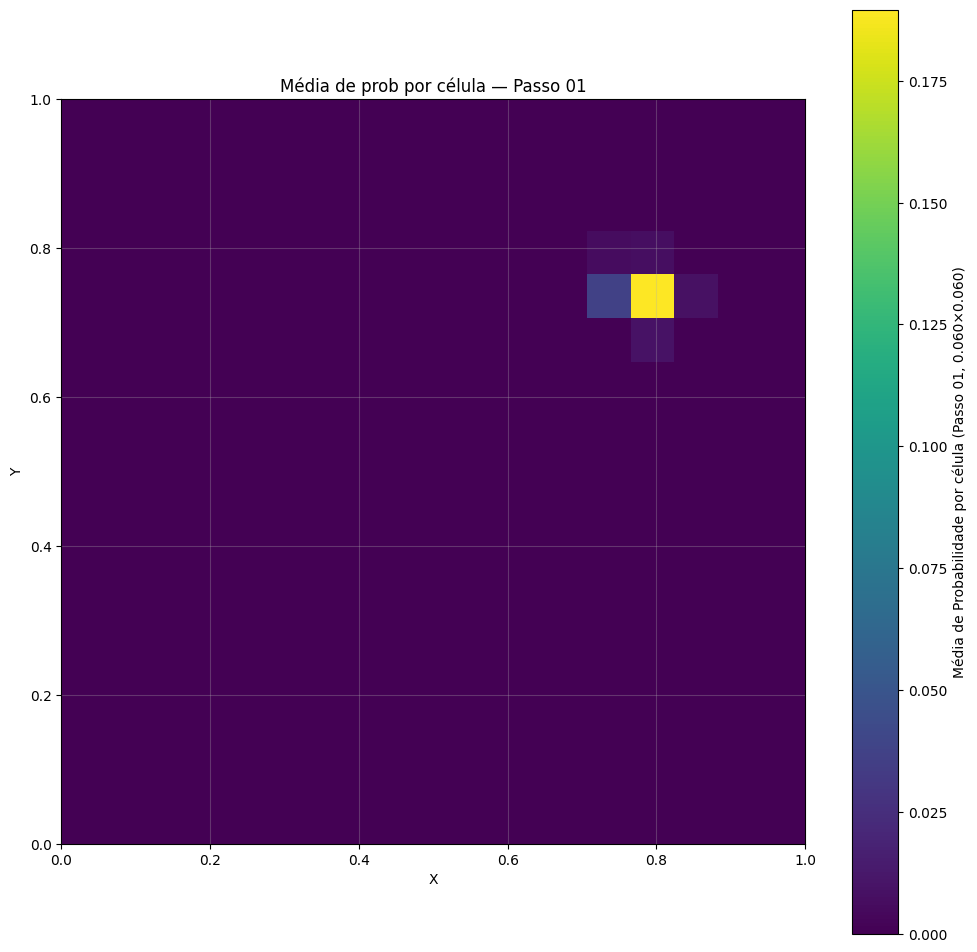

In [33]:
heat, cells = compute_prob_grid_from_apd(
    apd=apd,
    probs_df=distribs_probs,
    passo=0,
    resolucao=0.06,    # grade 0.01 x 0.01
    plot_heat=True,    # mostra o heatmap
)

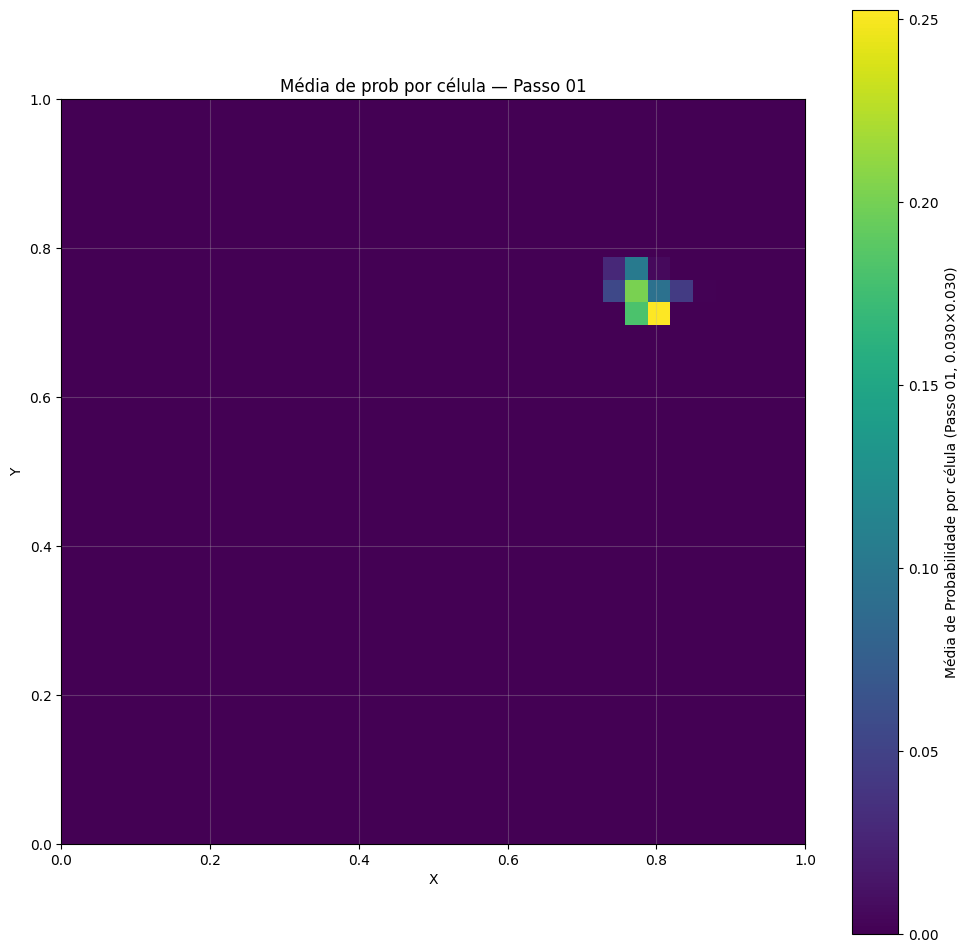

In [34]:
heat, cells = compute_prob_grid_from_apd(
    apd=apd,
    probs_df=distribs_probs,
    passo=0,
    resolucao=0.03,    # grade 0.01 x 0.01
    plot_heat=True,    # mostra o heatmap
)

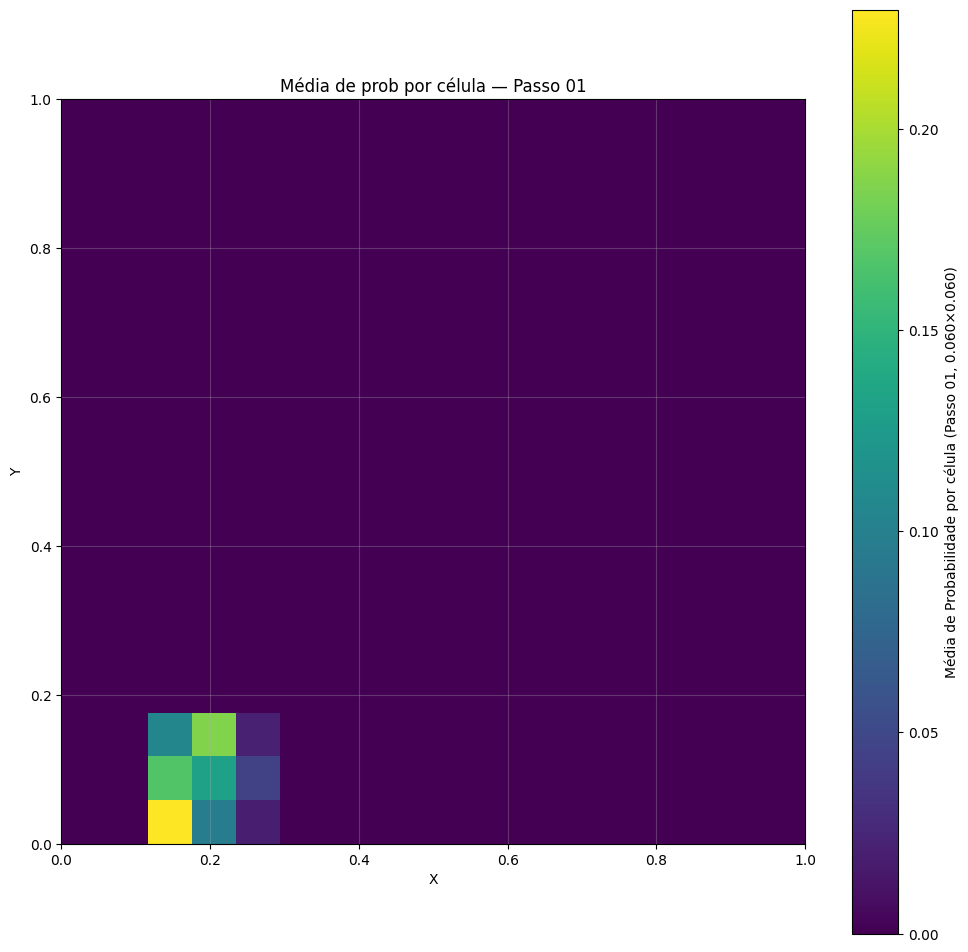

In [69]:
heat, cells = compute_prob_grid_from_apd(
    apd=apd,
    probs_df=distribs_probs705,
    passo=0,
    resolucao=0.06,    # grade 0.01 x 0.01
    plot_heat=True,    # mostra o heatmap
)

In [46]:
distribs_probs360.head()

,Passo 01,Passo 02,Passo 03,Passo 04,Passo 05,Passo 06,Passo 07,Passo 08,Passo 09,Passo 10
0,5.094085e-02,3.627287e-04,1.607952e-02,1.300018e-02,2.206405e-02,8.030681e-04,1.948648e-02,5.148364e-02,1.381824e-02,2.150521e-04
1,3.102613e-02,8.552221e-05,1.464076e-04,2.767104e-04,2.014431e-07,7.836235e-06,1.765294e-07,3.044495e-02,1.012906e-04,1.249426e-05
2,9.633141e-03,1.152708e-05,8.613528e-04,2.709543e-06,1.548966e-05,4.153767e-06,1.306190e-05,7.898827e-03,1.022233e-06,4.238227e-05
3,3.386858e-06,1.963006e-09,1.335242e-09,1.682392e-09,6.370573e-09,1.046439e-08,5.449544e-09,1.918643e-06,5.666950e-10,1.022897e-08
4,3.194039e-07,5.624925e-07,2.263030e-08,1.327093e-08,4.556331e-11,4.938668e-07,3.989805e-11,2.721142e-07,4.806600e-09,3.608924e-11


In [48]:
df.head()

,t,pos,distance_travelled,vel,rot_vel,head_direction,position_state,position_state_id,normalized_position_state_id,last_position_state_id,change_of_position_state
0,0.20,"[0.533, 0.759]",0.013482,"[-0.029813505745424074, -0.03024226306685973]",-0.858923,"[-0.8225952267687777, -0.5686273761411977]",MOWWCEPVCCOOAAAAAAAA,260,0.455342,258.0,1
1,0.80,"[0.509, 0.746]",0.040934,"[-0.018087799850172726, -0.00021248426324893543]",-2.125735,"[-0.9845667997880629, -0.17500919048750666]",MOWWCEPVAAAAAAAAAAAA,258,0.451839,260.0,1
2,1.25,"[0.497, 0.747]",0.052860,"[-0.022254431192847424, 0.005548653260900593]",-0.093818,"[-0.9845304158280958, 0.1752137560505934]",CEPVAAAAAAAAAAAAAAAA,74,0.129597,258.0,1
3,2.00,"[0.475, 0.743]",0.076841,"[-0.019586472739845373, -0.02076018939175306]",4.177319,"[-0.8405132019727286, -0.5417910642577553]",CEPVCCOOAAAAAAAAAAAA,75,0.131349,74.0,1
4,2.30,"[0.467, 0.741]",0.084759,"[-0.03166088667862943, -0.0006559898094282701]",-0.642504,"[-0.9699878362159112, -0.2431534445431004]",CEPVAAAAAAAAAAAAAAAA,74,0.129597,75.0,1


# FIM